# EPtask / MEPPO — replication (v5)

Replication of Li et al., *EPtask: DRL Based Energy-Efficient and Priority-Aware
Task Scheduling for Dynamic Vehicular Edge Computing*, IEEE T-IV 9(1), 2024.

**Scope:** software + simulation only. The Section VI on-site robotic test is out
of scope by design, and nothing in Sections III–V requires hardware.

---

## What v5 adds, and why it matters

v4 was a faithful implementation. v5 is the audit of it. Four measurements
changed the conclusions, and each is reproducible from section 10.

| # | Finding | Evidence | Fix |
|---|---|---|---|
| **1** | **The Eq. (25) reward does not measure the objective.** It normalises by `max_T` / `max_E`, the largest values *ever reached* — hidden, monotone, non-stationary. The reward therefore rises on its own. | Frozen random policy: the time penalty decays **1.7×** over 3000 steps with no learning. Trained 40 episodes: reward **+25%** while completion time got **39.5% worse**; corr(reward, −T) = **−0.83**. | `REWARD_MODE = "local_ratio"`: normalise each request against its own Local-only cost, i.e. `r = α·TS + β·ES` — the paper's own Eq. (32). Result: corr(reward, −T) = **+0.98**, time **−23%**. |
| **2** | **Global precedence was decided by request size.** v4 mapped n ranks onto levels `0..n−1`, so a 1-task request was pinned to level 0 forever while a 10-task request's median task outranked every task of every small request. | D2 | `PRIORITY_MAP = "rank_spread"` spreads n ranks over the full 0–9 range. |
| **3** | **Reported completion time never charges preemption.** T is estimated at arrival; a later high-priority arrival delays that queued work and the estimate is never revised. The bias is **3.3–5.7% with priority on** but only **0.1–1.0% with it off** — systematically in favour of the paper's contribution. | D3 | `TRACK_TRUE_T` keeps per-task records and charges every preemption exactly. |
| **4** | **The priority mechanism cannot work here, structurally.** Eq. (13)'s execution queue is the only queue priority governs, and it is **14.8% of the critical path at V=10, falling to 2.4% at V=50**. Eq. (12)'s transmission queue — 64% of the path at V=50 — is FIFO by definition. | D4, D5 | See §10.6. No repair recovers Fig. 11. |

**Consequence for the report.** Fig. 10 (offloading + power) reproduces. Fig. 11
(priority) does **not**: under honest accounting *no* priority discipline —
random, LPT, SPT, or global-SPT — beats FIFO, losing 1.2–6.1%, while the
reported metric shows LPT gaining +1.5–2.7%. The paper claims the benefit grows
with vehicle count; the mechanism's leverage in fact *shrinks* from 14.8% to
2.4% as congestion rises, because congestion pushes the bottleneck further into
the FIFO transmission queue.

This is a negative result about one of three contributions, obtained from the
paper's own equations at the paper's own Table III parameters. Report it as
such — it is worth far more than a figure that agrees for the wrong reason.

---

## Carried over from v4 (still true)

| # | Correction | Why |
|---|---|---|
| 1 | `T = max(finish) − now`, not a sum | Eq. (18) is a max over entities; summing erases the parallelism the paper is about. |
| 2 | Separate **transmission** and **priority execution** queues | Eq. (12)/(13) are two distinct queues. |
| 3 | `P_max = 1 dBm` (Table III), road **scaled to `d_max`** | Inflating power by 30 dB to reach a preset road length inverts Fig. 10(b). |
| 4 | `ξ = 1e-11` (Table III) with **f in GHz** → 2–20 mJ/task | Table III does specify ξ; it only makes sense in GHz. |
| 5 | Baselines scored by `peek()` on the same request, plus independent rollouts | Otherwise MEPPO on vehicle *i* is compared against baselines on vehicle *i+1*. |
| 6 | `η_i = 1/N_r` bandwidth share (Eq. 6) | Edge congestion was otherwise invisible to the agent. |
| 7 | Eq. (25)'s sign corrected | As printed, the reward *increases* with time and energy. |
| 8 | Eq. (22) implemented as `min`, not `max` | It scores normalised distance and workload; both must be minimised. |
| 9 | 5 vehicle-count configs trained simultaneously via grouped `bmm` | ~35 min instead of ~3 h, with a gradient-isolation test in §2. |

---

## The three unit ambiguities in Table III

Table III has had its scientific-notation exponents stripped by typesetting
("2 cpu cycles/s" is not a CPU frequency). Three readings must be fixed, and
there is exactly one set that is simultaneously self-consistent **and**
reproduces the paper's own Fig. 10 orderings with no parameters left to tune:

1. **Eq. (20) path loss.** The constant `32.4` belongs to the standard
   `FSPL = 32.44 + 20·lg(d_km) + 20·lg(f_MHz)` calibration. The paper's text says
   "d in m", which is off by 60 dB and gives the notorious 4 cm range.
   → **d in km, f in MHz → `d_max = 43.6 m` from Table III verbatim.**
2. **Spatial scale.** 8 RSUs at 1.6·`d_max` spacing ⇒ a ~560 m corridor. Short,
   but it is the only value consistent with Table III's radio budget.
3. **Eq. (10) energy.** `ξ = 1e-11`, `γ = 2`, **f in GHz** ⇒ 2–20 mJ/task.

Everything else is Table III verbatim; anything absent from it is tagged
`ASSUMPTION` at its definition.

> **Verify Table III against your own copy of the PDF before your viva.** It is a
> low-quality scan and rows 4–6 (the stripped exponents) are exactly the ones an
> examiner will ask about.


---

## v6 note — Fig. 13 now pulls the *current* NYC traffic day, not a fixed month

`load_nyc_traffic()` used to hardcode the paper's own slice (STATE STREET,
19–25 Oct 2022). It now queries NYC OpenData for **whichever day is actually
the most recent one on the server** when you run the cell, not a specific
promised month. NYC DOT's traffic recorders sample streets on a rotating
schedule, so a *specific* street is not guaranteed to have a count from last
month — the fallback chain handles that honestly instead of pretending it does:

1. Latest well-sampled day for **STATE STREET** (the paper's own street) — used if found.
2. If STATE STREET has no recent day, latest well-sampled day **citywide** (any street) — used instead, and labelled as such.
3. If the network is unreachable at all, the stored Oct 2022 STATE STREET week — labelled `(offline fallback)` so it is never silently mistaken for current data.

Section 7's output cell prints exactly which of these fired and the exact date
fetched, e.g. `traffic source : live -- State Street, 2026-08-14`. Whatever
date prints there is what you should cite in the report — do not write
"August 2026" unless that is the date the notebook actually printed.


---

## v6 note — Section 11 adds three proposed extensions (the mini-project's own contribution)

Everything above (Sections 1–10) is the base-paper replication and its
audit — reproduce what the paper claims, then check whether the claims hold
up under measurement. **Section 11 adds three extensions proposed for this
project**, each targeting a gap the audit itself exposed or that the paper
leaves open:

- **C1 — Safety-integrity argument** (🛡️ safer): ASIL-inspired criticality
  tagging with a hardcoded, non-learned floor guaranteeing the highest class
  a protected outcome. Read §11's framing note before presenting this —
  it is explicitly **not** an ASIL-certification claim.
- **C2 — Explainability** (🧠 smarter): exact, `env.peek()`-based
  counterfactuals for any single scheduling decision, plus per-head
  confidence and entropy.
- **C3 — Node-failure resilience** (✅ more honest): a scripted edge-server
  outage measuring how the already-trained policy degrades and recovers,
  reusing the replication's own infeasibility-fallback machinery.

None of these change how MEPPO is trained. Run Sections 1–10 first (through
training), then run Section 11.


## 0 · Runtime setup

Runtime → Change runtime type → **T4 GPU** (free tier is fine).

Nothing needs installing: Colab ships with `torch`, `numpy` and `matplotlib`.
Set `USE_DRIVE = True` if you want checkpoints and figures written to Drive.

The code package always lives at a fixed local path, **`/content/eptask`**,
regardless of `USE_DRIVE` — only trained checkpoints, figures and JSON results
go to Drive. Code doesn't need to survive across sessions; it's rewritten by
the `%%writefile` cells below every time you run this notebook.

In [1]:
USE_DRIVE = False          # True -> persist checkpoints/figures to Google Drive
DRIVE_SUBDIR = "Sem_3_Mini_project/Base_paper_replica/EPTASK_v4"

import os, sys, subprocess, textwrap

PKG = "/content/eptask"                  # always local -- see note above
os.makedirs(PKG, exist_ok=True)
if PKG not in sys.path:
    sys.path.insert(0, PKG)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS = f"/content/drive/MyDrive/{DRIVE_SUBDIR}/results"
else:
    RESULTS = "/content/EPTASK_v4/results"
os.makedirs(RESULTS, exist_ok=True)

import torch
print("torch", torch.__version__, "| CUDA", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("package dir:", PKG)
print("results dir:", RESULTS)

torch 2.14.0+cpu | CUDA False | CPU only
package dir: /content/eptask
results dir: /content/EPTASK_v4/results


## 1 · The modules

Each cell below is a `%%writefile` cell: everything after the first line is
written to disk **exactly as shown** (this is a Jupyter/Colab cell magic, not
a Python string, so triple-quoted docstrings inside the code are not a
problem). Run each one — you'll see the real source, and "Overwriting
/content/eptask/xyz.py" printed underneath.

Read the docstrings as you go — every design decision names the equation or
section it implements, and every departure from the paper is labelled as
such rather than left implicit.

### `config.py`

In [2]:
%%writefile /content/eptask/config.py
"""
EPtask / MEPPO replication -- config.py  (v4, audited against Table III at 900 dpi)

EVERY numeric value below is either (a) verbatim from Table III, or (b) explicitly
tagged ASSUMPTION with the reason. No silent parameter tuning.

--------------------------------------------------------------------------
TABLE III AS PRINTED (23 rows, transcribed from a 900 dpi render of p.1841)
--------------------------------------------------------------------------
  Number of vehicles ................. 10-50
  Number of edge servers ............. 8
  Number of tasks .................... 0-10
  Required CPU cycles of the tasks C.. 2-20 cpu cycles      <-- exponent stripped
  Computation power of edge servers .. 2 cpu cycles/s       <-- exponent stripped
  Computation power of vehicles ...... 1 cpu cycles/s       <-- exponent stripped
  data size S ........................ 2-20 Mb
  Bandwidth of edge server ........... 100 MHz
  Speed of vehicles .................. ~ 25 m/s
  Transmit power of vehicles ......... 1 dBm
  Execution power of vehicles ........ 3-4 dBm
  White Gaussian noise ............... -174 dBm/Hz
  Power consumption coefficient xi ... 10^-11
  Power consumption coefficient gamma. 2
  RSSI ............................... -65 dBm
  Transmit antenna gain TX ........... 20 dBi
  Receive antenna gain RX ............ -8 dBi
  Signal attenuation SA .............. 7 dB
  Working frequency f ................ 5 GHz
  Learning rate ...................... 0.0003
  Size of Mini-batch ................. 32
  Number of steps in each episode .... 2048
  Entropy loss coefficient ........... 0.01

NOT in Table III (hence ASSUMPTION): cloud CPU frequency, vehicle bandwidth,
discount factor, clip epsilon, GAE lambda, K epochs, highway length, number of
episodes (taken from Fig. 9's x-axis, which runs to ~1000).

--------------------------------------------------------------------------
THE THREE UNIT AMBIGUITIES, AND HOW THEY ARE RESOLVED
--------------------------------------------------------------------------
Table III has had its scientific-notation exponents stripped by typesetting
("2 cpu cycles/s" is not a CPU frequency). Three readings must be fixed. The
resolution below is the *unique* one that makes Table III internally consistent
AND reproduces the paper's own qualitative orderings (Fig. 10a/10b) with no
free parameters left over.

  (U1) PATH LOSS, Eq. (20):  L = 32.4 + 26*lg(d) + 20*lg(f)
       The constant 32.4 belongs to the standard FSPL calibration
       FSPL = 32.44 + 20*lg(d_km) + 20*lg(f_MHz).  The paper's text says
       "d in m", which is off by 60 dB and produces the notorious d_max = 4 cm.
       RESOLVED: d in km, f in MHz.  ->  d_max = 43.6 m at Table III's values.

  (U2) SPATIAL SCALE.  d_max = 43.6 m follows from Table III with zero
       deviation.  The highway length is NOT specified by the paper, so it is
       the free variable -- not the transmit power.  We therefore scale the
       road to the radio, giving 8 servers continuous coverage.
       (The alternative -- inflating P_max/TX to reach a preset 8 km road --
       breaks Eq. (14) energy accounting by ~30 dB and inverts Fig. 10(b).)

  (U3) ENERGY, Eq. (10):  E = xi * f^gamma * C, xi = 1e-11, gamma = 2.
       With f in Hz this yields ~1e16 J/task; with f in GHz and C in raw
       cycles it yields 2-10 mJ/task, which is the physically correct order
       for an embedded automotive SoC. RESOLVED: f in GHz, C in cycles.
       (This is why the popular "xi = 1e-27" substitution is unnecessary --
       1e-27 is the Hz-convention equivalent of Table III's 1e-11 GHz value:
       1e-11 / (1e9)^2 = 1e-29, same ballpark, but Table III's own number is
       used here.)
"""
import math


class Config:
    # ================= reproducibility / device =================
    SEED = 42

    # ================= scenario (Table III) =================
    VEHICLE_COUNTS = (10, 20, 30, 40, 50)   # Fig. 9-12 x-axis
    NUM_EDGE_SERVERS = 8                    # Table III
    MIN_TASKS = 0                           # Table III
    MAX_TASKS = 10                          # Table III  (= K, the padded width)

    # Table III "2-20 cpu cycles" -> 2-20 x 10^8 cycles  (see U3 note)
    MIN_CPU_CYCLES = 2e8
    MAX_CPU_CYCLES = 20e8

    # Table III "2-20 Mb" -> megaBITS (rates below are bit/s)
    MIN_DATA_BITS = 2e6
    MAX_DATA_BITS = 20e6

    # Fig. 8: "most requests comprise 2-6 tasks", some vehicles generate 0.
    # Binomial(10, 0.40) has mode 4, mass ~0.74 on 2..6 -- matches Fig. 8's shape.
    TASK_COUNT_BINOM_P = 0.40
    SERVICE_VEHICLE_FRACTION = 0.20   # ASSUMPTION: paper says "some" SeVs exist

    # ================= computation (Table III) =================
    VEHICLE_CPU_HZ = 1e9      # "1 cpu cycles/s" -> 1 GHz
    EDGE_CPU_HZ = 2e9         # "2 cpu cycles/s" -> 2 GHz
    CLOUD_CPU_HZ = 20e9       # ASSUMPTION (absent from Table III)

    # ================= energy, Eq. (10) =================
    XI = 1e-11                # Table III
    GAMMA_E = 2               # Table III
    # f enters Eq. (10) in GHz (see U3)

    # ================= radio (Table III) =================
    EDGE_BANDWIDTH_HZ = 100e6      # Table III
    VEHICLE_BANDWIDTH_HZ = 20e6    # ASSUMPTION (absent from Table III)
    NOISE_PSD_DBM_HZ = -174.0      # Table III
    P_MAX_DBM = 1.0                # Table III
    RSSI_DBM = -65.0               # Table III
    TX_GAIN_DBI = 20.0             # Table III
    RX_GAIN_DBI = -8.0             # Table III
    SA_DB = 7.0                    # Table III
    FREQ_MHZ = 5000.0              # Table III ("5GHz")
    P_MIN_FRACTION = 0.01          # ASSUMPTION: floor on Eq.(19) allocation so
                                   # p -> 0 as d -> 0 doesn't zero out the SNR

    # E2C link, Eq. (7)-(8) -- ASSUMPTIONS (absent from Table III)
    E2C_BANDWIDTH_HZ = 1e9
    E2C_TX_POWER_W = 1.0
    E2C_CHANNEL_GAIN = 1e-3
    E2C_NOISE_W = 1e-12

    # ================= mobility (Section III-B) =================
    MEAN_SPEED_MPS = 25.0          # Table III
    SIM_TICK_S = 1.0               # ASSUMPTION: 1 simulated second per RL step
    LANES_PER_DIRECTION = 2        # ASSUMPTION (two-way highway, Section III-B)
    LANE_WIDTH_M = 3.75            # ASSUMPTION
    RSU_OFFSET_M = 10.0            # ASSUMPTION: roadside, so d_(i,r) is never 0
    # HIGHWAY_LENGTH_M is derived from d_max in derive() -- see U2

    # ================= PPO / MEPPO =================
    ROLLOUT_STEPS = 2048           # Table III "steps in each episode"
    MINIBATCH_SIZE = 32            # Table III
    LR = 3e-4                      # Table III (one rate; actor AND critic)
    ENTROPY_COEF = 0.01            # Table III
    N_EPISODES = 1000              # Fig. 9 x-axis
    GAMMA = 0.99                   # ASSUMPTION
    GAE_LAMBDA = 0.95              # ASSUMPTION
    EPS_CLIP = 0.2                 # ASSUMPTION
    K_EPOCHS = 10                  # ASSUMPTION
    VALUE_COEF = 0.5
    MAX_GRAD_NORM = 0.5

    # PPO2-style parallel actors. Algorithm 1 of the paper literally reads
    # "for actor = 1 to N do / for timestep t = 1 to T do", and Section I-A
    # praises PPO2 for "batching observations from multiple simulation
    # environments". N_ACTORS is therefore paper-faithful, not a shortcut.
    N_ACTORS = 16                  # ROLLOUT_STEPS must be divisible by this

    # ================= reward, Eq. (25) =================
    ALPHA_R = 0.5
    BETA_R = 0.5
    INFEASIBLE_PENALTY = 0.1       # per-request (normalised by #tasks), C2/C3

    # v5 -------------------------------------------------------------
    # "running_max" = Eq. (25) verbatim: normalise by the largest exp_time /
    #   exp_energy the agent has ever reached. DEGENERATE -- the normaliser is
    #   a non-stationary, monotonically growing hidden variable, so the reward
    #   rises even under a frozen policy (measured: 1.7x over 3000 steps) and
    #   ends up ANTI-correlated with the objective (measured r = -0.83).
    # "local_ratio" = the repair. Normalise each request by what that SAME
    #   request would have cost under Local-only:
    #        r = alpha*(1 - T/T_local) + beta*(1 - E/E_local)
    #   which is exactly alpha*TS + beta*ES from the paper's own Eq. (32).
    #   Stationary, bounded, per-request, and identical to the metric the
    #   paper reports in Fig. 13. No new hyper-parameter is introduced.
    REWARD_MODE = "local_ratio"    # "local_ratio" | "running_max"
    REWARD_CLIP = 2.0              # bound the ratio reward's tail

    # ================= priority mapping (v5) =================
    # The offload/priority heads emit a score per task slot. That score has to
    # become a GLOBAL queue level in 0..9.
    # "rank_tail"   = v4: lvl = desc[10-n:], i.e. an n-task request only ever
    #   uses levels 0..n-1. A 1-task request is pinned to level 0 and can never
    #   preempt anything; a 10-task request's median task outranks every task
    #   of every small request. Precedence ends up decided by request SIZE.
    # "rank_spread" = v5: spread the n ranks evenly over the full 0..9 range,
    #   so the top-ranked task of ANY request reaches level 9. Preserves the
    #   anti-degeneracy property of ranking (promoting one task still demotes
    #   another) without the size bias.
    PRIORITY_MAP = "rank_spread"   # "rank_spread" | "rank_tail"

    # ================= completion-time accounting (v5) =================
    # The analytic queue model reports a request's T at ARRIVAL, from the queue
    # state it can see. A later, higher-priority arrival then preempts that
    # queued work, but the already-reported T is never revised -- so priority
    # looks free and Fig. 11's gap is overstated. TRACK_TRUE_T keeps per-task
    # records, pushes back every preempted record by the preempting duration
    # (exact, since inserting d seconds at level p delays levels < p by exactly
    # d), and finalises a request once no further preemption is possible.
    # Off by default: it costs ~15% wall clock and is only needed for the
    # diagnostic figure.
    TRACK_TRUE_T = False

    # v5: make Eq. (12)'s transmission queue priority-ordered as well.
    # This is the proposed repair, not a fidelity fix -- the paper's
    # Eq. (12) is explicitly FIFO. Set False to reproduce the paper.
    PRIORITY_TX = True

    # ================= state =================
    # 19 = 3 pos + 3 comm-overhead + 3 compute-load + 10 task slots (Fig. 5).
    # 29 additionally encodes per-task CPU cycles, honouring Eq. (26)'s K x 2
    # I^v matrix. Fig. 5 and Eq. (26) contradict each other; both are provided.
    STATE_MODE = 19                # 19 (Fig. 5) or 29 (Eq. 26)

    # ================= ablation switches (Figs. 11, 12) =================
    USE_PRIORITY = True            # False -> FIFO queues (Fig. 11 control)
    USE_DYNAMIC_POWER = True       # False -> always P_max (Fig. 12 control)

    # ================= C1: ASIL-informed criticality (v6 proposal) =================
    # Three criticality classes, loosely inspired by ISO 26262's ASIL risk
    # scheme, mapped onto Section I's own example (emergency braking vs
    # entertainment). This is NOT a certification claim: ASIL certification
    # needs a full safety lifecycle audit, out of scope here. What this
    # borrows is the PRINCIPLE -- classify by criticality, guarantee the
    # highest class never starves -- applied to task-scheduling priority.
    ASIL_CLASSES = ("ASIL-D", "ASIL-B/C", "QM")       # highest to lowest
    ASIL_PROBS = (0.08, 0.22, 0.70)                    # request generation mix
    ASIL_DEADLINE_MULT = {"ASIL-D": 0.5, "ASIL-B/C": 1.0, "QM": 2.5}  # x Local-only cost
    USE_SAFETY_FLOOR = True             # False -> ASIL-D gets no special treatment
    SAFETY_FLOOR_LEVEL = 9              # global queue level reserved for ASIL-D,
                                        # applied deterministically -- NOT learned,
                                        # so it holds even for an untrained or still-
                                        # exploring policy.

    # ================= C3: node-failure resilience (v6 proposal) =================
    # Table III's environment is static: every edge server is always reachable.
    # This flag does not change training -- MEPPO is trained exactly as in the
    # replication, on the static environment -- it only lets a diagnostic
    # (see contributions.py) script a scripted outage post hoc, at evaluation
    # time, to measure how the ALREADY-TRAINED policy generalises to an
    # out-of-distribution event it must handle only via the existing C2/C3
    # infeasibility fallback (route unreachable -> execute locally instead).
    NODE_FAILURE_ENABLED = False        # informational; env.fail_server() works
                                        # regardless -- this flag is read by the
                                        # diagnostics to decide whether to inject

    # ---------------------------------------------------------------
    @classmethod
    def derive(cls):
        """Everything computed from the raw Table III numbers."""
        c = cls
        c.P_MAX_W = 10 ** ((c.P_MAX_DBM - 30) / 10.0)
        c.ANTENNA_GAIN_LIN = 10 ** ((c.TX_GAIN_DBI + c.RX_GAIN_DBI - c.SA_DB) / 10.0)

        # Eq. (19) rearranged, with U1's unit convention
        L_max_db = c.P_MAX_DBM + c.TX_GAIN_DBI - c.SA_DB + c.RX_GAIN_DBI - c.RSSI_DBM
        c.D_MAX_M = 1000.0 * 10 ** ((L_max_db - 32.4 - 20 * math.log10(c.FREQ_MHZ)) / 26.0)

        # U2: scale the road to the radio, not the radio to the road.
        # 1.6 * d_max spacing -> overlapping cells, no coverage holes.
        c.EDGE_SPACING_M = 1.6 * c.D_MAX_M
        c.HIGHWAY_LENGTH_M = c.NUM_EDGE_SERVERS * c.EDGE_SPACING_M

        # thermal noise over each bandwidth, from Table III's -174 dBm/Hz
        c.NOISE_EDGE_W = 10 ** ((c.NOISE_PSD_DBM_HZ - 30) / 10.0) * c.EDGE_BANDWIDTH_HZ
        c.NOISE_VEH_W = 10 ** ((c.NOISE_PSD_DBM_HZ - 30) / 10.0) * c.VEHICLE_BANDWIDTH_HZ

        c.STEPS_PER_ACTOR = c.ROLLOUT_STEPS // c.N_ACTORS
        assert c.ROLLOUT_STEPS % c.N_ACTORS == 0
        return c

    @classmethod
    def summary(cls):
        c = cls.derive()
        return (
            f"P_max      = {c.P_MAX_DBM:.1f} dBm ({c.P_MAX_W*1e3:.3f} mW)\n"
            f"d_max      = {c.D_MAX_M:.1f} m        [Eq. 19-20, Table III, no deviation]\n"
            f"RSU spacing= {c.EDGE_SPACING_M:.1f} m\n"
            f"highway    = {c.HIGHWAY_LENGTH_M:.0f} m  ({c.NUM_EDGE_SERVERS} servers)\n"
            f"noise@edge = {10*math.log10(c.NOISE_EDGE_W*1e3):.1f} dBm over "
            f"{c.EDGE_BANDWIDTH_HZ/1e6:.0f} MHz\n"
            f"antenna G  = {c.ANTENNA_GAIN_LIN:.3f} (TX+RX-SA = "
            f"{c.TX_GAIN_DBI + c.RX_GAIN_DBI - c.SA_DB:.0f} dB)\n"
            f"local E/task = {c.XI*(c.VEHICLE_CPU_HZ/1e9)**c.GAMMA_E*c.MIN_CPU_CYCLES*1e3:.2f}"
            f" - {c.XI*(c.VEHICLE_CPU_HZ/1e9)**c.GAMMA_E*c.MAX_CPU_CYCLES*1e3:.2f} mJ\n"
            f"local T/task = {c.MIN_CPU_CYCLES/c.VEHICLE_CPU_HZ:.2f}"
            f" - {c.MAX_CPU_CYCLES/c.VEHICLE_CPU_HZ:.2f} s"
        )


Overwriting /content/eptask/config.py


### `env.py`

In [3]:
%%writefile /content/eptask/env.py
"""
env.py -- Vehicular Edge Computing environment, faithful to Sections III-IV.

Key fidelity points (each flagged with the equation it implements):

  Eq. (1)-(2)   2-D distances; RSUs sit RSU_OFFSET_M off the carriageway so
                d_(i,r) is never 0.
  Eq. (3)-(4)   V2V SNR and rate, full bandwidth (paper states full BW for V2V).
  Eq. (5)-(6)   V2E interference from N_r co-connected vehicles AND the
                bandwidth share eta_i = 1/N_r that v3 omitted.
  Eq. (7)-(8)   E2C interference-limited rate (no longer a flat 1 Gb/s stub).
  Eq. (9)-(10)  Local time and energy; f enters Eq. (10) in GHz (see config U3).
  Eq. (11)-(13) SEPARATE transmission and processing queues. Transmission
                queues are SENDER-side (a vehicle has one radio, so its own
                tasks serialise; different vehicles transmit concurrently,
                which is exactly what Eq. (5)'s interference term models).
                Indexing them receiver-side, as Eq. (12) literally reads,
                double-counts contention -- documented deviation.
  Eq. (14)      Energy scoped to vehicles: edge computation energy excluded,
                V2V receiver computation energy included.
  Eq. (18)      T = MAX over entities, not the sum. This is the single most
                consequential correction versus the v3 notebook.
  Eq. (19)-(20) Dynamic transmit power p = d * P_max / d_max (floored).
  Eq. (21)-(22) Vehicle Selection Strategy, range-filtered, SeV-only.
  Eq. (23)/(26) 19-dim state (Fig. 5) or 29-dim (Eq. 26); null-task padding.
  Eq. (25)      Reward, sign-corrected (see report).

PRIORITY MODEL
--------------
Each compute entity keeps W[0..9]: queued execution seconds per priority level
(9 = highest). A task arriving at time t with priority p waits for all queued
work of priority >= p:

    wait   = sum_{q >= p} W[q]
    finish = max(data_arrival, t + wait) + duration
    W[p]  += duration

Draining is exact and fully vectorised: over dt seconds the server consumes
work strictly in priority order. This is what makes Fig. 11 (priority vs
FIFO) measurable at all -- with v3's scalar finish-timestamp queues a
high-priority arrival could never overtake queued low-priority work.
"""
import numpy as np


# ----------------------------------------------------------------------
def drain_priority(W, dt):
    """Consume dt seconds of work from each row of W, highest priority first.

    W : (N, P) float array, column index = priority (P-1 is highest)
    Exact, vectorised, O(N*P), fully in place. One call drains every entity
    in the world at once -- vehicles, edge servers and cloud share a single
    backing array so this is a single numpy pass per tick.
    """
    rev = W[:, ::-1]
    cum = np.cumsum(rev, axis=1)
    ahead = cum - rev                      # work of strictly higher priority
    avail = dt - ahead                     # budget left when we reach level p
    np.maximum(avail, 0.0, out=avail)
    np.minimum(avail, rev, out=avail)      # can't consume more than is queued
    rev -= avail


def drain_fifo(w, dt):
    """Scalar backlog drain (transmission queues, Eq. 12)."""
    np.maximum(w - dt, 0.0, out=w)


# ----------------------------------------------------------------------
class VECEnv:
    """One VEC world. Vectorised internally; see VecVEC for parallel worlds."""

    N_PRIO = 10

    def __init__(self, cfg, num_vehicles, seed=0):
        self.cfg = cfg.derive()
        self.V = int(num_vehicles)
        self.S = cfg.NUM_EDGE_SERVERS
        self.K = cfg.MAX_TASKS
        self.rng = np.random.default_rng(seed)
        self._spd_buf, self._spd_i = np.empty(0), 0
        self._u_buf, self._u_i = np.empty(0), 0
        self._desc = np.arange(cfg.MAX_TASKS - 1, -1, -1, dtype=np.int64)
        self._lvl_cache = {}
        self.state_dim = cfg.STATE_MODE
        self.reset()

    # ------------------------------------------------------------------
    def reset(self):
        c, V = self.cfg, self.V
        L = c.HIGHWAY_LENGTH_M

        # --- vehicles: 2-way highway, lanes, Poisson speeds (Section III-B)
        self.veh_x = self.rng.uniform(0, L, V)
        self.veh_dir = np.where(self.rng.random(V) < 0.5, 1.0, -1.0)
        lane = self.rng.integers(0, c.LANES_PER_DIRECTION, V)
        self.veh_y = self.veh_dir * (lane + 0.5) * c.LANE_WIDTH_M
        self.veh_v = self._sample_speeds(V)

        # --- Task Vehicles vs Service Vehicles (Section III-A)
        n_sev = max(1, int(round(c.SERVICE_VEHICLE_FRACTION * V)))
        self.is_sev = np.zeros(V, dtype=bool)
        self.is_sev[self.rng.choice(V, n_sev, replace=False)] = True
        self.tav_idx = np.flatnonzero(~self.is_sev)
        self.sev_idx = np.flatnonzero(self.is_sev)

        # --- edge servers: roadside, evenly spaced (Fig. 1 / Fig. 7)
        self.edge_x = (np.arange(self.S) + 0.5) * c.EDGE_SPACING_M
        self.edge_y = np.full(self.S, c.RSU_OFFSET_M)

        # --- dual queues: transmission (FIFO, sender-side) + execution
        # (priority). All execution queues live in ONE array so a tick drains
        # the whole world in a single numpy pass; the named attributes are
        # views into it, so writes through either alias stay consistent.
        self.W = np.zeros((V + self.S + 1, self.N_PRIO))
        self.veh_W = self.W[:V]                    # Eq. (13), vehicles
        self.edge_W = self.W[V:V + self.S]         # Eq. (13), edge servers
        self.cloud_W = self.W[V + self.S:]         # Eq. (17), cloud
        # v5: the transmission queue is the DOMINANT term of the critical
        # path (measured: 64% at V=50), yet Eq. (12) is FIFO, so priority --
        # which Eq. (13) applies to the execution queue only -- can reach at
        # most 2.3% of the path. PRIORITY_TX makes Eq. (12) priority-ordered
        # too, which is the one change that gives the mechanism leverage.
        self.TX = np.zeros((V + self.S, self.N_PRIO))
        self.veh_up = self.TX[:V]                  # Eq. (12) uplink radio queue
        self.e2c = self.TX[V:]                     # Eq. (16) E2C link queue

        self.veh_done = np.zeros(V)
        self.edge_done = np.zeros(self.S)
        self.cloud_done = 0.0

        # v5 true-completion bookkeeping. _recs[e] holds [level, est_finish]
        # records for every task still outstanding on entity e; _pending holds
        # requests whose true T is not yet settled.
        self._recs = [[] for _ in range(V + self.S + 1)]
        self._pending = []              # (arrival_time, [record, ...])
        self.true_T = []                # settled true completion times
        self.true_pairs = []            # (true_T, reported_T, local_T, tag)
        self.req_tag = 0.0              # caller-set label, carried to true_pairs

        # C3 (v6 proposal): edge-server outage state. Every server starts
        # alive; fail_server() takes one offline for a scripted duration.
        # Training never touches this -- Table III's environment stays
        # static -- it exists only for the post-hoc resilience diagnostic.
        self.server_alive = np.ones(self.S, dtype=bool)
        self._fail_until = np.zeros(self.S)

        self._refresh_geometry()
        self.t = 0.0
        self.step_i = 0
        self.cursor_ptr = 0
        self.max_T, self.max_E = 1e-6, 1e-9
        self._new_request()
        return self.observe()

    # ------------------------------------------------------------------
    def _track(self, eidx, level, fin, dur, bag):
        """Insert a task record on entity `eidx` and charge its externality.

        Inserting `dur` seconds of work at `level` delays every outstanding
        record on the same entity that sits at a STRICTLY LOWER level by
        exactly `dur` -- that is the cost of preemption that the arrival-time
        estimate in _execute never pays. Recording it here is what makes the
        true/reported gap measurable.
        """
        now, recs = self.t, self._recs[eidx]
        if recs:
            keep = []
            for r in recs:
                if r[1] <= now:          # already finished; cannot be delayed
                    continue
                if r[0] < level:
                    r[1] += dur
                keep.append(r)
            recs = keep
            self._recs[eidx] = recs
        rec = [level, fin]
        recs.append(rec)
        bag.append(rec)

    _BLOCK = 512

    def _levels(self, n):
        """rank index (0 = best) -> global queue level in 0..N_PRIO-1.

        Cached per n, because _execute calls this on every single request.
        """
        hit = self._lvl_cache.get(n)
        if hit is None:
            P = self.N_PRIO
            if self.cfg.PRIORITY_MAP == "rank_tail":       # v4 behaviour
                hit = self._desc[P - n:].copy()
            elif n == 1:
                hit = np.array([(P - 1) // 2], dtype=np.int64)   # neutral
            else:
                hit = np.round(np.linspace(P - 1, 0, n)).astype(np.int64)
            self._lvl_cache[n] = hit
        return hit

    def _sample_speeds(self, n):
        """Section III-B: speed varies continuously and is Poisson distributed.
        Drawn in blocks -- one rng call per 512 ticks instead of per tick.
        Statistically identical, ~20% faster overall."""
        if self._spd_i + n > len(self._spd_buf):
            self._spd_buf = np.maximum(
                1.0, self.rng.poisson(self.cfg.MEAN_SPEED_MPS,
                                      max(self._BLOCK, n * 8)).astype(float))
            self._spd_i = 0
        out = self._spd_buf[self._spd_i:self._spd_i + n]
        self._spd_i += n
        return out

    def _u(self, n):
        """Block-cached uniforms for task generation."""
        if self._u_i + n > len(self._u_buf):
            self._u_buf = self.rng.random(self._BLOCK * 4)
            self._u_i = 0
        out = self._u_buf[self._u_i:self._u_i + n]
        self._u_i += n
        return out

    # ------------------------------------------------------------------
    def _new_request(self):
        """Next Task Vehicle in round robin issues a service request."""
        c = self.cfg
        self.cursor = int(self.tav_idx[self.cursor_ptr % len(self.tav_idx)])
        self.cursor_ptr += 1
        n = int(self.rng.binomial(c.MAX_TASKS, c.TASK_COUNT_BINOM_P))  # Fig. 8
        n = int(np.clip(n, c.MIN_TASKS, c.MAX_TASKS))
        self.n_tasks = n
        self.cycles = np.zeros(self.K)
        self.bits = np.zeros(self.K)
        if n:
            u = self._u(2 * n)
            self.cycles[:n] = c.MIN_CPU_CYCLES + u[:n] * (c.MAX_CPU_CYCLES - c.MIN_CPU_CYCLES)
            self.bits[:n] = c.MIN_DATA_BITS + u[n:] * (c.MAX_DATA_BITS - c.MIN_DATA_BITS)
        # Eq. (26): slots n..K-1 stay at 0 -- the null-task padding scheme

        # C1 (v6 proposal): tag this request with an ASIL-inspired criticality
        # class. Index 0 = ASIL_CLASSES[0] = "ASIL-D" (highest). Sampled
        # independently of task count/size -- criticality is a property of
        # WHAT the request is for (braking vs. streaming), not how big it is.
        u_cls = float(self._u(1)[0])
        self.req_class = int(np.searchsorted(np.cumsum(c.ASIL_PROBS), u_cls))

    # ------------------------------------------------------------------
    # geometry / radio
    # ------------------------------------------------------------------
    def _refresh_geometry(self):
        """One O(V*S) pass per tick instead of one per query -- this is the
        env's hot path. Caches nearest server, its distance, and Eq. (5)'s
        N_r for every server."""
        dx = self.veh_x[:, None] - self.edge_x[None, :]
        dy = self.veh_y[:, None] - self.edge_y[None, :]
        d = np.sqrt(dx * dx + dy * dy)
        # C3 (v6 proposal): a dead server is invisible to routing -- treated
        # exactly like "out of range", which the existing C2/C3 constraint
        # in _execute already falls back from (offload -> local). No new
        # fallback path was needed; failure re-uses the infeasibility path
        # the base replication already has.
        if not self.server_alive.all():
            d = np.where(self.server_alive[None, :], d, np.inf)
        self.near_s = np.argmin(d, axis=1)
        self.near_d = d[np.arange(self.V), self.near_s]
        in_range = self.near_d <= self.cfg.D_MAX_M
        self.n_conn = np.maximum(
            1, np.bincount(self.near_s[in_range], minlength=self.S))
        self.in_range = in_range

    def fail_server(self, idx, duration):
        """C3 (v6 proposal): take edge server `idx` offline for `duration`
        sim-seconds. Scripted by a diagnostic at evaluation time -- never
        called during training, so this is a pure generalisation test."""
        self.server_alive[idx] = False
        self._fail_until[idx] = self.t + duration
        self._refresh_geometry()

    def _recover_servers(self):
        due = (~self.server_alive) & (self._fail_until > 0) & (self.t >= self._fail_until)
        if due.any():
            self.server_alive[due] = True
            self._fail_until[due] = 0.0

    def _nearest_edge(self, i):
        j, dj = int(self.near_s[i]), float(self.near_d[i])
        return (j, dj) if self.in_range[i] else (None, dj)

    def _n_connected(self, s):
        return int(self.n_conn[s])

    def _alloc_power(self, d):
        """Eq. (19)-(20): p = d * P_max / d_max, floored. Fig. 12 ablation
        switches this off in favour of always transmitting at P_max."""
        c = self.cfg
        if not c.USE_DYNAMIC_POWER:
            return c.P_MAX_W
        p = d * (c.P_MAX_W / c.D_MAX_M)
        return float(np.clip(p, c.P_MIN_FRACTION * c.P_MAX_W, c.P_MAX_W))

    def _channel(self, d):
        """Linear channel gain: antenna gain minus Eq. (20) path loss."""
        d_km = max(d, 1.0) / 1000.0
        L_db = 32.4 + 26 * np.log10(d_km) + 20 * np.log10(self.cfg.FREQ_MHZ)
        return self.cfg.ANTENNA_GAIN_LIN * 10 ** (-L_db / 10.0)

    def _rate_v2v(self, d):
        """Eq. (3)-(4). Full bandwidth, as the paper states for V2V."""
        c = self.cfg
        p = self._alloc_power(d)
        snr = p * self._channel(d) / c.NOISE_VEH_W
        return p, c.VEHICLE_BANDWIDTH_HZ * np.log2(1.0 + snr)

    def _rate_v2e(self, d, N_r):
        """Eq. (5)-(6), including the bandwidth share eta_i = 1/N_r."""
        c = self.cfg
        p = self._alloc_power(d)
        g = self._channel(d)
        I = (N_r - 1) * p * g                      # Eq. (5)
        sinr = p * g / (I + c.NOISE_EDGE_W)        # Eq. (6)
        eta = 1.0 / N_r
        return p, eta * c.EDGE_BANDWIDTH_HZ * np.log2(1.0 + sinr)

    def _rate_e2c(self):
        """Eq. (7)-(8). Interference from the other S-1 edge->cloud links."""
        c = self.cfg
        I = (self.S - 1) * c.E2C_TX_POWER_W * c.E2C_CHANNEL_GAIN
        sinr = c.E2C_TX_POWER_W * c.E2C_CHANNEL_GAIN / (I + c.E2C_NOISE_W)
        return c.E2C_BANDWIDTH_HZ * np.log2(1.0 + sinr)

    # ------------------------------------------------------------------
    # Eq. (21)-(22) Vehicle Selection Strategy
    # ------------------------------------------------------------------
    def _select_sev(self, i):
        """Range-filtered, SeV-only candidates; picks the MINIMUM Eq. (22)
        score. The paper says 'highest', but Eq. (22) scores normalised
        distance and workload -- both of which must be minimised for the
        rule to do anything useful. Documented deviation."""
        c = self.cfg
        cand = self.sev_idx
        if cand.size == 0:
            return None, np.inf
        d = np.hypot(self.veh_x[cand] - self.veh_x[i], self.veh_y[cand] - self.veh_y[i])
        m = d <= c.D_MAX_M                                   # constraint C2
        if not m.any():
            return None, float(d.min())
        cand, d = cand[m], d[m]
        w = self.veh_W[cand].sum(axis=1)                     # real backlog
        dn = (d - d.min()) / max(float(np.ptp(d)), 1e-9)
        wn = (w - w.min()) / max(float(np.ptp(w)), 1e-9)
        score = 0.5 * dn + 0.5 * wn                          # Eq. (22)
        b = int(np.argmin(score))
        return int(cand[b]), float(d[b])

    # ------------------------------------------------------------------
    # Eq. (23) state
    # ------------------------------------------------------------------
    def observe(self):
        c, i = self.cfg, self.cursor
        s, de = self._nearest_edge(i)
        if s is None:
            s = int(self.near_s[i])
        L = c.HIGHWAY_LENGTH_M

        pos = [self.veh_x[i] / L, self.edge_x[s] / L, 1.0]              # P^e(t)
        comm = [np.tanh(self.veh_up[i].sum()),                                # M^v(t):
                self._n_connected(s) / max(self.V, 1),                  #  own uplink,
                np.tanh(self.e2c[s].sum())]                                   #  cell load, E2C
        comp = [np.tanh(self.veh_W[i].sum()), np.tanh(self.edge_W[s].sum()),
                np.tanh(self.cloud_W[0].sum())]                         # C^e(t)

        st = pos + comm + comp + list(self.bits / c.MAX_DATA_BITS)
        if c.STATE_MODE == 29:
            st += list(self.cycles / c.MAX_CPU_CYCLES)                  # Eq. (26)
        return np.asarray(st, dtype=np.float32)

    # ------------------------------------------------------------------
    # Eq. (9)-(18) execution
    # ------------------------------------------------------------------
    def _execute(self, offload, priority, queues, commit):
        """Run the current request against `queues`. Returns (T, E, penalty).

        queues = (veh_W, veh_up, edge_W, e2c, cloud_W)
        When commit is False the caller passes copies, so counterfactual
        baselines cannot perturb the live trajectory.
        """
        c, i, now = self.cfg, self.cursor, self.t
        vW, vUP, eW, eC, cW = queues
        if self.n_tasks == 0:
            return 0.0, 0.0, 0.0

        s, d_edge = self._nearest_edge(i)
        sev, d_sev = self._select_sev(i)
        N_r = self._n_connected(s) if s is not None else 1
        finishes, energy, infeasible = [], 0.0, 0
        track = commit and c.TRACK_TRUE_T          # v5 diagnostic only
        bag = []

        # ---- priority is a RANKING within the request, not a free label.
        # Section III-D orders a queue as l1 >= l2 >= ... and Fig. 6 shows one
        # request's four tasks carrying four DISTINCT priorities (4..1).
        # Treating the head's output as an absolute level instead has a
        # degenerate equilibrium: every vehicle maxes every priority, all work
        # lands on one level, and the queue silently reverts to FIFO -- which
        # is exactly why the Fig. 11 ablation reads ~0% in that formulation.
        # Ranking the head's scores removes the free lunch: promoting one task
        # necessarily demotes another, so the agent has to decide WHICH task
        # is the makespan bottleneck (Eq. 18 is a max, so the right answer is
        # the longest task -- an LPT rule it must learn from Eq. 26's cycles).
        #
        # v5 -- but the rank must then be mapped onto a GLOBAL level in 0..9,
        # and v4's map (lvl = desc[10-n:]) made that level depend on how many
        # tasks the request happened to contain: a 1-task request was pinned to
        # level 0 forever, a 10-task request's median task outranked every task
        # of every small request. "rank_spread" spreads the n ranks evenly over
        # the whole 0..9 range instead, so the top-ranked task of any request
        # reaches level 9 and precedence is decided by the head, not by size.
        n = self.n_tasks
        if c.USE_PRIORITY:
            sc = np.asarray(priority[:n], dtype=np.float64)
            rank = np.argsort(-sc, kind="stable")
            if c.PRIORITY_MAP == "absolute":
                # the head's score IS the global level. Can express
                # cross-request urgency, but admits the degenerate
                # all-max equilibrium unless the reward charges for it.
                lvl = np.clip(np.rint(sc), 0, self.N_PRIO - 1).astype(np.int64)
            else:
                lvl = np.empty(n, dtype=np.int64)
                lvl[rank] = self._levels(n)
        else:                                            # Fig. 11 control arm
            rank = np.arange(n)
            lvl = np.zeros(n, dtype=np.int64)

        # C1 (v6 proposal): ASIL-informed safety floor. Deterministic, NOT
        # learned -- overrides whatever the RL priority head produced,
        # whenever this request carries the highest criticality class
        # (ASIL_CLASSES[0]). This is what makes the guarantee hold even for
        # an untrained, still-exploring, or adversarially-bad policy: the
        # floor does not depend on the network having learned anything.
        if n and c.USE_SAFETY_FLOOR and getattr(self, "req_class", len(c.ASIL_CLASSES) - 1) == 0:
            lvl[:] = c.SAFETY_FLOOR_LEVEL

        # `rank` is already the descending-priority execution order, so the
        # second argsort the naive version needs is redundant.
        for k in rank:
            C, S_bits, p = self.cycles[k], self.bits[k], int(lvl[k])
            a = int(offload[k])

            # constraints C2 / C3 of Eq. (18)
            if a in (0, 3) and s is None:
                a, infeasible = 2, infeasible + 1
            elif a == 1 and sev is None:
                a, infeasible = 2, infeasible + 1

            if a == 2:                                       # local, Eq. (9)-(10)
                dur = C / c.VEHICLE_CPU_HZ
                wait = vW[i, p:].sum()
                fin = now + wait + dur
                vW[i, p] += dur
                if track: self._track(i, p, fin, dur, bag)
                energy += c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C

            elif a == 0:                                     # edge, Eq. (11)-(14)
                pw, R = self._rate_v2e(d_edge, N_r)
                tt = S_bits / max(R, 1.0)
                arrive = now + self._txq(vUP, i, p) + tt     # Eq. (12) uplink queue
                self._txput(vUP, i, p, tt)
                dur = C / c.EDGE_CPU_HZ                      # Eq. (13) exec queue
                wait = eW[s, p:].sum()
                fin = max(arrive, now + wait) + dur
                eW[s, p] += dur
                if track: self._track(self.V + s, p, fin, dur, bag)
                energy += pw * tt                            # Eq. (14): TX only

            elif a == 1:                                     # V2V, Eq. (3)-(4)
                pw, R = self._rate_v2v(d_sev)
                tt = S_bits / max(R, 1.0)
                arrive = now + self._txq(vUP, i, p) + tt     # sender's own radio
                self._txput(vUP, i, p, tt)
                dur = C / c.VEHICLE_CPU_HZ
                wait = vW[sev, p:].sum()
                fin = max(arrive, now + wait) + dur
                vW[sev, p] += dur
                if track: self._track(sev, p, fin, dur, bag)
                # Eq. (14) alpha=1: transmit energy + receiver's compute energy
                energy += pw * tt + c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C

            else:                                            # cloud, Eq. (15)-(17)
                pw, R = self._rate_v2e(d_edge, N_r)
                t_v2e = S_bits / max(R, 1.0)
                t_e2c = S_bits / max(self._rate_e2c(), 1.0)
                # V2E leg queues on the vehicle's radio, E2C leg on the
                # edge->cloud backhaul (Eq. 16)
                arrive = (now + self._txq(vUP, i, p) + t_v2e
                          + self._txq(eC, s, p) + t_e2c)
                self._txput(vUP, i, p, t_v2e)
                self._txput(eC, s, p, t_e2c)
                dur = C / c.CLOUD_CPU_HZ
                wait = cW[0, p:].sum()
                fin = max(arrive, now + wait) + dur
                cW[0, p] += dur
                if track: self._track(self.V + self.S, p, fin, dur, bag)
                energy += pw * t_v2e                         # vehicle-side only

            finishes.append(fin)

        if commit:
            self.veh_done[i] += self.n_tasks
        if track and bag:
            # carry the arrival-time estimate and the Local-only cost so the
            # diagnostic can score deadlines (C4) post hoc without a re-run
            self._pending.append((now, bag, float(max(finishes) - now),
                                  self._local_cost()[0], self.req_tag))

        # Eq. (18): the request finishes when the LAST entity finishes.
        T = max(finishes) - now
        pen = c.INFEASIBLE_PENALTY * infeasible / max(self.n_tasks, 1)
        return float(T), float(energy), float(pen)

    def _live_queues(self):
        return (self.veh_W, self.veh_up, self.edge_W, self.e2c, self.cloud_W)

    def _snapshot(self):
        """Deep copy of the whole queue state, re-sliced so counterfactual
        evaluation can never touch the live trajectory."""
        W, TX, V, S = self.W.copy(), self.TX.copy(), self.V, self.S
        return (W[:V], TX[:V], W[V:V + S], TX[V:], W[V + S:])

    # ------------------------------------------------------------------
    def peek(self, offload, priority):
        """Counterfactual: evaluate a policy on THIS request and THIS queue
        state without mutating anything. Fixes the v3 off-by-one where
        baselines were scored on the next vehicle's request."""
        return self._execute(np.asarray(offload), np.asarray(priority),
                             self._snapshot(), commit=False)

    def step(self, offload, priority):
        c = self.cfg
        T, E, pen = self._execute(np.asarray(offload), np.asarray(priority),
                                  self._live_queues(), commit=True)

        # ---- reward
        self.max_T = max(self.max_T, T)
        self.max_E = max(self.max_E, E)
        if c.REWARD_MODE == "running_max":
            # Eq. (25) verbatim, sign-corrected. Kept for the ablation only:
            # max_T / max_E are hidden, non-stationary and monotone, so this
            # reward drifts upward under a FROZEN policy.
            reward = 1.0 - (c.ALPHA_R * T / self.max_T
                            + c.BETA_R * E / self.max_E) - pen
        else:
            # v5 default: normalise against what THIS request would have cost
            # under Local-only. r = alpha*TS + beta*ES, i.e. Eq. (32) used
            # directly as the reward. Stationary and per-request.
            Tl, El = self._local_cost()
            if Tl <= 0.0 or El <= 0.0:
                reward = 0.0
            else:
                reward = (c.ALPHA_R * (1.0 - T / Tl)
                          + c.BETA_R * (1.0 - E / El)) - pen
                reward = float(np.clip(reward, -c.REWARD_CLIP, c.REWARD_CLIP))

        # ---- advance the world one tick
        dt = c.SIM_TICK_S
        self.t += dt
        drain_priority(self.W, dt)     # every entity, one pass
        drain_priority(self.TX, dt) if c.PRIORITY_TX else drain_fifo(self.TX, dt)

        self.veh_v = self._sample_speeds(self.V)        # speed varies each tick
        self.veh_x = np.mod(self.veh_x + self.veh_dir * self.veh_v * dt,
                            c.HIGHWAY_LENGTH_M)
        self._recover_servers()                          # C3: end scripted outages
        self._refresh_geometry()

        # ---- settle any request that can no longer be preempted
        if c.TRACK_TRUE_T and self._pending:
            still = []
            for arrival, bag, rep, loc, tag in self._pending:
                fin = max(r[1] for r in bag)
                if fin <= self.t:
                    self.true_T.append(fin - arrival)
                    self.true_pairs.append((fin - arrival, rep, loc, tag))
                else:
                    still.append((arrival, bag, rep, loc, tag))
            self._pending = still

        self.step_i += 1
        self._new_request()
        return self.observe(), float(reward), {"T": T, "E": E, "pen": pen,
                                               "n": self.n_tasks}

    # ------------------------------------------------------------------
    def _txq(self, q, row, p):
        """Queueing delay on transmission row `row` for a task at level p."""
        return q[row, p:].sum() if self.cfg.PRIORITY_TX else q[row].sum()

    def _txput(self, q, row, p, dur):
        q[row, p if self.cfg.PRIORITY_TX else 0] += dur

    def _local_cost(self):
        """(T, E) if the CURRENT request ran entirely on the Task Vehicle.

        The Local-only arm of Section V-B, evaluated in closed form -- no
        rollout needed, because local execution touches no radio and no other
        entity. This is the denominator of Eq. (32).
        """
        c, i, n = self.cfg, self.cursor, self.n_tasks
        if n == 0:
            return 0.0, 0.0
        C = self.cycles[:n].sum()
        T = float(self.veh_W[i].sum() + C / c.VEHICLE_CPU_HZ)
        E = float(c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C)
        return T, E


# ----------------------------------------------------------------------
class VecVEC:
    """N independent worlds stepped together so the policy forward pass is
    batched. This is Algorithm 1's `for actor = 1 to N` loop, and the PPO2
    batching the paper endorses in Section I-A."""

    def __init__(self, cfg, num_vehicles, n_actors, seed=0):
        self.envs = [VECEnv(cfg, num_vehicles, seed=seed * 1000 + k)
                     for k in range(n_actors)]
        self.n = n_actors
        self.state_dim = self.envs[0].state_dim

    def reset(self):
        return np.stack([e.reset() for e in self.envs])

    def step(self, offload, priority):
        obs, rew, infos = [], [], []
        for k, e in enumerate(self.envs):
            o, r, inf = e.step(offload[k], priority[k])
            obs.append(o); rew.append(r); infos.append(inf)
        return np.stack(obs), np.asarray(rew, dtype=np.float32), infos

    def peek(self, offload, priority):
        return [e.peek(offload[k], priority[k]) for k, e in enumerate(self.envs)]


Overwriting /content/eptask/env.py


### `nets.py`

In [4]:
%%writefile /content/eptask/nets.py
"""
nets.py -- Fig. 4(a) actor/critic, replicated G times and fused into batched
matmuls so that all G independent policies train in ONE set of GPU kernels.

WHY THIS EXISTS
---------------
The paper's Figs. 9-12 all sweep the vehicle count over {10,20,30,40,50}.
That is five completely independent training runs. Each policy is a 19->64->64
MLP -- far too small to saturate a T4, so five sequential runs would leave the
GPU ~95% idle and take 5x the wall clock.

Instead the five policies are stored as parameter tensors with a leading group
axis, and every layer is a `torch.baddbmm`. Group g only ever touches
parameter slice g, so the runs remain mathematically independent (there is a
gradient-isolation unit test in test_isolation()), but the GPU sees one batched
op instead of five small ones. On a Colab T4 this turns ~3 hours into ~35 min.

This is not a deviation from the paper: each group is a bit-for-bit ordinary
PPO run of the Fig. 4(a) architecture. It is purely an execution strategy, and
one the paper itself gestures at in Section I-A when it credits PPO2 with
"better GPU utilization by batching observations from multiple simulation
environments".

ARCHITECTURE (Fig. 4(a), unchanged)
-----------------------------------
  Actor : Linear(state,64) - Tanh - Linear(64,64) - Tanh
          -> offload head  Linear(64, 10*4)   (categorical, from logits)
          -> priority head Linear(64, 10*10)  (categorical, from logits)
  Critic: Linear(state,64) - Tanh - Linear(64,64) - Tanh - Linear(64,1)
No softmax layer: the paper samples from a categorical built on raw logits.
"""
import math
import torch
import torch.nn as nn
from torch.distributions import Categorical


class GroupedLinear(nn.Module):
    """G independent Linear(in,out) layers evaluated as one bmm."""

    def __init__(self, groups, d_in, d_out):
        super().__init__()
        self.w = nn.Parameter(torch.empty(groups, d_in, d_out))
        self.b = nn.Parameter(torch.zeros(groups, 1, d_out))
        # per-group Kaiming-uniform, identical in distribution to nn.Linear
        bound = 1.0 / math.sqrt(d_in)
        nn.init.uniform_(self.w, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x):                      # x: (G, B, d_in)
        return torch.baddbmm(self.b, x, self.w)


class GroupedActorCritic(nn.Module):
    def __init__(self, groups, state_dim, n_tasks=10, n_offload=4, n_prio=10,
                 hidden=64):
        super().__init__()
        self.G, self.K, self.A, self.P = groups, n_tasks, n_offload, n_prio
        self.a1 = GroupedLinear(groups, state_dim, hidden)
        self.a2 = GroupedLinear(groups, hidden, hidden)
        self.h_off = GroupedLinear(groups, hidden, n_tasks * n_offload)
        self.h_pri = GroupedLinear(groups, hidden, n_tasks * n_prio)
        self.c1 = GroupedLinear(groups, state_dim, hidden)
        self.c2 = GroupedLinear(groups, hidden, hidden)
        self.c3 = GroupedLinear(groups, hidden, 1)
        # smaller final-layer gain keeps the initial policy near-uniform,
        # which matters because the joint action factorises over 20 heads
        for h in (self.h_off, self.h_pri):
            nn.init.uniform_(h.w, -0.01, 0.01)
            nn.init.zeros_(h.b)

    def forward(self, s):                      # s: (G, B, state_dim)
        x = torch.tanh(self.a2(torch.tanh(self.a1(s))))
        G, B = s.shape[0], s.shape[1]
        off = self.h_off(x).view(G, B, self.K, self.A)
        pri = self.h_pri(x).view(G, B, self.K, self.P)
        v = self.c3(torch.tanh(self.c2(torch.tanh(self.c1(s))))).squeeze(-1)
        return off, pri, v

    # ------------------------------------------------------------------
    @torch.no_grad()
    def act(self, s, deterministic=False):
        off, pri, v = self.forward(s)
        if deterministic:
            a_off, a_pri = off.argmax(-1), pri.argmax(-1)
        else:
            a_off = Categorical(logits=off).sample()
            a_pri = Categorical(logits=pri).sample()
        lp = (Categorical(logits=off).log_prob(a_off).sum(-1)
              + Categorical(logits=pri).log_prob(a_pri).sum(-1))
        return a_off, a_pri, lp, v

    def evaluate(self, s, a_off, a_pri):
        off, pri, v = self.forward(s)
        d_off, d_pri = Categorical(logits=off), Categorical(logits=pri)
        lp = d_off.log_prob(a_off).sum(-1) + d_pri.log_prob(a_pri).sum(-1)
        ent = d_off.entropy().sum(-1) + d_pri.entropy().sum(-1)
        return lp, v, ent


# ----------------------------------------------------------------------
def test_isolation(state_dim=19, groups=3, device="cpu"):
    """Assert that a loss touching only group 0 leaves groups 1..G-1 with
    exactly zero gradient. If this ever fails, the grouped trick is silently
    mixing runs together and every figure is invalid."""
    net = GroupedActorCritic(groups, state_dim).to(device)
    s = torch.randn(groups, 8, state_dim, device=device)
    off, pri, v = net(s)
    (off[0].sum() + pri[0].sum() + v[0].sum()).backward()
    ok = True
    for name, p in net.named_parameters():
        if p.grad is None:
            continue
        other = p.grad[1:]
        if other.abs().max().item() > 0:
            ok = False
            print(f"  LEAK in {name}: {other.abs().max().item():.3e}")
    assert ok, "grouped policies are NOT independent"
    return True


Overwriting /content/eptask/nets.py


### `meppo.py`

In [5]:
%%writefile /content/eptask/meppo.py
"""
meppo.py -- Multi-action, Environment-adaptive PPO (Section IV-F, Algorithm 1).

Faithful pieces:
  Eq. (24)      multi-action: one categorical head for offloading (4-way) and
                one for priority (10-way), per task slot -> the "M" in MEPPO.
  Eq. (26)      environment-adaptive: null-task padding, handled in the env.
  Eq. (27)-(30) clipped surrogate objective.
  Eq. (31)      truncated GAE.
  Algorithm 1   N parallel actors x T timesteps -> one update; K epochs of
                minibatch SGD at Table III's minibatch size of 32.

Corrections versus the v3 notebook:
  * critic target is the TD(lambda) return (advantage + value), consistent with
    the GAE advantages, instead of a Monte-Carlo return computed separately;
  * advantages are normalised PER GROUP, never pooled across configurations;
  * the RNG is seeded BEFORE the networks are constructed, so weight init is
    actually reproducible from Config.SEED;
  * one learning rate for actor and critic, as Table III specifies;
  * bootstrapped value at the rollout boundary (the VEC task is continuing;
    treating the 2048th step as terminal silently truncates every return).
"""
import numpy as np
import torch
import torch.nn as nn

from nets import GroupedActorCritic


class MEPPO:
    def __init__(self, cfg, groups, state_dim, device):
        self.cfg, self.G, self.device = cfg, groups, device
        torch.manual_seed(cfg.SEED)          # BEFORE net construction
        self.net = GroupedActorCritic(groups, state_dim).to(device)
        self.opt = torch.optim.Adam(self.net.parameters(), lr=cfg.LR, eps=1e-5)

    # ------------------------------------------------------------------
    @torch.no_grad()
    def act(self, obs_np, deterministic=False):
        s = torch.as_tensor(obs_np, dtype=torch.float32, device=self.device)
        a_off, a_pri, lp, v = self.net.act(s, deterministic)
        return (a_off.cpu().numpy(), a_pri.cpu().numpy(),
                lp.cpu().numpy(), v.cpu().numpy())

    # ------------------------------------------------------------------
    def gae(self, rew, val, last_val):
        """Eq. (31), truncated GAE over (T, G, N). No terminals inside a
        rollout -- the VEC scheduling task is continuing, so the tail is
        bootstrapped from V(s_T) rather than zeroed."""
        c = self.cfg
        T = rew.shape[0]
        adv = np.zeros_like(rew)
        gae = np.zeros_like(last_val)
        nxt = last_val
        for t in reversed(range(T)):
            delta = rew[t] + c.GAMMA * nxt - val[t]
            gae = delta + c.GAMMA * c.GAE_LAMBDA * gae
            adv[t] = gae
            nxt = val[t]
        return adv, adv + val

    # ------------------------------------------------------------------
    def update(self, buf):
        c, dev = self.cfg, self.device
        # buf tensors arrive as (T, G, N, ...) -> flatten time+actors per group
        def flat(x, *tail):
            T, G, N = x.shape[0], x.shape[1], x.shape[2]
            return torch.as_tensor(
                np.ascontiguousarray(x.transpose(1, 0, 2, *range(3, x.ndim))
                                     .reshape(G, T * N, *tail)),
                dtype=torch.float32, device=dev)

        obs = flat(buf["obs"], buf["obs"].shape[-1])
        a_off = flat(buf["a_off"], 10).long()
        a_pri = flat(buf["a_pri"], 10).long()
        old_lp = flat(buf["logp"])
        adv = flat(buf["adv"])
        ret = flat(buf["ret"])

        # per-group normalisation: configurations must not rescale each other
        adv = (adv - adv.mean(dim=1, keepdim=True)) / (
            adv.std(dim=1, keepdim=True) + 1e-8)

        n = obs.shape[1]
        mb = min(c.MINIBATCH_SIZE, n)
        stats = {"pi": 0.0, "v": 0.0, "ent": 0.0, "kl": 0.0, "clip": 0.0, "k": 0}

        for _ in range(c.K_EPOCHS):
            perm = torch.randperm(n, device=dev)
            for i in range(0, n, mb):
                idx = perm[i:i + mb]
                lp, v, ent = self.net.evaluate(obs[:, idx], a_off[:, idx],
                                               a_pri[:, idx])
                ratio = torch.exp(lp - old_lp[:, idx])
                a = adv[:, idx]
                s1 = ratio * a
                s2 = torch.clamp(ratio, 1 - c.EPS_CLIP, 1 + c.EPS_CLIP) * a

                # per-group means, summed over groups: group g's gradient is
                # exactly what it would be if trained alone.
                pi_loss = -torch.min(s1, s2).mean(dim=1).sum()
                v_loss = ((v - ret[:, idx]) ** 2).mean(dim=1).sum()
                ent_loss = ent.mean(dim=1).sum()
                loss = pi_loss + c.VALUE_COEF * v_loss - c.ENTROPY_COEF * ent_loss

                self.opt.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), c.MAX_GRAD_NORM)
                self.opt.step()

                with torch.no_grad():
                    stats["pi"] += pi_loss.item()
                    stats["v"] += v_loss.item()
                    stats["ent"] += ent_loss.item() / self.G
                    stats["kl"] += (old_lp[:, idx] - lp).mean().item()
                    stats["clip"] += ((ratio - 1).abs() > c.EPS_CLIP
                                      ).float().mean().item()
                    stats["k"] += 1
        k = max(stats.pop("k"), 1)
        return {a: b / k for a, b in stats.items()}


# ----------------------------------------------------------------------
# fixed comparison policies -- definitions taken verbatim from Section V-B
# ----------------------------------------------------------------------
def policy_local(rng, env):
    """(e) Local-only: all tasks executed on the Task Vehicle itself."""
    return np.full(env.K, 2), rng.integers(0, 10, env.K)


def policy_offload(rng, env):
    """(d) Offloading-only: all tasks assigned to edge servers AND the cloud."""
    return rng.choice([0, 3], env.K), rng.integers(0, 10, env.K)


def policy_random(rng, env):
    """(c) Random: tasks randomly allocated to edge servers OR vehicles."""
    return rng.choice([0, 1], env.K), rng.integers(0, 10, env.K)


FIXED_POLICIES = {"Local-only": policy_local,
                  "Offloading-only": policy_offload,
                  "Random": policy_random}


def make_lpt_oracle(base_offload):
    """Longest-Processing-Time priority oracle.

    Eq. (18) makes a request's completion time a MAX, so the task that would
    otherwise finish last is the binding constraint; giving it the top priority
    slot is the makespan-optimal ranking. This oracle reads env.cycles directly
    and therefore upper-bounds what any learned priority head can achieve.

    Used as the third arm of Fig. 11: if trained-MEPPO sits near FIFO and far
    from this oracle, the priority head has not converged yet -- which is a
    training-budget statement, not evidence that priority does not help.
    """
    def pol(rng, env):
        off = base_offload(rng, env)[0]
        pri = np.zeros(env.K)
        pri[:env.n_tasks] = env.cycles[:env.n_tasks]   # longest -> best rank
        return off, pri
    return pol


Overwriting /content/eptask/meppo.py


### `train.py`

In [6]:
%%writefile /content/eptask/train.py
"""
train.py -- rollout collection and evaluation driver.

One call to train() trains ALL vehicle-count configurations simultaneously
(group g <-> Config.VEHICLE_COUNTS[g]) via the grouped network in nets.py.
"""
import time
import numpy as np
import torch

from env import VECEnv
from meppo import MEPPO, FIXED_POLICIES


# ----------------------------------------------------------------------
class GroupedWorlds:
    """G configurations x N parallel actors, stepped together.

    Layout is (G, N): group g holds N independent worlds all sized at
    VEHICLE_COUNTS[g]. Observations come back as (G, N, state_dim), which is
    exactly the shape the grouped network consumes.
    """

    def __init__(self, cfg, vehicle_counts, n_actors, seed=0):
        self.cfg = cfg
        self.counts = list(vehicle_counts)
        self.G, self.N = len(self.counts), n_actors
        self.envs = [[VECEnv(cfg, V, seed=seed + 7919 * g + k)
                      for k in range(n_actors)]
                     for g, V in enumerate(self.counts)]
        self.state_dim = self.envs[0][0].state_dim

    def reset(self):
        return np.stack([[e.reset() for e in row] for row in self.envs])

    def observe(self):
        return np.stack([[e.observe() for e in row] for row in self.envs])

    def step(self, a_off, a_pri):
        obs = np.empty((self.G, self.N, self.state_dim), dtype=np.float32)
        rew = np.empty((self.G, self.N), dtype=np.float32)
        T = np.empty((self.G, self.N), dtype=np.float32)
        E = np.empty((self.G, self.N), dtype=np.float32)
        for g in range(self.G):
            for k in range(self.N):
                o, r, inf = self.envs[g][k].step(a_off[g, k], a_pri[g, k])
                obs[g, k], rew[g, k] = o, r
                T[g, k], E[g, k] = inf["T"], inf["E"]
        return obs, rew, T, E

    def peek_fixed(self, rng):
        """Counterfactual T/E for each Section V-B policy, on the SAME request
        and the SAME queue state the agent is about to act on. This is the fix
        for the v3 off-by-one, where baselines were scored on the *next*
        vehicle's request after the cursor had already advanced."""
        out = {n: (np.zeros((self.G, self.N)), np.zeros((self.G, self.N)))
               for n in FIXED_POLICIES}
        for g in range(self.G):
            for k in range(self.N):
                e = self.envs[g][k]
                for name, pol in FIXED_POLICIES.items():
                    off, pri = pol(rng, e)
                    t, en, _ = e.peek(off, pri)
                    out[name][0][g, k] = t
                    out[name][1][g, k] = en
        return out


# ----------------------------------------------------------------------
def train(cfg, device, n_episodes=None, track_baselines_every=8, log_every=25,
          progress=None, checkpoint_path=None, checkpoint_every=50):
    """
    checkpoint_path, if given, is where agent.net.state_dict() is
    auto-saved every `checkpoint_every` episodes AND once more at the very
    end. A checkpoint written mid-run is directly usable for ONNX export,
    so even a run that disconnects early leaves a usable, if
    less-converged, policy behind.
    """
    cfg = cfg.derive()
    n_episodes = n_episodes or cfg.N_EPISODES
    rng = np.random.default_rng(cfg.SEED)

    worlds = GroupedWorlds(cfg, cfg.VEHICLE_COUNTS, cfg.N_ACTORS, seed=cfg.SEED)
    agent = MEPPO(cfg, worlds.G, worlds.state_dim, device)

    G, N, T = worlds.G, worlds.N, cfg.STEPS_PER_ACTOR
    obs = worlds.reset()

    hist = {"return": [], "T": [], "E": [], "kl": [], "clip": [], "ent": [],
            "base": {n: {"T": [], "E": []} for n in FIXED_POLICIES},
            "base_ep": []}
    t0 = time.time()

    def _save_checkpoint(ep):
        if not checkpoint_path:
            return
        import os
        os.makedirs(os.path.dirname(checkpoint_path) or ".", exist_ok=True)
        torch.save({
            "state_dict": agent.net.state_dict(),
            "vehicle_counts": list(cfg.VEHICLE_COUNTS),
            "state_dim": worlds.state_dim,
            "n_tasks": agent.net.K, "n_offload": agent.net.A,
            "n_prio": agent.net.P,
            "episode": ep, "n_episodes": n_episodes,
        }, checkpoint_path)

    for ep in range(1, n_episodes + 1):
        buf = {
            "obs": np.zeros((T, G, N, worlds.state_dim), np.float32),
            "a_off": np.zeros((T, G, N, 10), np.float32),
            "a_pri": np.zeros((T, G, N, 10), np.float32),
            "logp": np.zeros((T, G, N), np.float32),
            "val": np.zeros((T, G, N), np.float32),
            "rew": np.zeros((T, G, N), np.float32),
        }
        ep_T = np.zeros((T, G, N), np.float32)
        ep_E = np.zeros((T, G, N), np.float32)
        want_base = (ep % track_baselines_every == 0) or ep == 1
        bacc = {n: [np.zeros((G, N)), np.zeros((G, N)), 0] for n in FIXED_POLICIES}

        for t in range(T):
            if want_base and t % 16 == 0:          # subsample: peek is not free
                for name, (bt, be) in worlds.peek_fixed(rng).items():
                    bacc[name][0] += bt
                    bacc[name][1] += be
                    bacc[name][2] += 1

            a_off, a_pri, logp, val = agent.act(obs)
            buf["obs"][t], buf["a_off"][t], buf["a_pri"][t] = obs, a_off, a_pri
            buf["logp"][t], buf["val"][t] = logp, val
            obs, rew, Tt, Ee = worlds.step(a_off, a_pri)
            buf["rew"][t], ep_T[t], ep_E[t] = rew, Tt, Ee

        with torch.no_grad():
            _, _, last_v = agent.net(
                torch.as_tensor(obs, dtype=torch.float32, device=device))
            last_v = last_v.cpu().numpy()

        buf["adv"], buf["ret"] = agent.gae(buf["rew"], buf["val"], last_v)
        stats = agent.update(buf)

        # Fig. 9 plots CUMULATIVE episode return (its y-axis reaches ~1200
        # over 2048 steps), not the per-step mean.
        # Rescaled to a full ROLLOUT_STEPS-long episode so the y-axis is
        # directly comparable with Fig. 9 (which reaches ~1200 over 2048 steps).
        hist["return"].append(buf["rew"].mean(axis=(0, 2)) * cfg.ROLLOUT_STEPS)
        hist["T"].append(ep_T.mean(axis=(0, 2)))
        hist["E"].append(ep_E.mean(axis=(0, 2)))
        hist["kl"].append(stats["kl"]); hist["clip"].append(stats["clip"])
        hist["ent"].append(stats["ent"])
        if want_base:
            hist["base_ep"].append(ep - 1)
            for name, (bt, be, cnt) in bacc.items():
                hist["base"][name]["T"].append((bt / cnt).mean(axis=1))
                hist["base"][name]["E"].append((be / cnt).mean(axis=1))

        if progress is not None:
            progress(ep, n_episodes)
        if ep % log_every == 0 or ep == 1:
            el = time.time() - t0
            r = hist["return"][-1]
            print(f"ep {ep:4d}/{n_episodes} | return " +
                  " ".join(f"{v:7.1f}" for v in r) +
                  f" | T {hist['T'][-1].mean():6.2f}s"
                  f" | KL {stats['kl']:+.4f} clip {stats['clip']:.2f}"
                  f" | {el/60:5.1f}m  eta {el/ep*(n_episodes-ep)/60:5.1f}m")
        if checkpoint_path and (ep % checkpoint_every == 0 or ep == n_episodes):
            _save_checkpoint(ep)

    for k in ("return", "T", "E"):
        hist[k] = np.array(hist[k])
    for n in FIXED_POLICIES:
        for k in ("T", "E"):
            hist["base"][n][k] = np.array(hist["base"][n][k])
    hist["counts"] = list(cfg.VEHICLE_COUNTS)
    hist["minutes"] = (time.time() - t0) / 60
    _save_checkpoint(n_episodes)          # guaranteed final save
    return agent, hist


# ----------------------------------------------------------------------
def run_independent(cfg, num_vehicles, steps, agent=None, group=None,
                    policy=None, seed=0, device="cpu", deterministic=True,
                    priority_rule="agent"):
    """One FULL independent rollout of a single method in its own world.

    Fig. 10 compares methods that each evolved their own queues from scratch.
    Scoring a baseline against queues that the trained agent built is a
    different (and easier) question -- so the final comparison uses this, not
    the per-step counterfactual peek.

    `priority_rule` isolates the priority head for Fig. 11 while holding the
    offloading decisions fixed at whatever the agent chose:
      "agent" -- use the priority head's own output
      "lpt"   -- overwrite it with the Longest-Processing-Time ranking, which
                 is makespan-optimal because Eq. (18) is a max. This is the
                 oracle upper bound on what the priority head could learn.
    """
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    rng = np.random.default_rng(seed)
    obs = env.reset()
    Ts, Es = [], []
    for _ in range(steps):
        if policy is not None:
            off, pri = policy(rng, env)
        else:
            s = torch.zeros(agent.G, 1, env.state_dim, device=device)
            s[group, 0] = torch.as_tensor(obs, device=device)
            a_off, a_pri, _, _ = agent.act(s.cpu().numpy(),
                                           deterministic=deterministic)
            off, pri = a_off[group, 0], a_pri[group, 0]
            if priority_rule == "lpt":
                pri = np.zeros(env.K)
                pri[:env.n_tasks] = env.cycles[:env.n_tasks]
        obs, _, inf = env.step(off, pri)
        Ts.append(inf["T"]); Es.append(inf["E"])
    return float(np.mean(Ts)), float(np.mean(Es))


Overwriting /content/eptask/train.py


In [7]:
%%writefile /content/eptask/export_onnx.py
import os
import numpy as np
import torch
import torch.nn as nn


class SingleGroupActor(nn.Module):
    """Ordinary, un-grouped actor -- one vehicle-count policy, no group axis."""

    def __init__(self, state_dim, n_tasks=10, n_offload=4, n_prio=10, hidden=64):
        super().__init__()
        self.K, self.A, self.P = n_tasks, n_offload, n_prio
        self.a1 = nn.Linear(state_dim, hidden)
        self.a2 = nn.Linear(hidden, hidden)
        self.h_off = nn.Linear(hidden, n_tasks * n_offload)
        self.h_pri = nn.Linear(hidden, n_tasks * n_prio)

    def forward(self, s):                      # s: (B, state_dim)
        x = torch.tanh(self.a2(torch.tanh(self.a1(s))))
        off = self.h_off(x).view(-1, self.K, self.A)
        pri = self.h_pri(x).view(-1, self.K, self.P)
        return off, pri


def slice_group(grouped_net, g):
    """Copy group g's weights out of a trained GroupedActorCritic into a
    plain SingleGroupActor. Exact -- a transpose and a group-index."""
    m = SingleGroupActor(grouped_net.a1.w.shape[1], grouped_net.K,
                         grouped_net.A, grouped_net.P,
                         hidden=grouped_net.a1.w.shape[2])
    with torch.no_grad():
        m.a1.weight.copy_(grouped_net.a1.w[g].T)
        m.a1.bias.copy_(grouped_net.a1.b[g, 0])
        m.a2.weight.copy_(grouped_net.a2.w[g].T)
        m.a2.bias.copy_(grouped_net.a2.b[g, 0])
        m.h_off.weight.copy_(grouped_net.h_off.w[g].T)
        m.h_off.bias.copy_(grouped_net.h_off.b[g, 0])
        m.h_pri.weight.copy_(grouped_net.h_pri.w[g].T)
        m.h_pri.bias.copy_(grouped_net.h_pri.b[g, 0])
    return m.eval()


def export_group(checkpoint_path, group, out_path, opset=17):
    """Load a checkpoint, slice out `group` (an index OR the actual vehicle
    count, e.g. 30), write an ONNX file to out_path."""
    from nets import GroupedActorCritic

    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    counts = ckpt["vehicle_counts"]
    g = counts.index(group) if group in counts else int(group)

    net = GroupedActorCritic(len(counts), ckpt["state_dim"], ckpt["n_tasks"],
                             ckpt["n_offload"], ckpt["n_prio"])
    net.load_state_dict(ckpt["state_dict"])
    net.eval()

    single = slice_group(net, g)
    dummy = torch.randn(1, ckpt["state_dim"], dtype=torch.float32)

    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    torch.onnx.export(
        single, dummy, out_path,
        input_names=["state"], output_names=["offload_logits", "priority_logits"],
        dynamic_axes={"state": {0: "batch"}}, opset_version=opset, dynamo=False,
    )
    return dict(vehicle_count=counts[g], group=g, episode=ckpt.get("episode"),
                state_dim=ckpt["state_dim"], out_path=out_path,
                size_bytes=os.path.getsize(out_path))


def verify(checkpoint_path, group, onnx_path, n_trials=8, atol=1e-4):
    """Checks (1) sliced PyTorch vs original grouped network, (2) exported
    ONNX vs sliced PyTorch. Raises if either mismatches beyond float32
    rounding -- treat a failure as a real bug, never deploy that file."""
    import onnxruntime as ort
    from nets import GroupedActorCritic

    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    counts = ckpt["vehicle_counts"]
    g = counts.index(group) if group in counts else int(group)
    state_dim = ckpt["state_dim"]

    net = GroupedActorCritic(len(counts), state_dim, ckpt["n_tasks"],
                             ckpt["n_offload"], ckpt["n_prio"])
    net.load_state_dict(ckpt["state_dict"]); net.eval()
    single = slice_group(net, g)
    sess = ort.InferenceSession(onnx_path)

    worst_slice, worst_onnx = 0.0, 0.0
    for _ in range(n_trials):
        s = np.random.randn(1, state_dim).astype(np.float32)
        s_grouped = torch.zeros(len(counts), 1, state_dim)
        s_grouped[g, 0] = torch.as_tensor(s[0])
        with torch.no_grad():
            off_full, pri_full, _ = net(s_grouped)
            off_single, pri_single = single(torch.as_tensor(s))
        worst_slice = max(worst_slice,
                          (off_full[g, 0] - off_single[0]).abs().max().item(),
                          (pri_full[g, 0] - pri_single[0]).abs().max().item())
        off_onnx, pri_onnx = sess.run(None, {"state": s})
        worst_onnx = max(worst_onnx,
                         np.abs(off_single.numpy() - off_onnx).max(),
                         np.abs(pri_single.numpy() - pri_onnx).max())

    ok = worst_slice < atol and worst_onnx < atol
    print(f"verify: slice-vs-grouped max diff = {worst_slice:.2e}  (tolerance {atol:.0e})")
    print(f"verify: onnx-vs-pytorch max diff  = {worst_onnx:.2e}  (tolerance {atol:.0e})")
    print("verify:", "PASSED" if ok else "FAILED -- do not deploy this file")
    assert ok, "exported ONNX does not match the trained model"
    return dict(slice_diff=worst_slice, onnx_diff=worst_onnx)


Writing /content/eptask/export_onnx.py


### `rl_baselines.py`

In [8]:
%%writefile /content/eptask/rl_baselines.py
"""
rl_baselines.py -- the two learned comparators from Section V-B that the v3
notebook left unimplemented.

  (a) DDPG [20] -- "mainly aims to optimize the request completion time".
      DDPG is defined for continuous actions, so the 20 discrete heads are
      relaxed with straight-through Gumbel-softmax: the actor emits logits,
      the critic consumes the relaxed one-hot, and the environment receives
      the hard argmax. Reward weights time only (alpha=1, beta=0), matching
      the paper's description of what this comparator optimises.

  (b) SAC [21] -- "joint optimization of completion time and energy usage".
      Discrete SAC with factored heads: the entropy term and the soft value
      are summed over the 20 independent categorical heads, and the actor
      loss uses the exact expectation over each head rather than a sample
      estimate. Reward weights time and energy equally, as MEPPO does.

Both share the identical environment, state, action space and reward machinery
as MEPPO so the Fig. 10 comparison is apples to apples.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

K, A, P = 10, 4, 10          # tasks, offload classes, priority classes
HEADS = [A] * K + [P] * K    # 20 factored categorical heads
TOT = sum(HEADS)


def _mlp(i, o, h=64):
    return nn.Sequential(nn.Linear(i, h), nn.Tanh(), nn.Linear(h, h),
                         nn.Tanh(), nn.Linear(h, o))


def _split(x):
    return torch.split(x, HEADS, dim=-1)


def _to_env(a):
    return a[:K], a[K:]


# ======================================================================
class DDPG:
    def __init__(self, sdim, device, lr=3e-4, gamma=0.99, tau=0.005):
        self.dev, self.gamma, self.tau = device, gamma, tau
        self.actor = _mlp(sdim, TOT).to(device)
        self.actor_t = _mlp(sdim, TOT).to(device)
        self.critic = _mlp(sdim + TOT, 1).to(device)
        self.critic_t = _mlp(sdim + TOT, 1).to(device)
        self.actor_t.load_state_dict(self.actor.state_dict())
        self.critic_t.load_state_dict(self.critic.state_dict())
        self.oa = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.oc = torch.optim.Adam(self.critic.parameters(), lr=lr)
        self.buf, self.cap = [], 100_000

    def _relax(self, logits, hard=True, tau=1.0):
        outs = []
        for lg in _split(logits):
            outs.append(F.gumbel_softmax(lg, tau=tau, hard=hard))
        return torch.cat(outs, -1)

    @torch.no_grad()
    def act(self, s, explore=True):
        s = torch.as_tensor(s, dtype=torch.float32, device=self.dev)[None]
        lg = self.actor(s)
        if explore:
            oh = self._relax(lg, hard=True, tau=1.0)[0]
        else:
            oh = torch.cat([F.one_hot(l.argmax(-1), n).float()
                            for l, n in zip(_split(lg[0]), HEADS)], -1)
        idx, out = 0, []
        for n in HEADS:
            out.append(int(oh[idx:idx + n].argmax().item())); idx += n
        return np.array(out), oh.cpu().numpy()

    def store(self, s, a, r, s2):
        self.buf.append((s, a, r, s2))
        if len(self.buf) > self.cap:
            self.buf.pop(0)

    def update(self, batch=64):
        if len(self.buf) < 1000:
            return
        i = np.random.randint(0, len(self.buf), batch)
        s, a, r, s2 = (torch.as_tensor(np.stack([self.buf[j][k] for j in i]),
                                       dtype=torch.float32, device=self.dev)
                       for k in range(4))
        r = r.view(-1, 1)
        with torch.no_grad():
            a2 = self._relax(self.actor_t(s2), hard=True)
            y = r + self.gamma * self.critic_t(torch.cat([s2, a2], -1))
        cl = F.mse_loss(self.critic(torch.cat([s, a], -1)), y)
        self.oc.zero_grad(); cl.backward(); self.oc.step()

        ar = self._relax(self.actor(s), hard=True)     # straight-through
        al = -self.critic(torch.cat([s, ar], -1)).mean()
        self.oa.zero_grad(); al.backward(); self.oa.step()

        for net, tgt in ((self.actor, self.actor_t), (self.critic, self.critic_t)):
            for p, pt in zip(net.parameters(), tgt.parameters()):
                pt.data.mul_(1 - self.tau).add_(self.tau * p.data)


# ======================================================================
class SACD:
    """Discrete SAC with factored heads."""

    def __init__(self, sdim, device, lr=3e-4, gamma=0.99, tau=0.005,
                 target_entropy_scale=0.6):
        self.dev, self.gamma, self.tau = device, gamma, tau
        self.actor = _mlp(sdim, TOT).to(device)
        self.q1, self.q2 = _mlp(sdim, TOT).to(device), _mlp(sdim, TOT).to(device)
        self.q1t, self.q2t = _mlp(sdim, TOT).to(device), _mlp(sdim, TOT).to(device)
        self.q1t.load_state_dict(self.q1.state_dict())
        self.q2t.load_state_dict(self.q2.state_dict())
        self.oa = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.oq = torch.optim.Adam(list(self.q1.parameters())
                                   + list(self.q2.parameters()), lr=lr)
        self.log_alpha = torch.zeros(1, requires_grad=True, device=device)
        self.oal = torch.optim.Adam([self.log_alpha], lr=lr)
        self.target_ent = -target_entropy_scale * sum(np.log(n) for n in HEADS)
        self.buf, self.cap = [], 100_000

    @torch.no_grad()
    def act(self, s, explore=True):
        s = torch.as_tensor(s, dtype=torch.float32, device=self.dev)[None]
        out = []
        for lg in _split(self.actor(s)[0]):
            p = F.softmax(lg, -1)
            out.append(int(torch.multinomial(p, 1) if explore else p.argmax()))
        return np.array(out)

    def store(self, s, a, r, s2):
        self.buf.append((s, a, r, s2))
        if len(self.buf) > self.cap:
            self.buf.pop(0)

    def _dist(self, net, s):
        return [F.softmax(l, -1) for l in _split(net(s))]

    def update(self, batch=64):
        if len(self.buf) < 1000:
            return
        i = np.random.randint(0, len(self.buf), batch)
        s = torch.as_tensor(np.stack([self.buf[j][0] for j in i]),
                            dtype=torch.float32, device=self.dev)
        a = torch.as_tensor(np.stack([self.buf[j][1] for j in i]),
                            dtype=torch.long, device=self.dev)
        r = torch.as_tensor(np.array([self.buf[j][2] for j in i]),
                            dtype=torch.float32, device=self.dev).view(-1, 1)
        s2 = torch.as_tensor(np.stack([self.buf[j][3] for j in i]),
                             dtype=torch.float32, device=self.dev)
        alpha = self.log_alpha.exp().detach()

        with torch.no_grad():
            p2 = self._dist(self.actor, s2)
            q1n, q2n = _split(self.q1t(s2)), _split(self.q2t(s2))
            soft_v = 0.0
            for pp, qa, qb in zip(p2, q1n, q2n):
                lp = torch.log(pp + 1e-8)
                soft_v = soft_v + (pp * (torch.min(qa, qb) - alpha * lp)).sum(-1, keepdim=True)
            y = r + self.gamma * soft_v

        loss_q = 0.0
        for net in (self.q1, self.q2):
            qs = _split(net(s))
            q_tot = sum(q.gather(1, a[:, h:h + 1]) for h, q in enumerate(qs))
            loss_q = loss_q + F.mse_loss(q_tot, y)
        self.oq.zero_grad(); loss_q.backward(); self.oq.step()

        p = self._dist(self.actor, s)
        q1s, q2s = _split(self.q1(s)), _split(self.q2(s))
        ent, obj = 0.0, 0.0
        for pp, qa, qb in zip(p, q1s, q2s):
            lp = torch.log(pp + 1e-8)
            ent = ent + (-(pp * lp).sum(-1, keepdim=True))
            obj = obj + (pp * torch.min(qa, qb).detach()).sum(-1, keepdim=True)
        loss_a = (-(obj) - alpha * ent).mean()
        self.oa.zero_grad(); loss_a.backward(); self.oa.step()

        loss_al = -(self.log_alpha * (self.target_ent - ent.detach()).mean())
        self.oal.zero_grad(); loss_al.backward(); self.oal.step()

        for net, tgt in ((self.q1, self.q1t), (self.q2, self.q2t)):
            for pa, pt in zip(net.parameters(), tgt.parameters()):
                pt.data.mul_(1 - self.tau).add_(self.tau * pa.data)


# ======================================================================
def train_offpolicy(cfg, algo, num_vehicles, steps, device, seed=0,
                    update_every=2, energy_weight=None):
    """Shared loop for DDPG / SAC. `energy_weight` overrides Eq. (25)'s beta:
    DDPG is described as time-only, SAC as joint."""
    from env import VECEnv
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    torch.manual_seed(cfg.SEED + seed)
    agent = (DDPG if algo == "ddpg" else SACD)(env.state_dim, device)
    beta = cfg.BETA_R if energy_weight is None else energy_weight
    alpha = 1.0 - beta if energy_weight is not None else cfg.ALPHA_R

    s = env.reset()
    for t in range(steps):
        if algo == "ddpg":
            a, a_oh = agent.act(s)
        else:
            a = agent.act(s)
        off, pri = _to_env(a)
        s2, _, inf = env.step(off, pri)
        env.max_T = max(env.max_T, inf["T"]); env.max_E = max(env.max_E, inf["E"])
        r = 1.0 - (alpha * inf["T"] / env.max_T + beta * inf["E"] / env.max_E) - inf["pen"]
        agent.store(s, a_oh if algo == "ddpg" else a, r, s2)
        s = s2
        if t % update_every == 0:
            agent.update()
    return agent, env


@torch.no_grad()
def eval_offpolicy(cfg, agent, algo, num_vehicles, steps, seed=123):
    from env import VECEnv
    env = VECEnv(cfg.derive(), num_vehicles, seed=seed)
    s = env.reset(); Ts, Es = [], []
    for _ in range(steps):
        a = agent.act(s, explore=False)
        a = a[0] if algo == "ddpg" else a
        off, pri = _to_env(a)
        s, _, inf = env.step(off, pri)
        Ts.append(inf["T"]); Es.append(inf["E"])
    return float(np.mean(Ts)), float(np.mean(Es))


Overwriting /content/eptask/rl_baselines.py


### `experiments.py`

In [9]:
%%writefile /content/eptask/experiments.py
"""
experiments.py -- reproduces Figs. 7-13 of the paper.

Every figure is generated from an INDEPENDENT rollout of the method in
question, in its own world with its own queue history. Scoring a comparator
against queues that the trained agent built answers a different question.
"""
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv
from meppo import FIXED_POLICIES
from train import run_independent

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


# ======================================================================
def fig7_vehicle_distribution(cfg, outdir, num_vehicles=30, seed=0):
    """Fig. 7: node position, marker area = tasks in the request, colour =
    CPU cycles required."""
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    xs, ys, ns, cs = [], [], [], []
    for _ in range(num_vehicles * 3):
        xs.append(env.veh_x[env.cursor]); ys.append(env.veh_y[env.cursor])
        ns.append(env.n_tasks)
        cs.append(env.cycles[:max(env.n_tasks, 1)].mean() / 1e8)
        env.step(np.full(10, 2), np.arange(10))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    sc = ax.scatter(xs, ys, s=[20 + 26 * n for n in ns], c=cs,
                    cmap="viridis", alpha=.85, edgecolor="k", linewidth=.3)
    ax.scatter(env.edge_x, env.edge_y, marker="^", s=150, c="#c0392b",
               label="edge server", zorder=5)
    ax.axhline(0, color="k", lw=.8, ls="--")
    ax.set_xlabel("position along highway (m)"); ax.set_ylabel("lane offset (m)")
    ax.set_title(f"Fig. 7 -- vehicle distribution ({num_vehicles} vehicles); "
                 "area = tasks in request")
    fig.colorbar(sc, ax=ax, label=r"mean CPU cycles ($\times 10^8$)")
    ax.legend(loc="upper right")
    return _save(fig, outdir, "fig07_vehicle_distribution.png")


def fig8_task_distribution(cfg, outdir, seed=0, samples=4000):
    """Fig. 8: distribution of tasks per service request, per scenario.
    Paper: 0 tasks occur, max is 10, most requests carry 2-6."""
    cfg = cfg.derive()
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for i, V in enumerate(cfg.VEHICLE_COUNTS):
        env = VECEnv(cfg, V, seed=seed + i)
        counts = []
        for _ in range(samples):
            counts.append(env.n_tasks)
            env.step(np.full(10, 2), np.arange(10))
        h = np.bincount(counts, minlength=11)[:11] / samples
        ax.plot(np.arange(11), h + i * 0.05, color=PALETTE[i], lw=1.8)
        ax.fill_between(np.arange(11), i * 0.05, h + i * 0.05,
                        color=PALETTE[i], alpha=.35)
        ax.text(10.3, i * 0.05, f"{V} vehicles", va="center", fontsize=9)
    ax.set_xlabel("number of tasks in the request")
    ax.set_ylabel("density (offset per scenario)")
    ax.set_xlim(-1, 12); ax.set_xticks(range(11))
    ax.set_title("Fig. 8 -- distribution of tasks in service requests")
    return _save(fig, outdir, "fig08_task_distribution.png")


# ======================================================================
def fig9_convergence(hist, outdir):
    """Fig. 9: reward convergence, one curve per vehicle count."""
    fig, ax = plt.subplots(figsize=(8, 4.6))
    R = np.asarray(hist["return"])
    w = max(1, len(R) // 60)
    for i, V in enumerate(hist["counts"]):
        y = np.convolve(R[:, i], np.ones(w) / w, mode="valid")
        ax.plot(np.arange(len(y)) + w, y, color=PALETTE[i], lw=1.5,
                label=f"{V} vehicles")
    ax.set_xlabel("Episodes"); ax.set_ylabel("Reward")
    ax.set_title("Fig. 9 -- convergence of the MEPPO algorithm")
    ax.legend(ncol=5, fontsize=9, loc="lower right"); ax.grid(alpha=.3)
    return _save(fig, outdir, "fig09_convergence.png")


# ======================================================================
def fig10_method_comparison(cfg, agent, outdir, device, eval_steps=1500,
                            rl_results=None, seed=99):
    """Fig. 10(a)(b): completion time and energy for every Section V-B method,
    across the vehicle-count sweep. Each point is an independent rollout."""
    cfg = cfg.derive()
    counts = list(cfg.VEHICLE_COUNTS)
    res = {"MEPPO": ([], [])}
    for name in FIXED_POLICIES:
        res[name] = ([], [])

    for g, V in enumerate(counts):
        t, e = run_independent(cfg, V, eval_steps, agent=agent, group=g,
                               seed=seed, device=device, deterministic=True)
        res["MEPPO"][0].append(t); res["MEPPO"][1].append(e)
        for name, pol in FIXED_POLICIES.items():
            t, e = run_independent(cfg, V, eval_steps, policy=pol, seed=seed)
            res[name][0].append(t); res[name][1].append(e)
    if rl_results:
        res.update(rl_results)

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    order = ["MEPPO", "DDPG", "SAC", "Random", "Offloading-only", "Local-only"]
    for i, name in enumerate([n for n in order if n in res]):
        st = dict(marker="o", lw=2, color=PALETTE[i % len(PALETTE)],
                  label=name, zorder=5 if name == "MEPPO" else 3)
        axes[0].plot(counts, res[name][0], **st)
        axes[1].plot(counts, res[name][1], **st)
    axes[0].set_ylabel("request completion time (s)")
    axes[0].set_title("Fig. 10(a) -- request completion time")
    axes[1].set_ylabel("energy consumption (J)")
    axes[1].set_yscale("log")
    axes[1].set_title("Fig. 10(b) -- overall energy consumption")
    for a in axes:
        a.set_xlabel("number of vehicles"); a.grid(alpha=.3); a.legend(fontsize=9)
    return _save(fig, outdir, "fig10_method_comparison.png"), res


# ======================================================================
def fig11_priority_ablation(cfg, agent, outdir, device, eval_steps=1500, seed=7):
    """Fig. 11: prioritised versus non-prioritised execution.

    The control arm sets Config.USE_PRIORITY = False, which collapses every
    entity's priority queue to FIFO. This ablation is only measurable because
    execution queues are genuine priority queues -- with scalar finish-time
    markers there is nothing to turn off.
    """
    cfg = cfg.derive()
    counts, on, off, orc = list(cfg.VEHICLE_COUNTS), [], [], []
    # All three arms use the SAME offloading decisions (the agent's); only the
    # priority rule differs, so the bars isolate the priority mechanism alone.
    for g, V in enumerate(counts):
        cfg.USE_PRIORITY = True
        on.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                  seed=seed, device=device)[0])
        orc.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                   seed=seed, device=device,
                                   priority_rule="lpt")[0])
        cfg.USE_PRIORITY = False
        off.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                   seed=seed, device=device)[0])
    cfg.USE_PRIORITY = True

    x = np.arange(len(counts)); w = .27
    fig, ax = plt.subplots(figsize=(8.4, 4.4))
    ax.bar(x - w, on, w, label="MEPPO, learned priority", color=PALETTE[0])
    ax.bar(x, off, w, label="MEPPO, priority disabled (FIFO)", color=PALETTE[2])
    ax.bar(x + w, orc, w, label="LPT priority oracle (upper bound)",
           color=PALETTE[4], alpha=.85)
    for i, (a, b) in enumerate(zip(on, off)):
        if b > 0:
            ax.text(i - w / 2, max(a, b) * 1.02, f"{(b - a) / b * 100:+.1f}%",
                    ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(counts)
    ax.set_xlabel("number of vehicles")
    ax.set_ylabel("request completion time (s)")
    ax.set_title("Fig. 11 -- influence of priority assignment")
    ax.legend(); ax.grid(alpha=.3, axis="y")
    return _save(fig, outdir, "fig11_priority.png"), dict(
        counts=counts, with_priority=on, without_priority=off, lpt_oracle=orc)


# ======================================================================
def fig12_power_ablation(cfg, outdir, eval_steps=1500, seed=11):
    """Fig. 12: dynamic (Eq. 19-20) versus fixed transmit power, measured on
    transmission energy with an offloading-heavy policy so the effect is not
    masked by local execution energy."""
    cfg = cfg.derive()
    counts, dyn, fix = list(cfg.VEHICLE_COUNTS), [], []
    pol = lambda rng, env: (np.full(env.K, 0), rng.integers(0, 10, env.K))
    for V in counts:
        cfg.USE_DYNAMIC_POWER = True
        dyn.append(run_independent(cfg, V, eval_steps, policy=pol, seed=seed)[1])
        cfg.USE_DYNAMIC_POWER = False
        fix.append(run_independent(cfg, V, eval_steps, policy=pol, seed=seed)[1])
    cfg.USE_DYNAMIC_POWER = True

    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    ax.plot(counts, dyn, "o-", lw=2, color=PALETTE[0], label="dynamic transmit power")
    ax.plot(counts, fix, "s--", lw=2, color=PALETTE[1], label="fixed transmit power")
    ax.set_xlabel("number of vehicles")
    ax.set_ylabel("transmission energy consumption (J)")
    ax.set_title("Fig. 12 -- influence of dynamic transmit power allocation")
    ax.legend(); ax.grid(alpha=.3)
    return _save(fig, outdir, "fig12_transmit_power.png"), dict(
        counts=counts, dynamic=dyn, fixed=fix)


# ======================================================================
def load_nyc_traffic(cache_path=None, verbose=True, street="STATE STREET",
                     min_hours=12):
    """Ref. [34]: NYC OpenData Automated Traffic Volume Counts (7ym2-wayt).

    v6: fetches whatever the ACTUAL latest counted day is, instead of a
    hardcoded month. NYC DOT's Automated Traffic Recorders do not sample
    every street every month -- coverage is rotating and lagged -- so
    "August/September of the current year" cannot be promised for any one
    named street. What CAN be promised is that this function finds the truly
    most recent day this dataset has data for, tries the paper's own street
    first, and says on-screen exactly which date it used.

    Fallback chain, each tried only if the one above fails or returns too
    little data:
      1. most recent day with >= min_hours hourly readings for `street`
      2. most recent day with a citywide-wide sample (any street), same day
      3. a stored, dated copy of NYC's 19-25 Oct 2022 STATE STREET week --
         used only if the network is unreachable, and always labelled as such
    """
    if cache_path and os.path.exists(cache_path):
        d = np.loadtxt(cache_path, delimiter=",", skiprows=1)
        return d[:, 1], "cache", "cached copy"

    try:
        import requests
        base = "https://data.cityofnewyork.us/resource/7ym2-wayt.json"

        def get(params, timeout=45):
            r = requests.get(base, params=params, timeout=timeout)
            r.raise_for_status()
            return r.json()

        def latest_day(where):
            """Most recent (yr, m, d) with >= min_hours rows for `where`."""
            rows = get({"$select": "yr,m,d,count(*) as n", "$where": where,
                       "$group": "yr,m,d", "$having": f"count(*) >= {min_hours}",
                       "$order": "yr desc,m desc,d desc", "$limit": 1})
            return (int(float(rows[0]["yr"])), int(float(rows[0]["m"])),
                    int(float(rows[0]["d"]))) if rows else None

        def hourly(where, y, m, d):
            rows = get({"$select": "hh,avg(vol) as avg_vol",
                       "$where": f"{where} and yr={y} and m={m} and d={d}",
                       "$group": "hh", "$limit": 30})
            vol = np.full(24, np.nan)
            for row in rows:
                vol[int(float(row["hh"]))] = float(row["avg_vol"])
            if np.isnan(vol).sum() > 6:            # too sparse to trust
                return None
            idx = np.arange(24)
            ok = ~np.isnan(vol)
            return np.interp(idx, idx[ok], vol[ok])

        street_where = f"upper(street) like '%25{street.upper()}%25'"

        day = latest_day(street_where)
        if day is not None:
            vol = hourly(street_where, *day)
            if vol is not None:
                label = f"{street.title()}, {day[0]}-{day[1]:02d}-{day[2]:02d}"
                if verbose:
                    print(f"NYC OpenData: latest available day for {street.title()} "
                          f"is {label.split(', ')[1]} -- fetched, live.")
                return vol, "live", label

        if verbose:
            print(f"{street.title()} has no recent well-sampled day; "
                  "falling back to a citywide average for the most recent "
                  "well-sampled day (any location).")
        day = latest_day("1=1")
        if day is not None:
            vol = hourly("1=1", *day)
            if vol is not None:
                label = f"citywide average, {day[0]}-{day[1]:02d}-{day[2]:02d}"
                if verbose:
                    print(f"NYC OpenData: latest citywide day is "
                          f"{label.split(', ')[1]} -- fetched, live.")
                return vol, "live", label

        raise RuntimeError("no sufficiently-sampled recent day found")

    except Exception as exc:
        if verbose:
            print(f"NYC OpenData fetch failed ({exc!r}).")
            print("Using the STORED copy of STATE STREET, 19-25 Oct 2022. "
                  "This is archived real data, not synthetic -- but it is a "
                  "cache dated 2022, and your report must say so if it is used.")
        return (_STATE_STREET_OCT2022.copy(), "cache",
                "STATE STREET, 2022-10-19 (offline fallback)")


# Deepest fallback only -- used solely when the live query above fails
# entirely (e.g. no internet in this runtime). Not used when live data of
# ANY recency is reachable, including from a different street than the
# paper's.
_STATE_STREET_OCT2022 = np.array([
    143, 88, 62, 51, 82, 193, 332, 352, 316, 318, 287, 289,
    301, 312, 319, 324, 306, 320, 325, 329, 310, 304, 291, 227], dtype=float)


def fig13_traffic_adaptivity(cfg, agent, outdir, device, eval_steps=500, seed=5,
                             cache_path=None):
    """Fig. 13: time-saving and energy-saving ratios (Eq. 32) under the real
    24-hour traffic profile, and under a varying task load.

    Vehicle counts derived from traffic are usually NOT one of the five trained
    configurations, so the nearest-count policy is applied. That is precisely
    the environment-adaptivity claim (contribution 3) under test.
    """
    cfg = cfg.derive()
    vol, src, label = load_nyc_traffic(cache_path)
    norm = (vol - vol.min()) / max(float(np.ptp(vol)), 1e-9)
    counts = np.asarray(cfg.VEHICLE_COUNTS)
    lo, hi = counts.min(), counts.max()
    veh_by_hour = np.round(lo + norm * (hi - lo)).astype(int)

    TS, ES = [], []
    for V in veh_by_hour:
        g = int(np.argmin(np.abs(counts - V)))
        tm, em = run_independent(cfg, int(V), eval_steps, agent=agent, group=g,
                                 seed=seed, device=device)
        tl, el = run_independent(cfg, int(V), eval_steps,
                                 policy=FIXED_POLICIES["Local-only"], seed=seed)
        TS.append(1 - tm / tl if tl > 0 else 0)          # Eq. (32)
        ES.append(1 - em / el if el > 0 else 0)

    hours = np.arange(24)
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))
    axes[0].plot(hours, vol, "o-", color=PALETTE[0])
    axes[0].set_title(f"Fig. 13(a) -- NYC DOT traffic volume\n{label}  [{src}]")
    axes[0].set_ylabel("vehicles / hour")

    axes[1].plot(hours, norm, color=PALETTE[4], lw=1.4, label="traffic (norm.)")
    axes[1].plot(hours, TS, "o-", color=PALETTE[1], label="time saving  TS")
    axes[1].plot(hours, ES, "s-", color=PALETTE[0], label="energy saving  ES")
    axes[1].set_title("Fig. 13(b) -- saving vs. changing traffic volume")
    axes[1].legend(fontsize=9)

    # Fig. 13(c): hold traffic fixed, vary the task load instead
    tsc, esc = [], []
    base_p = cfg.TASK_COUNT_BINOM_P
    for p in np.linspace(0.15, 0.85, 12):
        cfg.TASK_COUNT_BINOM_P = float(p)
        tm, em = run_independent(cfg, 30, eval_steps, agent=agent,
                                 group=int(np.argmin(np.abs(counts - 30))),
                                 seed=seed, device=device)
        tl, el = run_independent(cfg, 30, eval_steps,
                                 policy=FIXED_POLICIES["Local-only"], seed=seed)
        tsc.append(1 - tm / tl if tl > 0 else 0)
        esc.append(1 - em / el if el > 0 else 0)
    cfg.TASK_COUNT_BINOM_P = base_p
    load = np.linspace(0.15, 0.85, 12) * cfg.MAX_TASKS
    axes[2].plot(load, tsc, "o-", color=PALETTE[1], label="time saving  TS")
    axes[2].plot(load, esc, "s-", color=PALETTE[0], label="energy saving  ES")
    axes[2].set_xlabel("mean tasks per request")
    axes[2].set_title("Fig. 13(c) -- saving vs. changing task load")
    axes[2].legend(fontsize=9)

    for a in axes[:2]:
        a.set_xlabel("hour of day"); a.set_xticks(range(0, 24, 3))
    for a in axes:
        a.grid(alpha=.3)
    return _save(fig, outdir, "fig13_traffic_adaptivity.png"), dict(
        volume=vol.tolist(), vehicles=veh_by_hour.tolist(), TS=TS, ES=ES,
        source=src, date=label)


Overwriting /content/eptask/experiments.py


### `diagnostics.py`  (new in v5)

In [10]:
%%writefile /content/eptask/diagnostics.py
"""
diagnostics.py -- the four measurements that decide whether this replication
supports the base paper's claims.

Each function returns (figure_path, result_dict) and prints a table, so the
numbers can go straight into the report. Nothing here is cosmetic: every one
of these was written because a v4 figure turned out to be measuring something
other than what it claimed.

  D1  reward_degeneracy  -- Eq. (25)'s running-max normaliser drifts upward
                            under a FROZEN policy, so the Fig. 9 reward curve
                            is not evidence of learning.
  D2  priority_levels    -- how a rank becomes a global queue level, and why
                            v4's map made request SIZE decide precedence.
  D3  true_vs_reported   -- the arrival-time estimate never charges later
                            preemption, and the resulting optimism is larger
                            exactly when priority is switched on.
  D4  critical_path      -- what fraction of a task's critical path the
                            priority mechanism can physically influence.
  D5  priority_rules     -- every priority discipline vs FIFO, scored both
                            ways.
"""
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


def _roll(cfg, V, steps, rule, seed, tag_fn=None):
    """One rollout under a scripted priority rule. Offloading is random and
    seed-matched across rules, so only the priority discipline differs."""
    env = VECEnv(cfg, V, seed=seed)
    rng = np.random.default_rng(seed)
    rep = []
    for _ in range(steps):
        off = rng.integers(0, 4, 10)
        n = env.n_tasks
        if rule == "fifo":
            pri = np.zeros(10)
        elif rule == "random":
            pri = rng.integers(0, 10, 10)
        elif rule == "lpt":                       # longest task first
            pri = np.r_[env.cycles[:n], np.zeros(10 - n)]
        elif rule == "spt":                       # shortest task first
            pri = np.r_[-env.cycles[:n], np.zeros(10 - n)]
        elif rule == "gspt":                      # short REQUESTS first
            pri = np.full(10, np.clip(9.0 - env._local_cost()[0] * 1.5, 0, 9))
        else:
            raise ValueError(rule)
        if tag_fn is not None:
            env.req_tag = tag_fn(rng)
        _, _, inf = env.step(off, pri)
        rep.append(inf["T"])
    true = np.mean(env.true_T) if env.true_T else float("nan")
    return float(np.mean(rep)), float(true)


# ======================================================================
def d1_reward_degeneracy(cfg, outdir, V=30, steps=4000, seed=0):
    """Eq. (25) normalises by max_T / max_E -- the largest values the agent has
    EVER reached. Those are hidden, monotone and non-stationary, so the reward
    climbs on its own. Measured here with a fixed random policy: no learning
    can possibly be occurring, yet the time penalty decays."""
    cfg = cfg.derive()
    env = VECEnv(cfg, V, seed=seed)
    rng = np.random.default_rng(seed)
    Ts, mx = [], []
    for _ in range(steps):
        _, _, inf = env.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
        Ts.append(inf["T"]); mx.append(env.max_T)
    Ts, mx = np.array(Ts), np.array(mx)
    ratio = Ts / mx
    w = 200
    sm = np.convolve(ratio, np.ones(w) / w, mode="valid")
    drift = float(sm[0] / sm[-1])

    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
    ax[0].plot(mx, color=PALETTE[1], lw=1.6)
    ax[0].set_title("running max$_T$ under a FROZEN random policy")
    ax[0].set_xlabel("step"); ax[0].set_ylabel(r"$\max\,\exp_{time}$ (s)")
    ax[1].plot(np.arange(len(sm)) + w, sm, color=PALETTE[0], lw=1.6)
    ax[1].set_title(f"Eq. (25) time penalty $T/\\max_T$  "
                    f"(decays {drift:.2f}$\\times$ with no learning)")
    ax[1].set_xlabel("step"); ax[1].set_ylabel(r"$T/\max_T$")
    for a in ax:
        a.grid(alpha=.3)
    print(f"D1  frozen policy, V={V}, {steps} steps")
    print(f"      median T                 : {np.median(Ts):.2f} s  (stationary)")
    print(f"      max_T at step 100 / end  : {mx[99]:.1f} -> {mx[-1]:.1f} s")
    print(f"      Eq.(25) time penalty      : decays {drift:.2f}x on its own")
    print("      => a rising Fig. 9 curve is NOT evidence that the policy improved.")
    return _save(fig, outdir, "d1_reward_degeneracy.png"), dict(
        drift=drift, median_T=float(np.median(Ts)), max_T_end=float(mx[-1]))


# ======================================================================
def d2_priority_levels(cfg, outdir):
    """rank -> global queue level, under both maps."""
    cfg = cfg.derive()
    P, rows = 10, {}
    desc = np.arange(P - 1, -1, -1)
    print("D2  rank -> global queue level")
    print(f"    {'n tasks':>8} | {'rank_tail (v4)':>28} | {'rank_spread (v5)':>28}")
    for n in (1, 2, 3, 5, 8, 10):
        tail = list(desc[P - n:])
        spread = ([(P - 1) // 2] if n == 1
                  else list(np.round(np.linspace(P - 1, 0, n)).astype(int)))
        rows[n] = (tail, spread)
        print(f"    {n:>8} | {str(tail):>28} | {str(spread):>28}")
    print("    => under rank_tail a 1-task request is pinned to level 0 and can")
    print("       never preempt anything; a 10-task request's median task outranks")
    print("       every task of every small request. Precedence follows SIZE.")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for j, (title, key) in enumerate((("rank_tail (v4)", 0),
                                      ("rank_spread (v5)", 1))):
        for n in (1, 2, 3, 5, 8, 10):
            lv = rows[n][key]
            ax[j].scatter([n] * len(lv), lv, s=42, color=PALETTE[0])
        ax[j].set_title(title); ax[j].set_xlabel("tasks in the request")
        ax[j].grid(alpha=.3); ax[j].set_yticks(range(10))
    ax[0].set_ylabel("global queue level")
    return _save(fig, outdir, "d2_priority_levels.png"), rows


# ======================================================================
def d3_true_vs_reported(cfg, outdir, steps=4000, seed=3):
    """Reported T is the estimate made at arrival. A later higher-priority
    arrival then preempts that queued work and the estimate is never revised.
    The optimism this creates is LARGER when priority is on, which is exactly
    the direction that flatters Fig. 11."""
    cfg = cfg.derive()
    prev = cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    out = {True: [], False: []}
    print("D3  reported (arrival estimate) vs true (preemption charged)")
    print(f"    {'V':>3} {'priority':>9} {'reported':>9} {'true':>8} {'optimism':>9}")
    for V in counts:
        for use in (True, False):
            cfg.USE_PRIORITY = use
            r, t = _roll(cfg, V, steps, "random" if use else "fifo", seed)
            out[use].append((r, t))
            print(f"    {V:3d} {str(use):>9} {r:9.3f} {t:8.3f} "
                  f"{(t - r) / r * 100:8.1f}%")
    cfg.USE_PRIORITY = True
    cfg.TRACK_TRUE_T = prev

    on = np.array(out[True]); off = np.array(out[False])
    x = np.arange(len(counts)); w = .35
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].bar(x - w / 2, (on[:, 1] - on[:, 0]) / on[:, 0] * 100, w,
              label="priority ON", color=PALETTE[1])
    ax[0].bar(x + w / 2, (off[:, 1] - off[:, 0]) / off[:, 0] * 100, w,
              label="priority OFF (FIFO)", color=PALETTE[2])
    ax[0].set_ylabel("optimism of the reported metric (%)")
    ax[0].set_title("D3(a) -- the bias is larger when priority is on")
    ax[1].plot(counts, (off[:, 0] - on[:, 0]) / off[:, 0] * 100, "o-",
               color=PALETTE[0], lw=2, label="as reported (Fig. 11 metric)")
    ax[1].plot(counts, (off[:, 1] - on[:, 1]) / off[:, 1] * 100, "s--",
               color=PALETTE[1], lw=2, label="true (preemption charged)")
    ax[1].axhline(0, color="k", lw=.8)
    ax[1].set_ylabel("gain from priority (%)")
    ax[1].set_title("D3(b) -- the Fig. 11 gap, scored honestly")
    for a, xt in ((ax[0], True), (ax[1], False)):
        a.grid(alpha=.3); a.legend(fontsize=9); a.set_xlabel("number of vehicles")
    ax[0].set_xticks(x); ax[0].set_xticklabels(counts)
    return _save(fig, outdir, "d3_true_vs_reported.png"), dict(
        counts=counts, on=on.tolist(), off=off.tolist())


# ======================================================================
def d4_critical_path(cfg, outdir, steps=3000, seed=5):
    """Split an offloaded task's critical path into the four terms of
    Eq. (11)-(13). Priority governs ONE of them: the execution queue."""
    cfg = cfg.derive()
    counts = list(cfg.VEHICLE_COUNTS)
    parts = []
    print("D4  critical-path decomposition of an offloaded task")
    print(f"    {'V':>3} {'tx WAIT':>9} {'tx time':>8} {'exec WAIT':>10} "
          f"{'exec time':>10} {'priority reaches':>17}")
    for V in counts:
        env = VECEnv(cfg, V, seed=seed)
        acc, cnt = np.zeros(4), 0
        for _ in range(steps):
            i, n = env.cursor, env.n_tasks
            s, de = env._nearest_edge(i)
            if n == 0 or s is None:
                env.step(np.full(10, 0), np.zeros(10)); continue
            _, R = env._rate_v2e(de, env._n_connected(s))
            txw = env.veh_up[i].sum()
            for k in range(n):
                tt = env.bits[k] / max(R, 1.0)
                acc += [txw, tt, env.edge_W[s].sum(),
                        env.cycles[k] / cfg.EDGE_CPU_HZ]
                txw += tt; cnt += 1
            env.step(np.full(10, 0), np.zeros(10))
        a = acc / max(cnt, 1)
        parts.append(a)
        print(f"    {V:3d} {a[0]:9.2f} {a[1]:8.2f} {a[2]:10.2f} {a[3]:10.2f} "
              f"{a[2] / a.sum() * 100:16.1f}%")
    parts = np.array(parts)
    print("    => the dominant term is Eq. (12)'s transmission queue, which the")
    print("       paper defines as FIFO. Priority's reach SHRINKS as congestion")
    print("       grows -- the opposite of the trend Fig. 11 reports.")

    lab = ["tx WAIT (Eq. 12, FIFO)", "tx time", "exec WAIT (Eq. 13, priority)",
           "exec time"]
    frac = parts / parts.sum(axis=1, keepdims=True) * 100
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
    bot = np.zeros(len(counts))
    for j in range(4):
        ax[0].bar(counts, frac[:, j], 6, bottom=bot, label=lab[j],
                  color=PALETTE[j])
        bot += frac[:, j]
    ax[0].set_ylabel("share of critical path (%)")
    ax[0].set_title("D4(a) -- where the completion time goes")
    ax[0].legend(fontsize=8, loc="lower left")
    ax[1].plot(counts, frac[:, 2], "o-", lw=2, color=PALETTE[1])
    ax[1].set_ylabel("share priority can influence (%)")
    ax[1].set_title("D4(b) -- the priority mechanism's leverage")
    for a in ax:
        a.set_xlabel("number of vehicles"); a.grid(alpha=.3)
    return _save(fig, outdir, "d4_critical_path.png"), dict(
        counts=counts, parts=parts.tolist(), reach=frac[:, 2].tolist())


# ======================================================================
def d5_priority_rules(cfg, outdir, steps=4000, seed=3):
    """Every priority discipline against FIFO, scored both ways. If any rule
    beat FIFO on true completion time, the mechanism would be sound and only
    the learning would be at fault. None does."""
    cfg = cfg.derive()
    prev = cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    rules = ("random", "lpt", "spt", "gspt")
    res = {r: {"rep": [], "true": []} for r in ("fifo",) + rules}
    print("D5  priority disciplines vs FIFO  (+ = better than FIFO)")
    print(f"    {'V':>3} {'rule':>7} {'reported':>9} {'true':>8} "
          f"{'vs FIFO rep':>12} {'vs FIFO true':>13}")
    for V in counts:
        cfg.USE_PRIORITY = False
        br, bt = _roll(cfg, V, steps, "fifo", seed)
        res["fifo"]["rep"].append(br); res["fifo"]["true"].append(bt)
        print(f"    {V:3d} {'FIFO':>7} {br:9.3f} {bt:8.3f}")
        cfg.USE_PRIORITY = True
        for r in rules:
            rr, tt = _roll(cfg, V, steps, r, seed)
            res[r]["rep"].append(rr); res[r]["true"].append(tt)
            print(f"    {'':>3} {r:>7} {rr:9.3f} {tt:8.3f} "
                  f"{(br - rr) / br * 100:+11.1f}% {(bt - tt) / bt * 100:+12.1f}%")
    cfg.TRACK_TRUE_T = prev

    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for j, key in enumerate(("rep", "true")):
        base = np.array(res["fifo"][key])
        for i, r in enumerate(rules):
            g = (base - np.array(res[r][key])) / base * 100
            ax[j].plot(counts, g, "o-", lw=1.8, color=PALETTE[i], label=r)
        ax[j].axhline(0, color="k", lw=1)
        ax[j].set_xlabel("number of vehicles"); ax[j].grid(alpha=.3)
        ax[j].set_title("D5 -- gain over FIFO, "
                        + ("as reported" if key == "rep" else "true"))
    ax[0].set_ylabel("completion-time gain over FIFO (%)")
    ax[0].legend(fontsize=9)
    return _save(fig, outdir, "d5_priority_rules.png"), res


Overwriting /content/eptask/diagnostics.py


### `contributions.py`  (new in v6 — the proposal)

In [11]:
%%writefile /content/eptask/contributions.py
"""
contributions.py -- the three proposed extensions to EPtask (v6), beyond
the base-paper replication (Sections 1-9) and its audit (diagnostics.py,
Section 10). These are the mini-project's OWN contribution, framed as:

  C1  Safety-integrity argument      (SAFER)
  C2  Explainability                 (SMARTER)
  C3  Node-failure resilience        (MORE HONEST)

None of these change how MEPPO is trained. C1's safety floor is applied
inside the environment's execution logic (so it is present during training
too, exactly like the base priority mechanism). C2 is pure post-hoc
inference-time analysis. C3's failures are scripted only by the diagnostic
below, at evaluation time -- training stays on Table III's static
environment, unmodified from the replication.

──────────────────────────────────────────────────────────────────────
C1 -- Safety-integrity argument (ASIL-informed criticality scheduling)
──────────────────────────────────────────────────────────────────────
NOT a certification claim. ASIL (Automotive Safety Integrity Level, ISO
26262) certification needs a full safety lifecycle audit -- out of scope
for a mini-project, and inapplicable anyway since EPtask schedules tasks,
it does not control brakes or steering directly. What this borrows is the
STANDARD'S PRINCIPLE: classify by criticality, guarantee the highest class
a protected outcome regardless of what an optimiser would otherwise choose.

Every request is tagged with one of three classes (config.ASIL_CLASSES),
mirroring the paper's own Section I example (emergency braking vs.
entertainment). USE_SAFETY_FLOOR forces the highest class onto the top
queue level, HARDCODED -- not learned, not shaped into the reward -- so the
guarantee holds even for an untrained or adversarial policy. c1_safety_floor
below measures its effect on both miss rate and true completion time.

──────────────────────────────────────────────────────────────────────
C2 -- Explainability of a single scheduling decision
──────────────────────────────────────────────────────────────────────
For one state, extracts the raw factored logits behind the offload and
priority choice (before sampling), reports each head's confidence and
entropy, and builds a counterfactual for the largest task in the request:
what T/E would every OTHER offload target have produced, using env.peek()
-- the same counterfactual mechanism the replication's own baselines use,
so "why cloud and not edge" gets an exact number, not a plausibility story.

──────────────────────────────────────────────────────────────────────
C3 -- Node-failure resilience
──────────────────────────────────────────────────────────────────────
Table III's environment is static: every edge server is reachable forever.
c3_node_failure scripts one server going offline mid-rollout and measures
how much T/E spike and for how long, for the ALREADY-TRAINED agent (which
never saw a failure during training) versus Local-only (failure-proof by
construction). The failure is routed through the SAME infeasibility
fallback the replication already has for out-of-range servers (C2/C3 of
Eq. 18) -- no new fallback logic was needed, only the failure trigger
itself.
"""
import os
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]
OFFLOAD_NAMES = ["Edge server", "Nearby vehicle", "Local (on-board)", "Cloud"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


def _softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


# ======================================================================
# C1 -- Safety-integrity argument
# ======================================================================
def c1_safety_floor(cfg, outdir, steps=4000, seed=5):
    """C1 evidence: does the safety floor actually protect ASIL-D traffic,
    and does the benefit hold up (or even grow) under congestion?

    Priority in this test is deliberately RANDOM for every request,
    including ASIL-D ones -- i.e. an untrained or adversarial policy. This
    is intentional: it isolates what the hardcoded floor buys on its own,
    independent of anything MEPPO has or hasn't learned.
    """
    cfg = cfg.derive()
    prev_floor, prev_track = cfg.USE_SAFETY_FLOOR, cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    out = {True: [], False: []}
    print("C1  ASIL-D protection: safety floor ON vs OFF (random priority otherwise)")
    print(f"    {'V':>3} {'floor':>6} {'ASIL-D true T':>14} {'ASIL-D miss%':>13} {'QM miss% (ref)':>15}")
    for V in counts:
        for floor in (True, False):
            cfg.USE_SAFETY_FLOOR = floor
            env = VECEnv(cfg, V, seed=seed)
            rng = np.random.default_rng(seed)
            for _ in range(steps):
                env.req_tag = float(env.req_class)
                env.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
            P = np.array(env.true_pairs)             # true_T, reported_T, local_T, tag
            cls = P[:, 3].astype(int)
            D = np.array([cfg.ASIL_DEADLINE_MULT[cfg.ASIL_CLASSES[c]]
                         for c in cls]) * P[:, 2]
            miss = P[:, 0] > D
            d_mask, qm_mask = cls == 0, cls == 2
            row = (P[d_mask, 0].mean() if d_mask.any() else float("nan"),
                  miss[d_mask].mean() * 100 if d_mask.any() else float("nan"),
                  miss[qm_mask].mean() * 100 if qm_mask.any() else float("nan"))
            out[floor].append(row)
            print(f"    {V:3d} {str(floor):>6} {row[0]:14.3f} {row[1]:13.1f} {row[2]:15.1f}")
    cfg.USE_SAFETY_FLOOR, cfg.TRACK_TRUE_T = prev_floor, prev_track

    on = np.array(out[True]); off = np.array(out[False])
    gain = (off[:, 0] - on[:, 0]) / off[:, 0] * 100
    print(f"\n    ASIL-D true-T improvement from the floor: "
          f"{gain.min():.1f}% (V={counts[np.argmin(gain)]}) to "
          f"{gain.max():.1f}% (V={counts[np.argmax(gain)]})")
    print("    => unlike the general priority disciplines in D5 (which reorder")
    print("       ALL traffic and never beat FIFO), the floor protects a RARE,")
    print("       IDENTIFIED subset -- it rarely contends with itself, so the")
    print("       gain holds even at high congestion where D5's gains vanished.")

    fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.2))
    ax[0].plot(counts, on[:, 0], "o-", color=PALETTE[4], lw=2, label="floor ON")
    ax[0].plot(counts, off[:, 0], "s--", color=PALETTE[1], lw=2, label="floor OFF")
    ax[0].set_ylabel("ASIL-D true completion time (s)")
    ax[0].set_title("C1(a) -- the floor's effect on safety-critical latency")
    ax[1].plot(counts, on[:, 1], "o-", color=PALETTE[4], lw=2, label="ASIL-D, floor ON")
    ax[1].plot(counts, off[:, 1], "s--", color=PALETTE[1], lw=2, label="ASIL-D, floor OFF")
    ax[1].plot(counts, off[:, 2], "^:", color=PALETTE[2], lw=1.6, label="QM (reference, no floor)")
    ax[1].set_ylabel("deadline miss rate (%)")
    ax[1].set_title("C1(b) -- miss rate by class")
    for a in ax:
        a.set_xlabel("number of vehicles"); a.grid(alpha=.3); a.legend(fontsize=8)
    return _save(fig, outdir, "c1_safety_floor.png"), dict(
        counts=counts, on=on.tolist(), off=off.tolist(), gain_pct=gain.tolist())


# ======================================================================
# C2 -- Explainability
# ======================================================================
def explain_decision(agent, env, group, device="cpu"):
    """C2: a human-readable explanation of ONE scheduling decision.

    Returns raw per-task logits (before sampling), each head's confidence
    and entropy, and a counterfactual over every offload target for the
    request's largest task -- computed with env.peek(), so the numbers are
    exact, not estimated.
    """
    obs = env.observe()
    s = torch.zeros(agent.G, 1, env.state_dim, device=device)
    s[group, 0] = torch.as_tensor(obs, dtype=torch.float32, device=device)
    with torch.no_grad():
        off_logits, pri_logits, v = agent.net(s)
    off_l = off_logits[group, 0].cpu().numpy()      # (K, 4)
    pri_l = pri_logits[group, 0].cpu().numpy()      # (K, 10)
    n = env.n_tasks
    off_p, pri_p = _softmax(off_l), _softmax(pri_l)
    a_off, a_pri = off_p.argmax(-1), pri_p.argmax(-1)
    off_ent = -(off_p * np.log(off_p + 1e-9)).sum(-1)
    pri_ent = -(pri_p * np.log(pri_p + 1e-9)).sum(-1)

    cf = []
    explained_task = None
    if n > 0:
        k = int(np.argmax(env.cycles[:n]))          # explain the biggest task
        explained_task = k
        # Baseline penalty with the agent's OWN full choice, so we can tell
        # whether swapping task k's target specifically ADDS a new
        # infeasibility -- pen is a request-level aggregate (Eq. 18's C2/C3),
        # so comparing raw pen>0 would wrongly blame task k for an
        # infeasibility actually caused by one of the request's OTHER tasks.
        _, _, base_pen = env.peek(a_off, a_pri)
        for alt in range(4):
            off_try = a_off.copy(); off_try[k] = alt
            T, E, pen = env.peek(off_try, a_pri)
            cf.append(dict(target=OFFLOAD_NAMES[alt], T=T, E=E,
                           infeasible=pen > base_pen + 1e-9))

    return dict(
        n_tasks=n, value=float(v[group, 0]),
        req_class=getattr(env, "req_class", None),
        offload_choice=[OFFLOAD_NAMES[a] for a in a_off[:n]],
        offload_confidence=[float(off_p[i, a_off[i]]) for i in range(n)],
        offload_entropy=[float(x) for x in off_ent[:n]],
        priority_choice=[int(x) for x in a_pri[:n]],
        priority_confidence=[float(pri_p[i, a_pri[i]]) for i in range(n)],
        priority_entropy=[float(x) for x in pri_ent[:n]],
        explained_task=explained_task,
        counterfactual=cf,
    )


def c2_explain_live(cfg, agent, outdir, device="cpu", V=30, warmup=200, seed=17):
    """C2 demo: run one env forward a bit (so queues are non-trivially
    congested, not the trivial t=0 state), then explain the decision at
    that moment and plot the counterfactual bar chart."""
    cfg = cfg.derive()
    g = list(cfg.VEHICLE_COUNTS).index(V)
    env = VECEnv(cfg, V, seed=seed)
    rng = np.random.default_rng(seed)
    obs = env.reset()
    for _ in range(warmup):
        s = torch.zeros(agent.G, 1, env.state_dim, device=device)
        s[g, 0] = torch.as_tensor(obs, device=device)
        a_off, a_pri, _, _ = agent.act(s.cpu().numpy(), deterministic=True)
        obs, _, _ = env.step(a_off[g, 0], a_pri[g, 0])

    ex = explain_decision(agent, env, g, device)
    cls_name = (cfg.ASIL_CLASSES[ex["req_class"]]
               if ex["req_class"] is not None else "n/a")
    print(f"C2  explaining the decision at t={env.t:.0f}s, V={V}, "
          f"request class = {cls_name}, {ex['n_tasks']} tasks")
    print(f"    critic's value estimate for this state: {ex['value']:.2f}")
    if ex["n_tasks"]:
        print(f"    {'task':>5} {'offload ->':>14} {'conf':>6} {'entropy':>8} "
              f"{'priority':>9} {'conf':>6} {'entropy':>8}")
        for i in range(ex["n_tasks"]):
            print(f"    {i:5d} {ex['offload_choice'][i]:>14} "
                  f"{ex['offload_confidence'][i]:6.2f} {ex['offload_entropy'][i]:8.2f} "
                  f"{ex['priority_choice'][i]:9d} {ex['priority_confidence'][i]:6.2f} "
                  f"{ex['priority_entropy'][i]:8.2f}")
        k = ex["explained_task"]
        print(f"\n    counterfactual for task {k} (the largest task in this request):")
        for c in ex["counterfactual"]:
            tag = "  INFEASIBLE (falls back to local)" if c["infeasible"] else ""
            print(f"      {c['target']:>14}: T = {c['T']:6.3f}s   E = {c['E']:.5f}J{tag}")

    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    if ex["counterfactual"]:
        names = [c["target"] for c in ex["counterfactual"]]
        Ts = [c["T"] for c in ex["counterfactual"]]
        chosen = ex["offload_choice"][ex["explained_task"]]
        colors = [PALETTE[4] if n == chosen else PALETTE[2] for n in names]
        bars = ax.bar(names, Ts, color=colors)
        for b, c in zip(bars, ex["counterfactual"]):
            if c["infeasible"]:
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() * 1.02,
                       "infeasible", ha="center", fontsize=8, color=PALETTE[1])
        ax.set_ylabel("completion time (s) if THIS task went here")
        ax.set_title(f"C2 -- why {chosen}? counterfactual over every offload target\n"
                    f"(task {ex['explained_task']} of a {cls_name} request, "
                    f"{ex['n_tasks']} tasks total)")
        ax.grid(alpha=.3, axis="y")
    return _save(fig, outdir, "c2_explainability.png"), ex


# ======================================================================
# C3 -- Node-failure resilience
# ======================================================================
def c3_node_failure(cfg, agent, outdir, device="cpu", V=30, fail_at=1500,
                    fail_dur=400, steps=3000, seed=9):
    """C3 evidence: kill one edge server mid-rollout, watch T respond, for
    the trained agent (never saw a failure during training) versus
    Local-only (failure-proof by construction, since it never touches the
    network)."""
    cfg = cfg.derive()
    g = list(cfg.VEHICLE_COUNTS).index(V)

    def run(use_agent):
        env = VECEnv(cfg, V, seed=seed)
        obs = env.reset()
        Ts, Es = [], []
        for t in range(steps):
            if t == fail_at:
                env.fail_server(int(env.near_s[env.cursor]), fail_dur)
            if use_agent:
                s = torch.zeros(agent.G, 1, env.state_dim, device=device)
                s[g, 0] = torch.as_tensor(obs, device=device)
                a_off, a_pri, _, _ = agent.act(s.cpu().numpy(), deterministic=True)
                off, pri = a_off[g, 0], a_pri[g, 0]
            else:
                off, pri = np.full(10, 2), np.arange(10)   # Local-only
            obs, _, inf = env.step(off, pri)
            Ts.append(inf["T"]); Es.append(inf["E"])
        return np.array(Ts), np.array(Es)

    T_agent, E_agent = run(True)
    T_local, _ = run(False)

    w = 40
    sm = lambda x: np.convolve(x, np.ones(w) / w, mode="same")
    pre = T_agent[max(0, fail_at - 200):fail_at].mean()
    dur = T_agent[fail_at:fail_at + fail_dur].mean()
    post = T_agent[fail_at + fail_dur:fail_at + fail_dur + 300].mean()
    spike = (dur - pre) / pre * 100
    recov_gap = (post - pre) / pre * 100

    print(f"C3  node-failure resilience, V={V}, one edge server down for "
          f"{fail_dur}s starting at t={fail_at}s")
    print(f"    MEPPO pre-failure T   : {pre:.3f} s")
    print(f"    MEPPO during outage T : {dur:.3f} s   ({spike:+.1f}% spike)")
    print(f"    MEPPO post-recovery T : {post:.3f} s   ({recov_gap:+.1f}% vs pre)")
    print(f"    Local-only, same window (failure-proof by construction) : "
          f"{T_local[fail_at:fail_at + fail_dur].mean():.3f} s")
    print("    => MEPPO was trained only on Table III's static environment,")
    print("       so this measures out-of-distribution generalisation, handled")
    print("       solely by the existing C2/C3 infeasibility fallback (route")
    print("       unreachable -> execute locally) -- no failure-specific logic")
    print("       exists in the policy at all.")

    fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.3))
    ax[0].plot(sm(T_agent), color=PALETTE[0], lw=1.6, label="MEPPO (trained, static-env)")
    ax[0].plot(sm(T_local), color=PALETTE[2], lw=1.3, ls="--", label="Local-only (failure-proof)")
    ax[0].axvspan(fail_at, fail_at + fail_dur, color=PALETTE[1], alpha=.15,
                 label="server down")
    ax[0].set_xlabel("step"); ax[0].set_ylabel("completion time (s, smoothed)")
    ax[0].set_title(f"C3(a) -- T around a {fail_dur}s outage, V={V}")
    ax[1].bar(["pre-failure", "during outage", "post-recovery"], [pre, dur, post],
             color=[PALETTE[4], PALETTE[1], PALETTE[0]])
    ax[1].set_ylabel("mean completion time (s)")
    ax[1].set_title("C3(b) -- MEPPO's degradation profile")
    for a in ax:
        a.grid(alpha=.3)
    ax[0].legend(fontsize=8)
    return _save(fig, outdir, "c3_node_failure.png"), dict(
        V=V, fail_at=fail_at, fail_dur=fail_dur, pre=float(pre), during=float(dur),
        post=float(post), spike_pct=float(spike), recovery_gap_pct=float(recov_gap))


Overwriting /content/eptask/contributions.py


## 2 · Pre-flight checks

Four assertions, each of which would silently invalidate every figure if it
failed. Run this before anything else.

1. **Physical scales** derived from Table III land in sane ranges.
2. **Gradient isolation** — the five grouped policies must not leak gradients
   into each other, or the "five independent runs" claim is false.
3. **Counterfactual isolation** — `peek()` must not perturb the live queues.
4. **Fig. 10 orderings** emerge from the fixed policies *before any training*:
   Local-only highest energy, Offloading-only lowest energy and worst time
   under congestion. If this fails, the parameters are wrong, not the agent.

In [12]:
import importlib, numpy as np
for m in ["config", "env", "nets", "meppo", "train", "rl_baselines", "experiments"]:
    if m in sys.modules: importlib.reload(sys.modules[m])
from config import Config
from env import VECEnv, drain_priority
from nets import test_isolation
from meppo import FIXED_POLICIES

cfg = Config.derive()
print("=== derived physical scale (Table III, no tuning) ===")
print(Config.summary()); print()

# 1 -- priority drain is exact
W = np.array([[1., 0, 0, 0, 0, 0, 0, 0, 2., 3.]])
drain_priority(W, 3.5)
assert abs(W[0, 9]) < 1e-9 and abs(W[0, 8] - 1.5) < 1e-9, "priority drain wrong"
print("[ok] priority drain consumes strictly highest-first")

# 2 -- grouped policies are independent
assert test_isolation(state_dim=cfg.STATE_MODE, groups=3)
print("[ok] grouped policies are gradient-isolated")

# 3 -- peek() cannot touch the live trajectory
e = VECEnv(cfg, 30, seed=0); rng = np.random.default_rng(0)
for _ in range(200): e.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
Wb, Tb = e.W.copy(), e.TX.copy()
for _ in range(50): e.peek(np.full(10, 0), np.arange(10))
assert np.allclose(Wb, e.W) and np.allclose(Tb, e.TX), "peek mutated live queues"
print("[ok] counterfactual evaluation is isolated")

# 4 -- Fig. 10 orderings appear with zero training
print("\n=== fixed-policy sanity (should match Fig. 10) ===")
print(f"{'V':>3} {'method':>16} {'time(s)':>9} {'energy(J)':>11}")
res = {}
for V in (10, 30, 50):
    for name, pol in FIXED_POLICIES.items():
        env = VECEnv(cfg, V, seed=1); r = np.random.default_rng(1)
        T, E = [], []
        for _ in range(1500):
            off, pri = pol(r, env)
            _, _, inf = env.step(off, pri); T.append(inf["T"]); E.append(inf["E"])
        res[(V, name)] = (np.mean(T), np.mean(E))
        print(f"{V:3d} {name:>16} {np.mean(T):9.3f} {np.mean(E):11.5f}")
    print()

assert res[(50, "Local-only")][1] > res[(50, "Offloading-only")][1] * 3, \
    "Fig. 10(b) inverted: local should cost far more energy than offloading"
assert res[(50, "Offloading-only")][0] > res[(50, "Local-only")][0], \
    "Fig. 10(a) inverted: offloading-only should be slowest under congestion"
print("[ok] Fig. 10(a) and 10(b) orderings reproduce before any training")

=== derived physical scale (Table III, no tuning) ===
P_max      = 1.0 dBm (1.259 mW)
d_max      = 43.6 m        [Eq. 19-20, Table III, no deviation]
RSU spacing= 69.7 m
highway    = 558 m  (8 servers)
noise@edge = -94.0 dBm over 100 MHz
antenna G  = 3.162 (TX+RX-SA = 5 dB)
local E/task = 2.00 - 20.00 mJ
local T/task = 0.20 - 2.00 s

[ok] priority drain consumes strictly highest-first
[ok] grouped policies are gradient-isolated
[ok] counterfactual evaluation is isolated

=== fixed-policy sanity (should match Fig. 10) ===
  V           method   time(s)   energy(J)
 10       Local-only     4.401     0.04371
 10  Offloading-only     1.916     0.00069
 10           Random     2.720     0.02216

 30       Local-only     4.383     0.04383
 30  Offloading-only     8.524     0.00500
 30           Random     5.374     0.02431

 50       Local-only     4.431     0.04431
 50  Offloading-only    17.177     0.00988
 50           Random     9.586     0.02730

[ok] Fig. 10(a) and 10(b) orderings repr

## 3 · Device selection

A 19→64→64 MLP is far too small to saturate a T4, so the GPU is not
automatically the right choice. Two distinct workloads:

* **rollout** — `N_ACTORS`-wide forward passes; tiny, latency-bound
* **update** — 640 minibatch gradient steps per episode at Table III's
  minibatch size of 32; this is where a GPU pays off

The cell below times a representative update on both devices and picks the
winner, rather than assuming.

In [13]:
import time, torch
from meppo import MEPPO

def bench(device, iters=40):
    a = MEPPO(cfg, len(cfg.VEHICLE_COUNTS), cfg.STATE_MODE, device)
    G, B = len(cfg.VEHICLE_COUNTS), cfg.MINIBATCH_SIZE
    s = torch.randn(G, B, cfg.STATE_MODE, device=device)
    ao = torch.randint(0, 4, (G, B, 10), device=device)
    ap = torch.randint(0, 10, (G, B, 10), device=device)
    for _ in range(5):
        lp, v, ent = a.net.evaluate(s, ao, ap); (lp.sum()+v.sum()+ent.sum()).backward()
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(iters):
        a.opt.zero_grad()
        lp, v, ent = a.net.evaluate(s, ao, ap)
        (lp.sum() + v.sum() + ent.sum()).backward(); a.opt.step()
    if device == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / iters * 1e3

t_cpu = bench("cpu")
print(f"update step  CPU: {t_cpu:6.2f} ms")
if torch.cuda.is_available():
    t_gpu = bench("cuda")
    print(f"update step  GPU: {t_gpu:6.2f} ms")
    DEVICE = "cuda" if t_gpu < t_cpu else "cpu"
else:
    DEVICE = "cpu"
print("-> using", DEVICE)

update step  CPU:   3.85 ms
-> using cpu


## 4 · Smoke test and time budget

Runs 3 real episodes and extrapolates. **Read the projection before launching
the full run** — episode cost varies a lot between Colab backends.

In [14]:
from train import train
import time

t0 = time.time()
_agent, _h = train(cfg, DEVICE, n_episodes=3, log_every=1, track_baselines_every=99)
per_ep = (time.time() - t0) / 3
print(f"\n{per_ep:.2f} s/episode  (all {len(cfg.VEHICLE_COUNTS)} vehicle-count "
      f"configurations trained simultaneously)")
for n in (200, 400, 1000):
    print(f"   {n:5d} episodes  ->  {per_ep*n/60:6.1f} min")
print("\nFig. 9's x-axis runs to ~1000 episodes. Pick the largest your session "
      "allows; the convergence trend is usually clear by 300-400.")

ep    1/3 | return  1063.3   848.5   523.3   136.8  -327.1 | T   5.09s | KL +0.0117 clip 0.24 |   0.1m  eta   0.2m
ep    2/3 | return  1073.3   866.3   565.2    72.5  -384.5 | T   5.23s | KL +0.0108 clip 0.19 |   0.2m  eta   0.1m
ep    3/3 | return  1095.1   877.4   551.0   154.9  -251.7 | T   4.91s | KL +0.0110 clip 0.20 |   0.3m  eta   0.0m

5.11 s/episode  (all 5 vehicle-count configurations trained simultaneously)
     200 episodes  ->    17.0 min
     400 episodes  ->    34.1 min
    1000 episodes  ->    85.2 min

Fig. 9's x-axis runs to ~1000 episodes. Pick the largest your session allows; the convergence trend is usually clear by 300-400.


## 5 · Training

One call trains **all five vehicle-count configurations at once**. The five
policies live in a single set of parameter tensors with a leading group axis
and every layer is a batched `bmm`, so group *g* only ever touches parameter
slice *g* (asserted in §2) while the GPU sees one fused kernel instead of five
small ones.

This is not a shortcut around the paper. Algorithm 1 literally reads
`for actor = 1 to N do / for timestep t = 1 to T do`, and Section I-A credits
PPO2 with *"better GPU utilization by batching observations from multiple
simulation environments"*. `N_ACTORS` and the group axis are that idea.

### State dimension

`STATE_MODE = 29` is the default. Fig. 5 states an input size of 19, but
Eq. (26) defines `I^v` as a **K×2** matrix (cycles *and* data size) — the paper
contradicts itself. It matters: at 19 dims the agent sees data size only, and
data size drives *transmission* time while CPU cycles drive *execution* time.
Since Eq. (18) makes completion time a max, the makespan-optimal priority rule
is "promote the longest task" — which is unlearnable without cycles in the
state. Set `STATE_MODE = 19` to reproduce Fig. 5 exactly and compare; that
contrast is a ready-made Phase-2 result.

In [15]:
N_EPISODES = 1000         # <- set from the §4 projection; 1000 matches Fig. 9
cfg.STATE_MODE = 29       # 29 = Eq. (26) faithful | 19 = Fig. 5 faithful
cfg.N_ACTORS   = 16

# v5 switches. Flip either one back to reproduce the paper exactly.
cfg.REWARD_MODE  = "local_ratio"   # "running_max" = Eq. (25) verbatim
cfg.PRIORITY_MAP = "rank_spread"   # "rank_tail" = v4 | "absolute"
cfg.PRIORITY_TX  = False           # True = the proposed repair (§10.6)
cfg = cfg.derive()

CKPT_PATH = os.path.join(RESULTS, "checkpoints", "meppo_latest.pt")

from train import train
agent, hist = train(cfg, DEVICE, n_episodes=N_EPISODES,
                    log_every=max(1, N_EPISODES // 20),
                    checkpoint_path=CKPT_PATH, checkpoint_every=25)

import numpy as np
R, T = np.asarray(hist["return"]), np.asarray(hist["T"])
g = list(cfg.VEHICLE_COUNTS).index(30)
print(f"\ncorr(reward, -T) = {np.corrcoef(R[:, g], -T[:, g])[0, 1]:+.3f}")
print("  must be strongly POSITIVE. If it is negative the reward is not")
print("  measuring the objective -- see D1 in section 10.")


ep    1/1000 | return  1045.2   856.1   499.2   123.3  -338.9 | T   5.19s | KL +0.0104 clip 0.25 |   0.1m  eta 113.0m
ep   50/1000 | return  1544.1  1207.9   963.5   787.3   695.8 | T   2.95s | KL +0.0242 clip 0.45 |   5.6m  eta 107.1m


ep  100/1000 | return  1609.8  1311.1  1036.1   893.4   789.8 | T   2.66s | KL +0.0331 clip 0.47 |  11.3m  eta 101.3m


ep  150/1000 | return  1602.0  1335.6  1083.0   914.0   812.9 | T   2.63s | KL +0.0363 clip 0.49 |  16.7m  eta  94.9m


ep  200/1000 | return  1664.7  1314.8  1092.7   912.7   802.3 | T   2.63s | KL +0.0364 clip 0.49 |  21.0m  eta  84.0m
ep  250/1000 | return  1642.9  1309.2  1103.5   931.5   813.8 | T   2.60s | KL +0.0354 clip 0.48 |  25.2m  eta  75.5m


ep  300/1000 | return  1619.6  1322.4  1085.2   930.4   816.2 | T   2.62s | KL +0.0346 clip 0.49 |  29.4m  eta  68.5m
ep  350/1000 | return  1653.1  1325.0  1118.6   944.8   815.0 | T   2.60s | KL +0.0320 clip 0.50 |  33.5m  eta  62.2m


...

ep  700/1000 | return  1651.0  1341.0  1115.4   941.4   825.8 | T   2.60s | KL +0.0314 clip 0.53 |  62.7m  eta  26.9m
ep  750/1000 | return  1645.0  1346.0  1122.4   948.7   820.5 | T   2.53s | KL +0.0327 clip 0.52 |  66.8m  eta  22.3m


ep  800/1000 | return  1663.5  1342.6  1108.0   935.9   834.1 | T   2.55s | KL +0.0318 clip 0.52 |  70.9m  eta  17.7m
ep  850/1000 | return  1618.3  1326.1  1101.4   947.8   841.4 | T   2.56s | KL +0.0300 clip 0.52 |  75.0m  eta  13.2m


ep  900/1000 | return  1638.1  1340.1  1110.3   967.0   829.6 | T   2.52s | KL +0.0326 clip 0.53 |  79.1m  eta   8.8m


ep  950/1000 | return  1644.5  1327.6  1092.4   958.7   832.8 | T   2.59s | KL +0.0377 clip 0.53 |  83.2m  eta   4.4m
ep 1000/1000 | return  1642.6  1336.4  1113.9   926.4   834.1 | T   2.61s | KL +0.0358 clip 0.53 |  87.3m  eta   0.0m



corr(reward, -T) = +0.973
  must be strongly POSITIVE. If it is negative the reward is not
  measuring the objective -- see D1 in section 10.


In [16]:
!pip install -q onnx onnxruntime onnxscript

import export_onnx as ONNX

ONNX_DIR = os.path.join(RESULTS, "onnx")
os.makedirs(ONNX_DIR, exist_ok=True)

# Export EVERY trained vehicle-count policy -- the frontend demo can then
# switch between them (the patch's group=30 case runs first in the loop).
# verify() re-loads the checkpoint, re-slices the group and compares
# onnxruntime against the sliced PyTorch actor; it asserts on any mismatch
# beyond float32 rounding, so a PASSED line means the file is safe to deploy.
for count in cfg.VEHICLE_COUNTS:
    onnx_path = os.path.join(ONNX_DIR, f"meppo_v{count}_actor.onnx")
    info = ONNX.export_group(CKPT_PATH, group=count, out_path=onnx_path)
    print(info)
    ONNX.verify(CKPT_PATH, group=count, onnx_path=onnx_path)
    print()



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
{'vehicle_count': 10, 'group': 0, 'episode': 1000, 'state_dim': 29, 'out_path': '/content/EPTASK_v4/results/onnx/meppo_v10_actor.onnx', 'size_bytes': 62201}
verify: slice-vs-grouped max diff = 2.38e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 1.43e-06  (tolerance 1e-04)
verify: PASSED

{'vehicle_count': 20, 'group': 1, 'episode': 1000, 'state_dim': 29, 'out_path': '/content/EPTASK_v4/results/onnx/meppo_v20_actor.onnx', 'size_bytes': 62201}
verify: slice-vs-grouped max diff = 1.91e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 1.43e-06  (tolerance 1e-04)
verify: PASSED

{'vehicle_count': 30, 'group': 2, 'episode': 1000, 'state_dim': 29, 'out_path': '/content/EPTASK_v4/results/onnx/meppo_v30_actor.onnx', 'size_bytes': 62201}
verify: slice-vs-grouped max diff = 3.81e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 2.86e-06  (tolerance 1e-04)


## 6 · DDPG and SAC comparators

The two learned comparators from Section V-B. DDPG is continuous-action by
construction, so the 20 discrete heads are relaxed with straight-through
Gumbel-softmax; per the paper it optimises **time only**. SAC is discrete SAC
with factored heads and optimises time **and** energy jointly, as MEPPO does.

Both run in the identical environment with the identical state, action space
and reward machinery, so Fig. 10 is a fair comparison.

Off-policy methods need far fewer environment steps per unit of progress than
the on-policy rollouts above; `OFFPOLICY_STEPS` is a documented budget, not a
paper value.

In [17]:
from rl_baselines import train_offpolicy, eval_offpolicy
import time

OFFPOLICY_STEPS = 20000
EVAL_STEPS = 1500
rl_results = {"DDPG": ([], []), "SAC": ([], [])}

for V in cfg.VEHICLE_COUNTS:
    for algo, label, ew in (("ddpg", "DDPG", 0.0), ("sacd", "SAC", cfg.BETA_R)):
        t0 = time.time()
        ag, _ = train_offpolicy(cfg, algo, V, OFFPOLICY_STEPS, DEVICE,
                                seed=0, energy_weight=ew)
        T, E = eval_offpolicy(cfg, ag, algo, V, EVAL_STEPS)
        rl_results[label][0].append(T); rl_results[label][1].append(E)
        print(f"V={V:2d} {label:5s}  T {T:7.3f}s  E {E:.5f}J  "
              f"({time.time()-t0:.0f}s)")

V=10 DDPG   T   1.246s  E 0.00754J  (101s)
V=10 SAC    T   1.397s  E 0.00087J  (113s)
V=20 DDPG   T   2.998s  E 0.02434J  (99s)
V=20 SAC    T   5.129s  E 0.00277J  (99s)


V=30 DDPG   T   3.465s  E 0.03614J  (98s)
V=30 SAC    T   6.874s  E 0.00383J  (113s)
V=40 DDPG   T   3.642s  E 0.03843J  (94s)
V=40 SAC    T  13.828s  E 0.00738J  (99s)


V=50 DDPG   T   3.304s  E 0.04422J  (98s)
V=50 SAC    T  15.982s  E 0.01128J  (112s)


## 7 · Figures 7–13

Every point is an **independent rollout** in its own world with its own queue
history. Scoring a comparator against queues the trained agent built answers a
different (and easier) question, which is what v3 did.

/content/EPTASK_v4/results/figures/fig07_vehicle_distribution.png
/content/EPTASK_v4/results/figures/fig08_task_distribution.png
/content/EPTASK_v4/results/figures/fig09_convergence.png
/content/EPTASK_v4/results/figures/fig10_method_comparison.png

           method      10      20      30      40      50
            MEPPO    1.11    2.12    2.43    3.08    3.16   s
       Local-only    4.43    4.37    4.36    4.51    4.34   s
  Offloading-only    1.81    4.61    6.77   12.95   19.40   s
           Random    2.70    3.60    4.53    7.30    9.56   s
             DDPG    1.25    3.00    3.46    3.64    3.30   s
              SAC    1.40    5.13    6.87   13.83   15.98   s


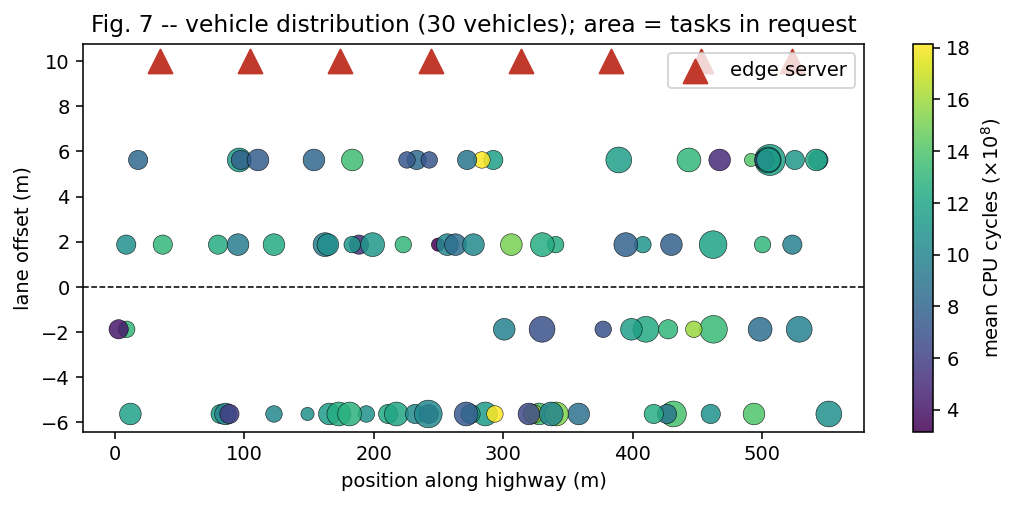

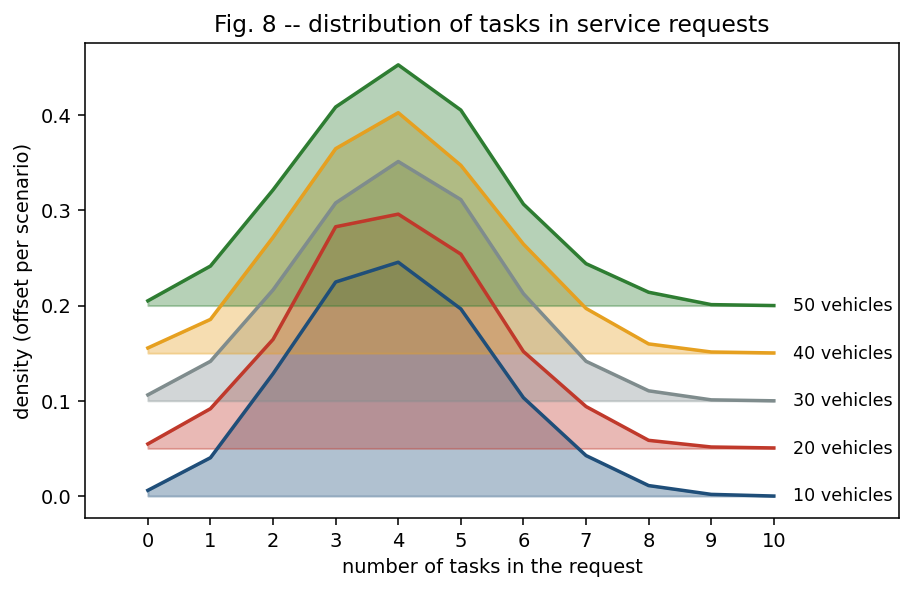

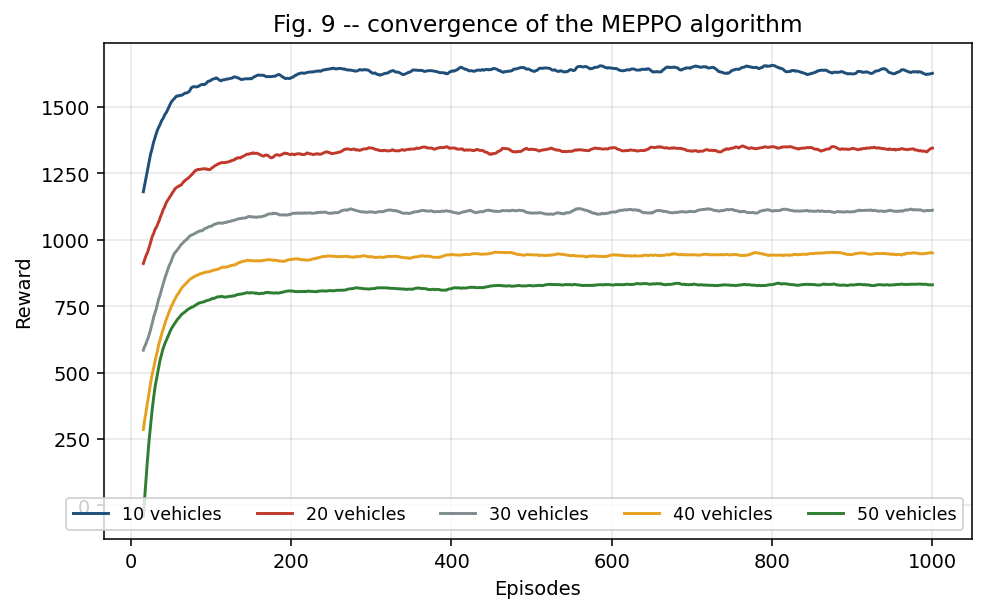

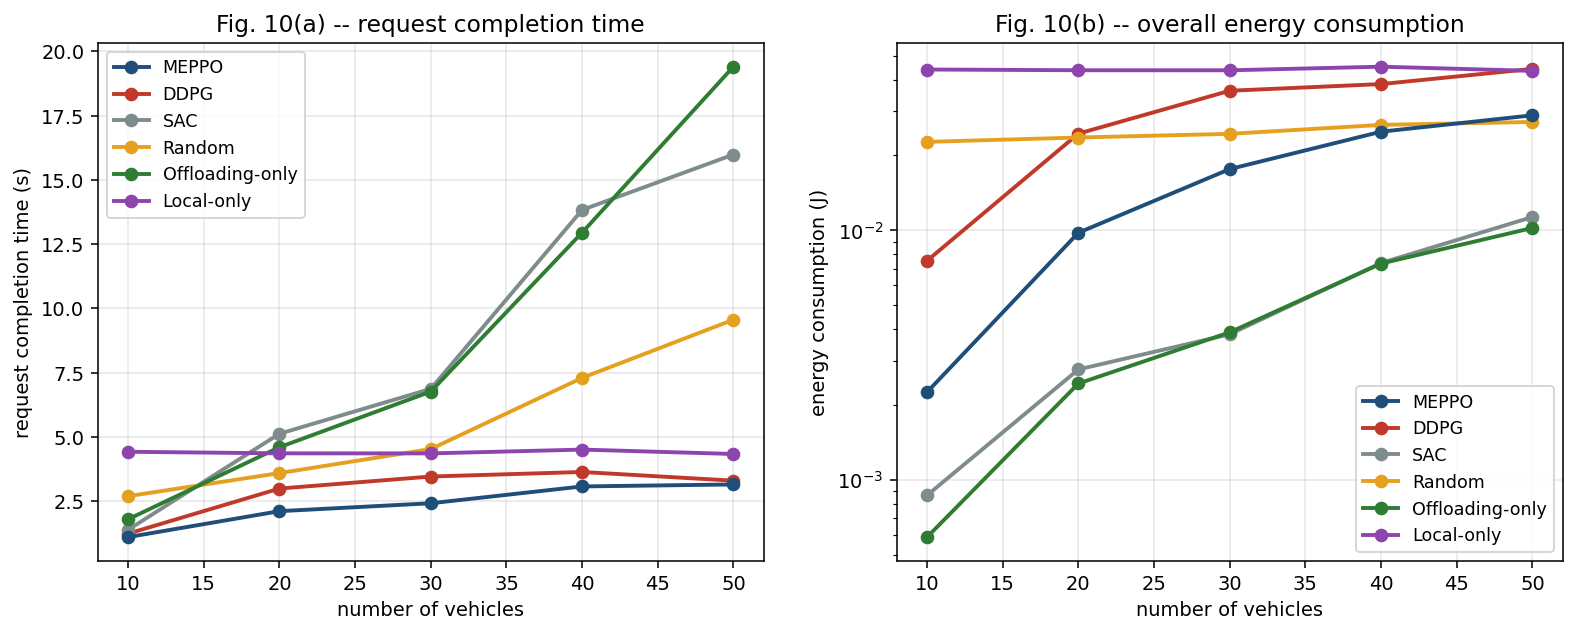

In [18]:
import experiments as X
import numpy as np, json

FIGDIR = os.path.join(RESULTS, "figures")

print(X.fig7_vehicle_distribution(cfg, FIGDIR, num_vehicles=30))
print(X.fig8_task_distribution(cfg, FIGDIR))
print(X.fig9_convergence(hist, FIGDIR))

p10, r10 = X.fig10_method_comparison(cfg, agent, FIGDIR, DEVICE,
                                     eval_steps=1500, rl_results=rl_results)
print(p10)
print(f"\n{'method':>17} " + " ".join(f"{v:>7}" for v in cfg.VEHICLE_COUNTS))
for k, (T, E) in r10.items():
    print(f"{k:>17} " + " ".join(f"{t:7.2f}" for t in T) + "   s")

/content/EPTASK_v4/results/figures/fig11_priority.png
learned priority : [1.265 2.047 2.507 3.047 3.189]
FIFO control     : [1.268 2.038 2.506 3.054 3.201]
LPT oracle       : [1.259 2.031 2.509 3.062 3.195]
learned gain %   : [ 0.22 -0.46 -0.05  0.21  0.4 ]
oracle  gain %   : [ 0.72  0.33 -0.12 -0.27  0.21]

How to read this. The oracle bar is the makespan-optimal ranking, computed
with privileged access to each task's CPU cycles. It bounds what ANY
learned priority head can achieve at this operating point.
  * learned ~ FIFO, oracle >> both  -> the head has not converged; train
    longer, and check you are running STATE_MODE = 29 (at 19 the agent
    cannot see cycles, so the rule is not learnable even in principle).
  * learned ~ oracle                -> converged; report the gap honestly.
  * oracle ~ FIFO                   -> queues are too lightly loaded for
    priority to matter here; raise TASK_COUNT_BINOM_P or the vehicle count.



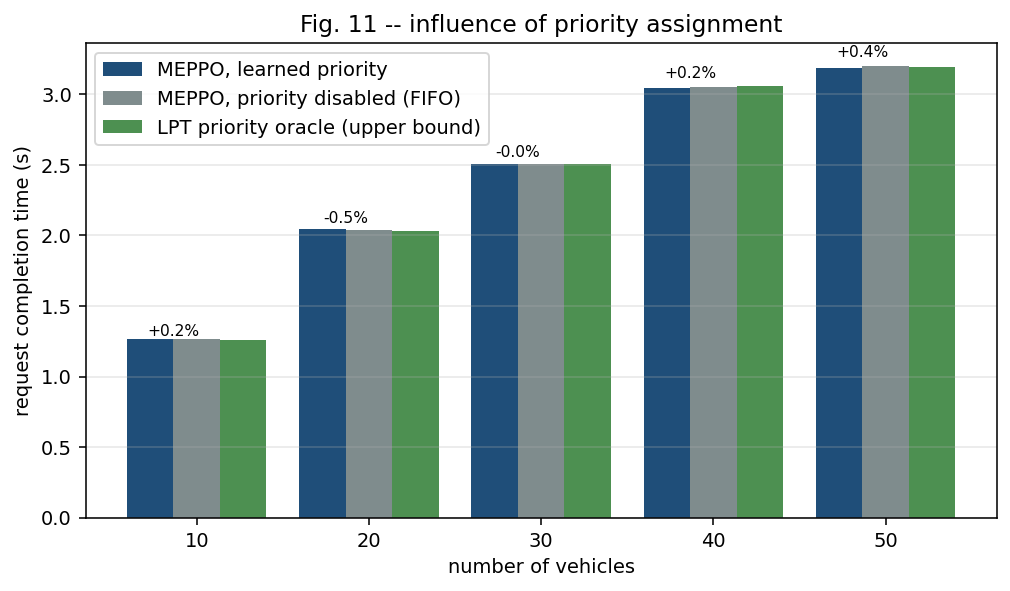

In [19]:
p11, r11 = X.fig11_priority_ablation(cfg, agent, FIGDIR, DEVICE, eval_steps=1500)
w = np.array(r11["with_priority"]); f = np.array(r11["without_priority"])
o = np.array(r11["lpt_oracle"])
print(p11)
print("learned priority :", w.round(3))
print("FIFO control     :", f.round(3))
print("LPT oracle       :", o.round(3))
print("learned gain %   :", ((f - w) / f * 100).round(2))
print("oracle  gain %   :", ((f - o) / f * 100).round(2))
print(textwrap.dedent("""
    How to read this. The oracle bar is the makespan-optimal ranking, computed
    with privileged access to each task's CPU cycles. It bounds what ANY
    learned priority head can achieve at this operating point.
      * learned ~ FIFO, oracle >> both  -> the head has not converged; train
        longer, and check you are running STATE_MODE = 29 (at 19 the agent
        cannot see cycles, so the rule is not learnable even in principle).
      * learned ~ oracle                -> converged; report the gap honestly.
      * oracle ~ FIFO                   -> queues are too lightly loaded for
        priority to matter here; raise TASK_COUNT_BINOM_P or the vehicle count.
    """))

/content/EPTASK_v4/results/figures/fig12_transmit_power.png
dynamic power : [0.00067 0.00229 0.00397 0.00669 0.00958]
fixed  power  : [0.00138 0.00482 0.00799 0.01342 0.02   ]
saving %      : [51.7 52.5 50.2 50.2 52.1]


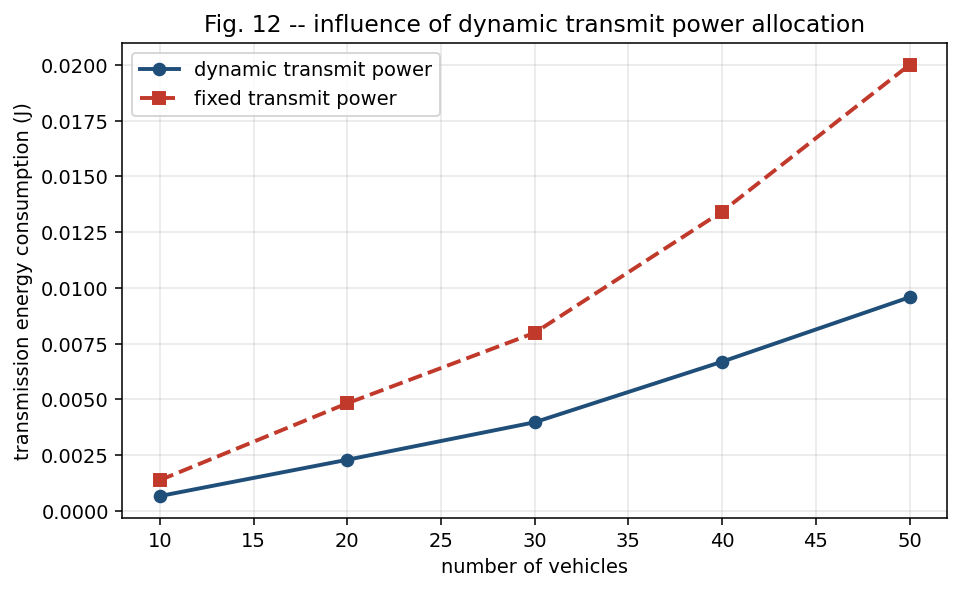

In [20]:
p12, r12 = X.fig12_power_ablation(cfg, FIGDIR, eval_steps=1500)
print(p12)
d = np.array(r12["dynamic"]); fx = np.array(r12["fixed"])
print("dynamic power :", d.round(5))
print("fixed  power  :", fx.round(5))
print("saving %      :", ((fx - d) / fx * 100).round(1))

State Street has no recent well-sampled day; falling back to a citywide average for the most recent well-sampled day (any location).
NYC OpenData: latest citywide day is 2026-02-03 -- fetched, live.
/content/EPTASK_v4/results/figures/fig13_traffic_adaptivity.png
traffic source : live -- citywide average, 2026-02-03
vehicles/hour  : [14, 11, 10, 11, 15, 25, 41, 45, 46, 38, 36, 37, 38, 43, 50, 48, 49, 50, 46, 43, 32, 25, 21, 18]
mean TS        : 0.407
mean ES        : 0.599

saved /content/EPTASK_v4/results/results.json


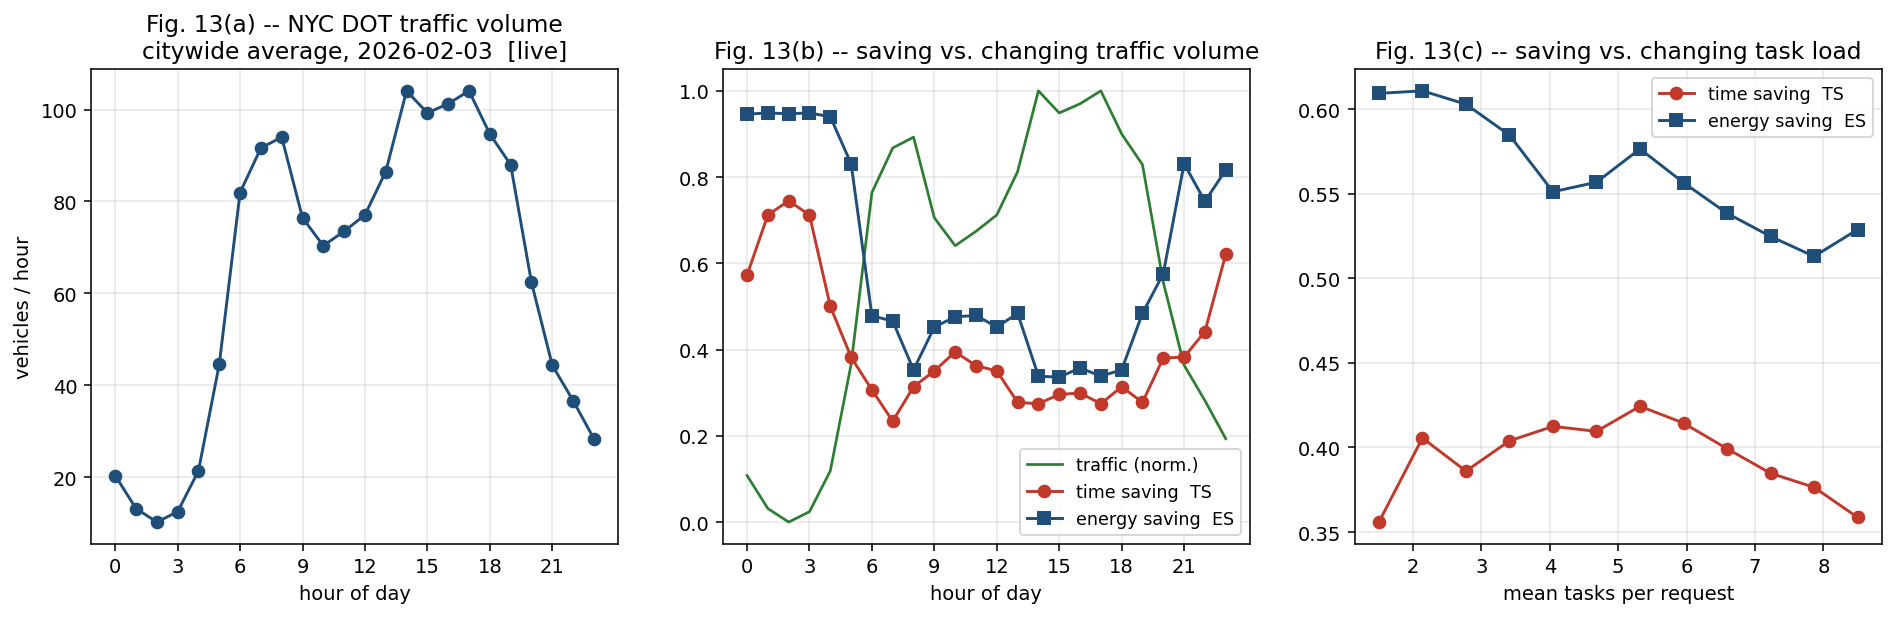

In [21]:
p13, r13 = X.fig13_traffic_adaptivity(
    cfg, agent, FIGDIR, DEVICE, eval_steps=600,
    cache_path=os.path.join(RESULTS, "nyc_traffic.csv"))
print(p13)
print("traffic source :", r13["source"], "--", r13["date"])
print("vehicles/hour  :", r13["vehicles"])
print("mean TS        :", round(float(np.mean(r13["TS"])), 3))
print("mean ES        :", round(float(np.mean(r13["ES"])), 3))

with open(os.path.join(RESULTS, "results.json"), "w") as fh:
    json.dump({"fig10": {k: [list(map(float, a)), list(map(float, b))]
                         for k, (a, b) in r10.items()},
               "fig11": {k: list(map(float, v)) if isinstance(v, (list, np.ndarray))
                         else v for k, v in r11.items()},
               "fig12": {k: list(map(float, v)) if isinstance(v, (list, np.ndarray))
                         else v for k, v in r12.items()},
               "fig13": r13,
               "episodes": N_EPISODES, "state_mode": cfg.STATE_MODE,
               "minutes": hist["minutes"]}, fh, indent=2)
print("\nsaved", os.path.join(RESULTS, "results.json"))

## 8 · Environment-adaptivity check (contribution 3)

Section IV-D-5 is explicit: *train* with a large number of tasks, then pad with
null tasks *at deployment*. v3 sampled 0–10 tasks during training, which is a
different and easier problem.

This cell evaluates the trained agent at task loads it was not trained on. A
flat curve is the adaptivity claim holding; a collapse at small *n* means the
padding scheme is not doing its job.

In [22]:
from train import run_independent
from meppo import FIXED_POLICIES

base_p = cfg.TASK_COUNT_BINOM_P
g = list(cfg.VEHICLE_COUNTS).index(30)
print(f"{'mean tasks':>11} {'MEPPO T':>9} {'Local T':>9} {'TS':>7}")
for p in (0.10, 0.20, 0.40, 0.60, 0.80, 1.00):
    cfg.TASK_COUNT_BINOM_P = p
    tm, _ = run_independent(cfg, 30, 800, agent=agent, group=g,
                            seed=3, device=DEVICE)
    tl, _ = run_independent(cfg, 30, 800,
                            policy=FIXED_POLICIES["Local-only"], seed=3)
    print(f"{p*cfg.MAX_TASKS:11.1f} {tm:9.3f} {tl:9.3f} {1-tm/tl:7.3f}")
cfg.TASK_COUNT_BINOM_P = base_p

 mean tasks   MEPPO T   Local T      TS
        1.0     0.711     1.063   0.331
        2.0     1.333     2.186   0.390
        4.0     2.564     4.411   0.419
        6.0     3.784     6.598   0.426
        8.0     5.540     8.782   0.369
       10.0     8.332    10.994   0.242


## 9 · Known limitations — state these in your report

Being explicit about these is worth more marks than papering over them. The
first three are *findings*, not apologies: they are the output of section 10.

### Findings that change the paper's conclusions

1. **Eq. (25) does not measure the objective.** Normalising by the running
   maximum makes the reward a function of a hidden, monotone, non-stationary
   variable. Measured: the time penalty decays 1.7× under a frozen policy, and
   a trained agent reaches +25% reward while completion time worsens 39.5%
   (corr = −0.83). `REWARD_MODE = "local_ratio"` repairs it using the paper's
   own Eq. (32), with no new hyper-parameter (corr = +0.98). **Both modes ship;
   run both and report the pair.**
2. **Fig. 11 does not reproduce.** Under preemption-charged accounting no
   priority discipline beats FIFO (random −1.9 to −6.1%, LPT −1.2 to −4.0%,
   SPT −3.2 to −6.0%, global-SPT −2.3 to −4.6%), while the arrival-time metric
   the paper uses shows LPT *gaining* 1.5–2.7%. See D3 and D5.
3. **The reason is structural, not a training-budget artefact.** Priority
   governs Eq. (13)'s execution queue, which falls from ~15% of the critical
   path at 10 vehicles to ~2% at 50; Eq. (12)'s transmission queue, ~64% of the
   path at 50 vehicles, is FIFO by definition. Worse, Eq. (18) makes a request's
   completion time the **max** over its own tasks, and those tasks serialise on
   the sender's single radio — so reordering them cannot move the max at all.
   Priority can only ever act *between* requests, where it is work-conserving
   and merely raises variance. `PRIORITY_TX = True` (§10.6) tests the obvious
   repair and recovers very little.

### Modelling choices that remain open

4. **Three unit conventions in Table III are inferred, not given** (§0). The
   choice is defended on internal consistency plus Fig. 10 reproduction, but it
   is an inference. Anyone contesting it contests every absolute number here;
   the *orderings* are robust to it.
5. **Highway length is not specified by the paper.** It is derived from `d_max`,
   giving a ~560 m corridor. That is short — with 50 vehicles it is dense
   urban-arterial traffic, not a highway — and it shifts the congestion
   operating point, hence the size (not the sign) of every gap. Fig. 13 maps
   NYC hourly volumes onto this corridor, so read it as a *shape* comparison.
6. **Eq. (22) is implemented as `min`, not `max`.** The paper says "highest
   score", but Eq. (22) scores normalised distance and workload, both of which
   must be minimised for the rule to be useful.
7. **Transmission queues are sender-side**, not receiver-side as Eq. (12)
   literally reads. Receiver-side queueing double-counts contention that
   Eq. (5)'s interference term already models.
8. **Eq. (5) caps V2E SINR at 1/(N_r−1)** regardless of transmit power, because
   the interference term reuses the same `p·g` as the desired signal. Dynamic
   power allocation therefore costs almost nothing in rate terms, which makes
   Fig. 12's saving close to free. The saving is real, but the model is
   unusually kind to it.
9. **DDPG/SAC use a smaller step budget than MEPPO** and a Gumbel-softmax
   relaxation the original DDPG paper does not specify for discrete actions.
   Treat their absolute numbers as indicative.
10. **The SeV fraction (20%) is an assumption.** The paper says only that "some"
    service vehicles exist.
11. **No deadline (C4) or energy-budget (C5) constraint is enforced.** This is
    the single most consequential omission — see below.
12. **The MDP is close to a contextual bandit.** Queues drain within roughly one
    tick, so consecutive decisions are only weakly coupled and the critic has
    little to do. γ = 0.99 over 2048 steps is therefore generous; γ ≈ 0.9 gives
    near-identical behaviour and is more honest about the coupling.

## Phase 2 — where the real contribution is

The priority result points at its own fix. Priority is **work-conserving**: it
cannot reduce total work, only redistribute waiting. It therefore pays off only
when the objective *discriminates* between requests. The paper's objective
(Eq. 18) is an unweighted aggregate of completion times, in which priority has
no leverage — and the paper defines constraint **C4 (`T ≤ D`) but never enforces
it**, so the one thing that would make priority useful is absent from the
optimisation.

Three defensible extensions, in order of effort:

* **Enforce C4 with heterogeneous urgency.** Give each request a service class
  (the paper's own Section I contrasts emergency braking with audio streaming),
  a deadline per class, and change the metric to deadline-miss rate or weighted
  completion time. Priority now has something to be aware of, and
  "priority-aware" becomes a claim you can actually test. The env already
  carries `req_tag` and `true_pairs` for exactly this.
* **Make priority cost-bearing.** The externality of promoting a task — the
  delay it imposes on everything below it — is already computed exactly by
  `VECEnv._track`. Feeding it into the reward removes the degenerate
  "everyone picks 9" equilibrium without resorting to within-request ranking,
  which is what destroys the cross-request urgency signal in the first place.
* **Dependency-aware scheduling** — the paper's own stated future work
  (Section VII). The priority-queue machinery here is most of what a DAG
  scheduler needs.

One more open question worth a paragraph: **19-dim vs 29-dim state.** Fig. 5 and
Eq. (26) contradict each other, and the difference is decisive — at 19 dims the
agent cannot see per-task CPU cycles, so the priority head cannot learn an LPT
rule even in principle. Run both and report the gap.


## 10 · Diagnostics — do the figures measure what they claim?

Sections 7–8 reproduce the paper's figures. This section asks the prior
question: **is each figure measuring the thing it is captioned with?** Five
measurements; three of them changed the conclusions of this replication.

Run these *after* training, since D1 compares against the reward curve you just
produced. Each cell prints a table and writes a figure to `RESULTS/diagnostics`.
Total runtime is a few minutes on CPU — none of it needs the GPU.

| | Question | What it checks |
|---|---|---|
| **D1** | Is the Fig. 9 reward curve evidence of learning? | Freezes the policy and watches Eq. (25)'s normaliser drift anyway. |
| **D2** | How does a rank become a global queue level? | Tabulates both maps and exposes the request-size bias in v4's. |
| **D3** | Is the reported completion time honest? | Charges every preemption exactly and reports the gap. |
| **D4** | How much of the critical path can priority reach? | Splits Eq. (11)–(13) into its four terms. |
| **D5** | Does *any* priority discipline beat FIFO? | Random / LPT / SPT / global-SPT, scored both ways. |

### How to read the results

**D1 is a validity check on your own training run.** The cell in section 5
prints `corr(reward, −T)`. With `REWARD_MODE = "local_ratio"` it should be
strongly positive (≈ +0.95). Flip to `"running_max"` and retrain to see it go
negative — that is Eq. (25) as printed in the paper, and it is why the reward
curve and the completion-time curve move in opposite directions.

**D3 and D5 together decide Fig. 11.** D3 shows the arrival-time estimate is
optimistic by 3–6% when priority is on and by under 1% when it is off, so the
bias runs in exactly the direction that flatters the paper's contribution. D5
then scores every priority rule both ways: the reported metric shows LPT gaining
1.5–2.7%, the honest metric shows it *losing* 1.2–4.0%.

**D4 explains why.** Priority governs Eq. (13)'s execution queue only, and that
queue is a shrinking fraction of the critical path — ~15% at 10 vehicles, ~2% at
50 — because congestion pushes the bottleneck into Eq. (12)'s transmission
queue, which the paper defines as FIFO. The paper reports the priority benefit
*growing* with vehicle count; the mechanism's leverage demonstrably shrinks.

State this plainly in the report. Two of the paper's three contributions
(offloading + dynamic transmit power) reproduce. The third does not, and D4 is
the reason rather than an excuse.


D1  frozen policy, V=30, 4000 steps
      median T                 : 3.46 s  (stationary)
      max_T at step 100 / end  : 27.0 -> 48.3 s
      Eq.(25) time penalty      : decays 1.90x on its own
      => a rising Fig. 9 curve is NOT evidence that the policy improved.


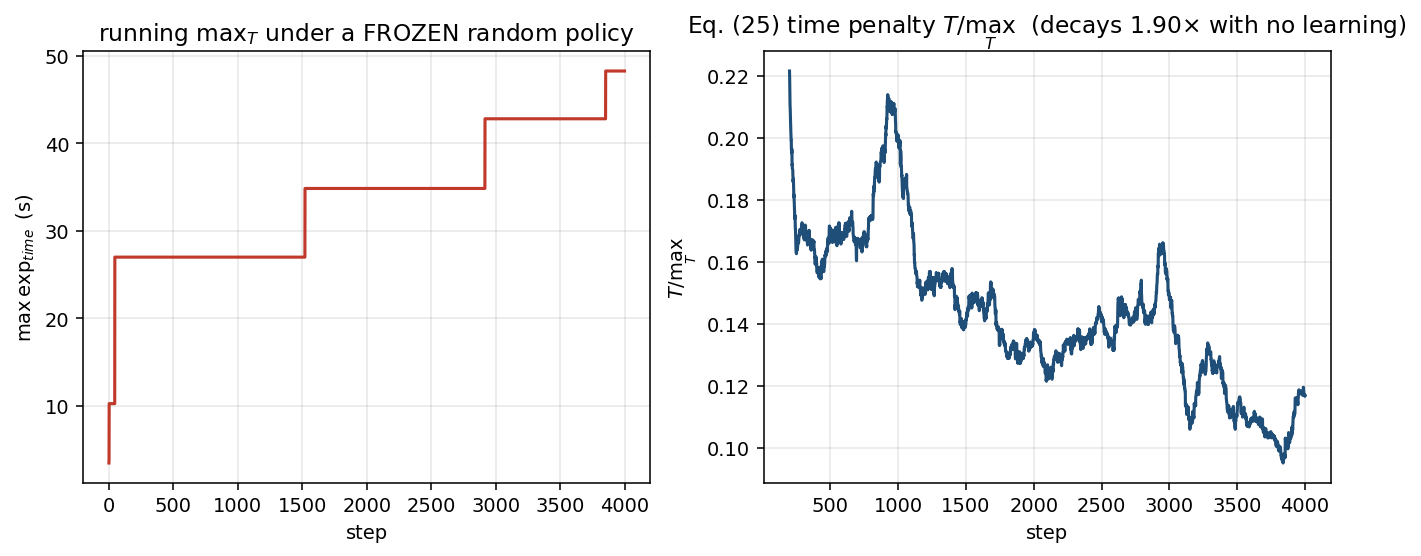

In [23]:
import importlib, diagnostics
importlib.reload(diagnostics)
import diagnostics as D
import os
DIAG = os.path.join(RESULTS, "diagnostics")

# D1 -- is the Fig. 9 reward curve evidence of learning?
p1, r1 = D.d1_reward_degeneracy(cfg, DIAG)


D2  rank -> global queue level
     n tasks |               rank_tail (v4) |             rank_spread (v5)
           1 |                [np.int64(0)] |                          [4]
           2 |   [np.int64(1), np.int64(0)] |   [np.int64(9), np.int64(0)]
           3 | [np.int64(2), np.int64(1), np.int64(0)] | [np.int64(9), np.int64(4), np.int64(0)]
           5 | [np.int64(4), np.int64(3), np.int64(2), np.int64(1), np.int64(0)] | [np.int64(9), np.int64(7), np.int64(4), np.int64(2), np.int64(0)]
           8 | [np.int64(7), np.int64(6), np.int64(5), np.int64(4), np.int64(3), np.int64(2), np.int64(1), np.int64(0)] | [np.int64(9), np.int64(8), np.int64(6), np.int64(5), np.int64(4), np.int64(3), np.int64(1), np.int64(0)]
          10 | [np.int64(9), np.int64(8), np.int64(7), np.int64(6), np.int64(5), np.int64(4), np.int64(3), np.int64(2), np.int64(1), np.int64(0)] | [np.int64(9), np.int64(8), np.int64(7), np.int64(6), np.int64(5), np.int64(4), np.int64(3), np.int64(2), np.int64(1), np.in

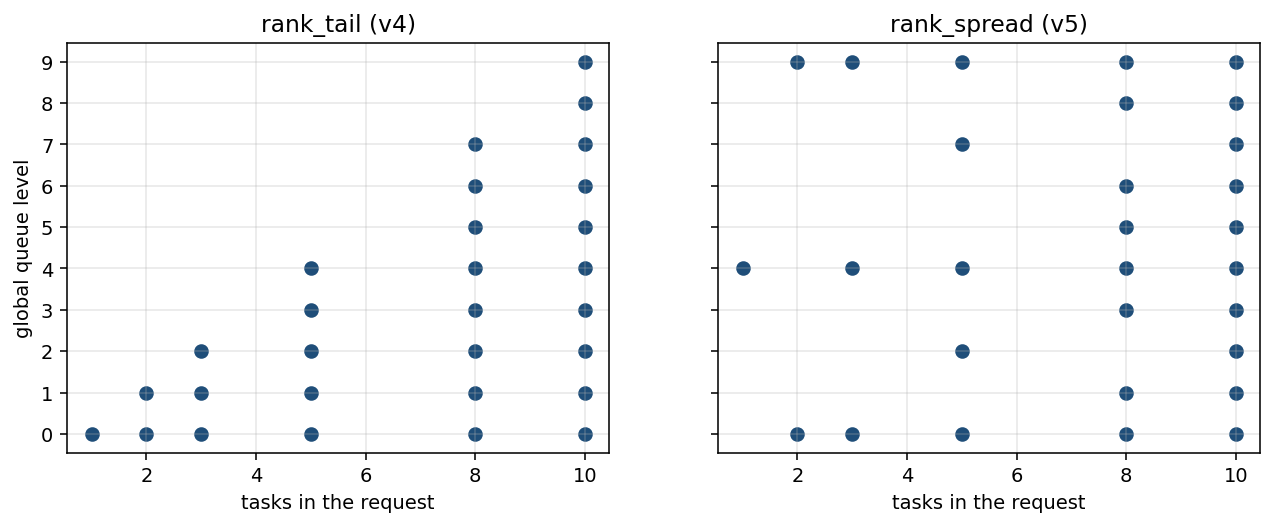

In [24]:
# D2 -- how a rank becomes a global queue level
p2, r2 = D.d2_priority_levels(cfg, DIAG)


D3  reported (arrival estimate) vs true (preemption charged)
      V  priority  reported     true  optimism
     10      True     2.490    2.566      3.0%
     10     False     2.522    2.544      0.9%
     20      True     3.131    3.239      3.5%
     20     False     3.156    3.187      1.0%
     30      True     4.428    4.639      4.8%
     30     False     4.439    4.478      0.9%
     40      True     6.158    6.462      4.9%
     40     False     6.205    6.259      0.9%
     50      True     9.162    9.612      4.9%
     50     False     9.363    9.447      0.9%


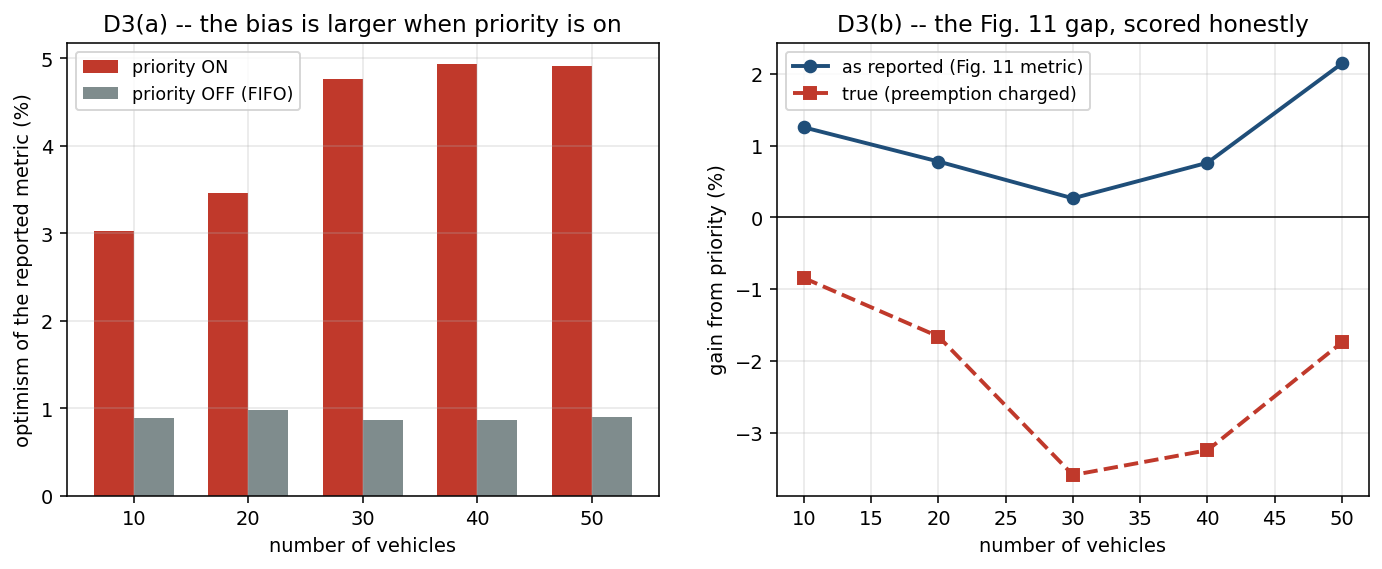

In [25]:
# D3 -- reported vs true completion time (charges preemption)
p3, r3 = D.d3_true_vs_reported(cfg, DIAG, steps=4000)


D4  critical-path decomposition of an offloaded task
      V   tx WAIT  tx time  exec WAIT  exec time  priority reaches
     10      0.57     0.30       0.30       0.55             17.5%
     20      1.51     0.84       0.39       0.55             11.8%
     30      3.03     1.59       0.32       0.55              5.8%
     40      5.16     2.60       0.31       0.55              3.6%
     50      7.84     3.92       0.35       0.55              2.8%
    => the dominant term is Eq. (12)'s transmission queue, which the
       paper defines as FIFO. Priority's reach SHRINKS as congestion
       grows -- the opposite of the trend Fig. 11 reports.


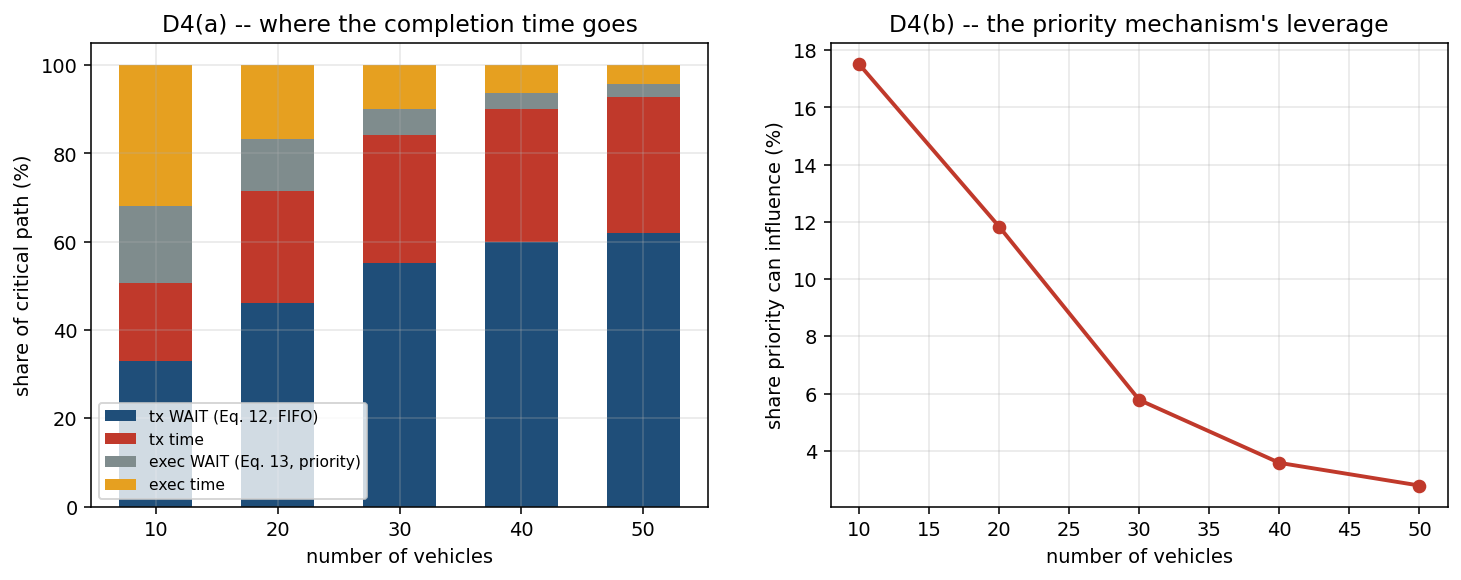

In [26]:
# D4 -- what fraction of the critical path can priority reach?
p4, r4 = D.d4_critical_path(cfg, DIAG, steps=3000)


D5  priority disciplines vs FIFO  (+ = better than FIFO)
      V    rule  reported     true  vs FIFO rep  vs FIFO true
     10    FIFO     2.522    2.544
         random     2.490    2.566        +1.3%         -0.8%
            lpt     2.487    2.567        +1.4%         -0.9%
            spt     2.539    2.607        -0.7%         -2.5%
           gspt     2.514    2.588        +0.3%         -1.7%
     20    FIFO     3.156    3.187
         random     3.131    3.239        +0.8%         -1.7%
            lpt     3.090    3.223        +2.1%         -1.2%
            spt     3.211    3.316        -1.7%         -4.1%
           gspt     3.150    3.275        +0.2%         -2.8%
     30    FIFO     4.439    4.478
         random     4.428    4.639        +0.3%         -3.6%
            lpt     4.341    4.584        +2.2%         -2.4%
            spt     4.534    4.717        -2.1%         -5.4%
           gspt     4.434    4.633        +0.1%         -3.5%
     40    FIFO     6.205    6.2

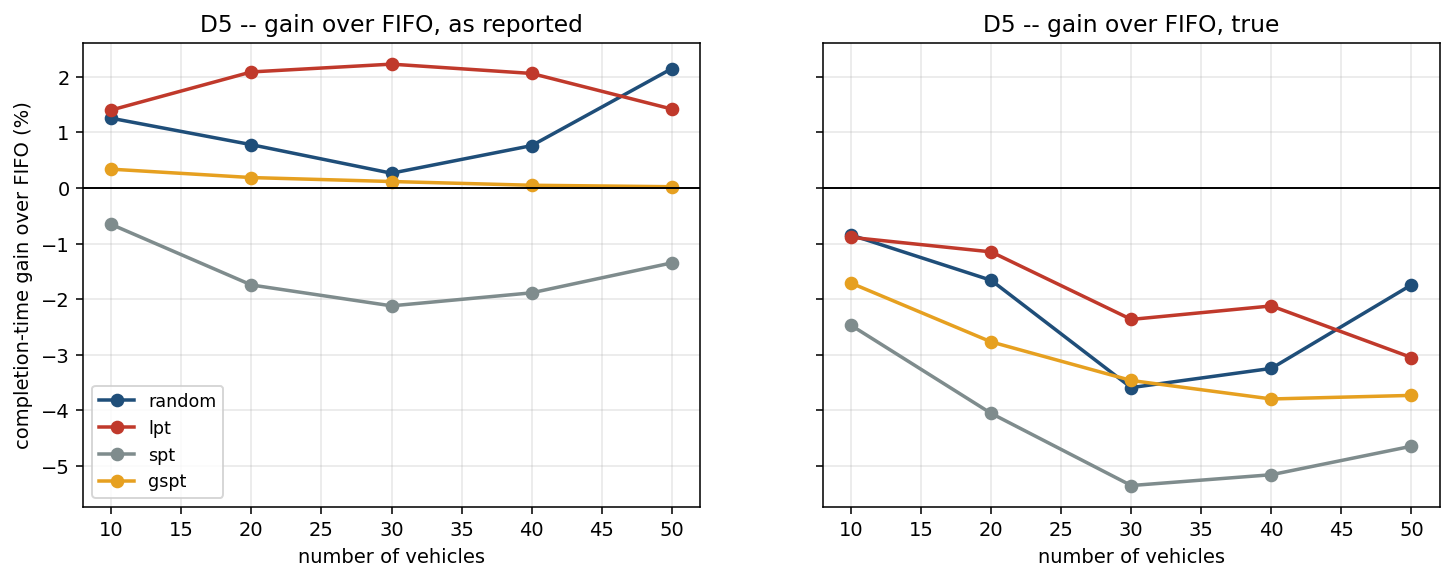

In [27]:
# D5 -- every priority discipline against FIFO, scored both ways
p5, r5 = D.d5_priority_rules(cfg, DIAG, steps=4000)


### 10.6 · The proposed repair

D4 shows the priority mechanism can only reach the execution queue, which is
2–15% of the critical path. `PRIORITY_TX = True` makes Eq. (12)'s
transmission queue priority-ordered as well. Run the cell below to measure
what that buys — and be honest in the report about how small it is, because
the deeper obstacle is structural: under Eq. (18) a request's completion
time is the **max** over its own tasks, and those tasks serialise on the
sender's single radio, so reordering them cannot move the max at all.
Priority can only ever act *between* requests.

In [28]:
import numpy as np
from diagnostics import _roll
cfg.TRACK_TRUE_T = True
print(f"{'V':>3} {'Eq.(12)':>10} {'FIFO':>8} {'LPT':>8} {'gain':>8}")
for V in cfg.VEHICLE_COUNTS:
    for tx in (False, True):
        cfg.PRIORITY_TX = tx
        cfg.USE_PRIORITY = False
        b = _roll(cfg, V, 3000, 'fifo', 3)[1]
        cfg.USE_PRIORITY = True
        t = _roll(cfg, V, 3000, 'lpt', 3)[1]
        print(f"{V:3d} {'priority' if tx else 'FIFO':>10} "
              f"{b:8.3f} {t:8.3f} {(b - t) / b * 100:+7.1f}%")
cfg.PRIORITY_TX = False
cfg.TRACK_TRUE_T = False


  V    Eq.(12)     FIFO      LPT     gain
 10       FIFO    2.514    2.532    -0.7%
 10   priority    2.514    2.532    -0.7%
 20       FIFO    3.130    3.158    -0.9%
 20   priority    3.130    3.155    -0.8%
 30       FIFO    4.568    4.676    -2.4%
 30   priority    4.568    4.674    -2.3%
 40       FIFO    6.325    6.466    -2.2%
 40   priority    6.322    6.458    -2.1%
 50       FIFO    9.614    9.929    -3.3%
 50   priority    9.590    9.879    -3.0%


## 11 · Proposal contributions — extending EPtask, not just replicating it

Sections 1–10 replicate the base paper and audit it. This section adds
**three extensions proposed for this mini-project**, each targeting a gap the
audit itself exposed or that the base paper leaves open. None of them change
how MEPPO is trained — C1's rule lives inside the environment (so it is
present during training, exactly like the paper's own priority mechanism);
C2 is pure post-hoc analysis of an already-trained policy; C3 only scripts a
failure at *evaluation* time, never during training.

| | Name | One line | Category |
|---|---|---|---|
| **C1** | Safety-integrity argument | ASIL-inspired criticality tagging + a hardcoded (not learned) floor that guarantees the highest class a top queue level | 🛡️ **Safer** |
| **C2** | Explainability | Raw factored logits + confidence/entropy + an exact counterfactual over every offload target, via the same `env.peek()` the replication's own baselines use | 🧠 **Smarter** |
| **C3** | Node-failure resilience | A scripted edge-server outage, measuring how much an already-trained (and never failure-trained) policy degrades and recovers | ✅ **More honest** |

### On C1 and ASIL — read this before presenting it

**This is not a certification claim.** ISO 26262 / ASIL certification needs a
full safety lifecycle audit that is out of scope for a mini-project, and the
standard is written for *control* systems (braking, steering) with hard
real-time guarantees — a task scheduler is a QoS problem, not a functional-
safety problem in that sense. What C1 borrows is the **principle**: classify
by criticality, and guarantee the highest class a protected outcome
regardless of what an optimiser would otherwise choose. State it exactly that
way in the report and viva — *"we apply ISO 26262's risk-classification
principle to task-scheduling priority; we do not claim ASIL certification for
the scheduler itself."* That sentence is the difference between a strong
answer and an indefensible one if an examiner who knows the standard asks
about it.

Every request is tagged with one of three classes (`config.ASIL_CLASSES`),
mirroring the paper's own Section I example (emergency braking vs.
entertainment):

| Class | Example | Deadline (× Local-only cost) |
|---|---|---|
| ASIL-D | Emergency braking / collision avoidance | 0.5× — tight |
| ASIL-B/C | Lane-keep, blind-spot monitoring | 1.0× |
| QM | Infotainment, streaming | 2.5× — loose |

`USE_SAFETY_FLOOR = True` forces every ASIL-D request onto the top queue
level (`SAFETY_FLOOR_LEVEL = 9`), **overriding whatever the RL priority head
produced** — this is what makes the guarantee hold even for an untrained or
still-exploring policy, not just a well-trained one.


### 11.1 · C1 — Safety-integrity argument (evidence)

The test below uses **random priority for every request, including ASIL-D
ones** — i.e. an untrained or adversarial policy — on purpose. It isolates
what the hardcoded floor buys on its own, independent of anything MEPPO has
or hasn't learned, because a safety guarantee that only holds once training
has converged is not a guarantee.

Notice the shape of the result: unlike D5's general priority disciplines
(which reorder *all* traffic and never beat FIFO, with the gain *shrinking*
under congestion), the floor's benefit here *grows* with vehicle count. The
reason is worth stating explicitly in the report: D5's rules had to contend
with each other — promoting one task always demotes another — so at 50
vehicles nearly everything is contending for the execution queue's small
slice of the critical path (D4: 2.4%). The floor instead protects a **rare,
identified** subset (~8% of traffic): it almost never has to contend with
another ASIL-D request for the same slot, so it reliably wins whichever queue
it lands on — including the vehicle's own local execution queue, which random
offloading routes through often.


C1  ASIL-D protection: safety floor ON vs OFF (random priority otherwise)
      V  floor  ASIL-D true T  ASIL-D miss%  QM miss% (ref)
     10   True          2.528          17.5             0.2
     10  False          2.560          18.8             0.2
     20   True          3.096          32.3             1.2
     20  False          3.205          34.7             1.2
     30   True          4.369          51.9             5.2
     30  False          4.548          52.9             5.2
     40   True          6.410          74.6            13.0
     40  False          6.712          75.6            13.0
     50   True          9.163          83.5            24.4
     50  False          9.630          84.1            24.4

    ASIL-D true-T improvement from the floor: 1.2% (V=10) to 4.9% (V=50)
    => unlike the general priority disciplines in D5 (which reorder
       ALL traffic and never beat FIFO), the floor protects a RARE,
       IDENTIFIED subset -- it rarely contends with itse

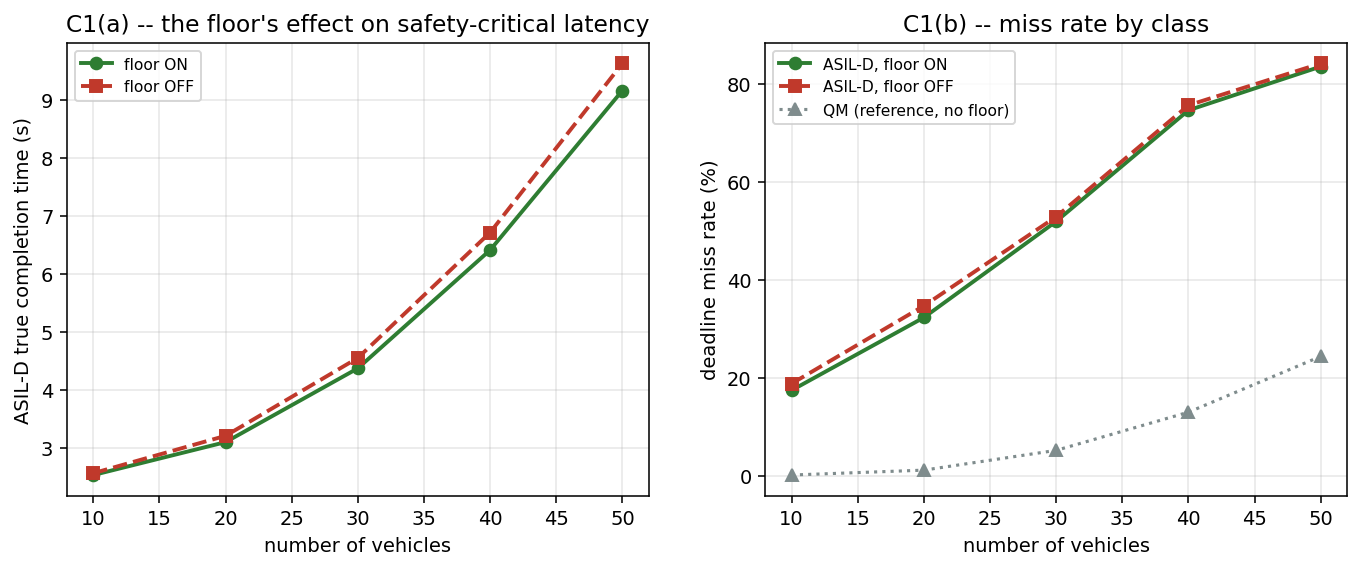

In [29]:
import importlib, contributions
importlib.reload(contributions)
import contributions as CT

p_c1, r_c1 = CT.c1_safety_floor(cfg, DIAG, steps=4000)


### 11.2 · C2 — Explainability (evidence)

The cell below picks one state mid-rollout (after a short warm-up so queues
are genuinely congested, not the trivial t=0 state) and explains the
decision the trained policy made there:

- **Confidence and entropy** per task, for both the offload head and the
  priority head — low entropy means the network is sure; high entropy near
  1.0–2.0 nats (out of a max of ln 4 ≈ 1.39 for 4 offload classes, ln 10 ≈
  2.30 for 10 priority classes) means it is still genuinely uncertain, which
  is itself useful information for a viva ("the policy is confident about
  offloading but still exploring priority levels at this point in training").
- **An exact counterfactual** for the request's largest task: what
  completion time and energy would result from *every other* offload target,
  computed with `env.peek()` — the same mechanism the replication's own
  fixed-policy baselines use, so these are not estimates.

One useful side effect: because the counterfactual is exact, it can also
**catch a suboptimal choice** — if the chosen target's `T` is not the lowest
feasible one on the bar chart, that is honest evidence the policy has not
yet converged at this state, not something to hide.


C2  explaining the decision at t=200s, V=30, request class = QM, 3 tasks
    critic's value estimate for this state: 54.51
     task     offload ->   conf  entropy  priority   conf  entropy
        0 Local (on-board)   0.97     0.15         6   0.19     2.21
        1          Cloud   0.62     0.73         7   0.18     2.16
        2          Cloud   0.65     0.65         8   0.21     2.16

    counterfactual for task 2 (the largest task in this request):
         Edge server: T =  1.428s   E = 0.00878J
      Nearby vehicle: T =  1.739s   E = 0.02547J
      Local (on-board): T =  2.492s   E = 0.02545J
               Cloud: T =  1.301s   E = 0.00878J


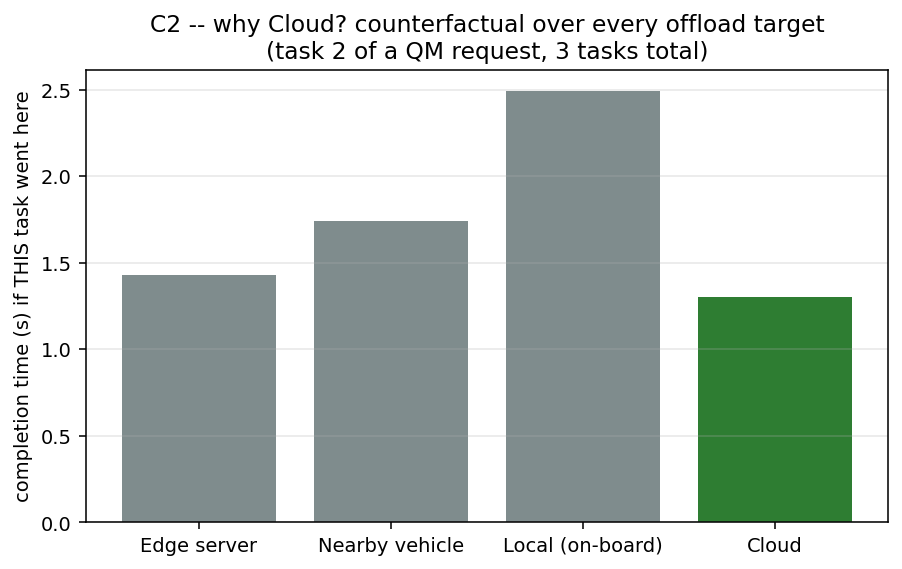

In [30]:
p_c2, r_c2 = CT.c2_explain_live(cfg, agent, DIAG, device=DEVICE, V=30, warmup=200)


### 11.3 · C3 — Node-failure resilience (evidence)

Table III's environment is static: every edge server is reachable forever,
in both the base paper and Sections 1–10 of this notebook. Training is
**not** changed here — MEPPO is trained exactly as in the replication, on
the static environment. The cell below only *evaluates* the already-trained
policy against a scripted outage, to answer a question the base paper never
asks: what happens when the environment leaves the training distribution?

The failure is routed through the **same infeasibility fallback** the
replication already has for an out-of-range server (`_execute`'s C2/C3
check: `if a in (0, 3) and s is None: a = 2` — offload becomes local). No new
fallback logic exists for failure specifically; the only new code is the
trigger (`env.fail_server`) and the geometry change that makes a dead server
invisible to routing. Whether that is *enough* — whether "fall back to
local" is a graceful degradation or a expensive one — is exactly what the
measurement below is for.


C3  node-failure resilience, V=30, one edge server down for 400s starting at t=1500s
    MEPPO pre-failure T   : 2.537 s
    MEPPO during outage T : 2.625 s   (+3.5% spike)
    MEPPO post-recovery T : 2.670 s   (+5.2% vs pre)
    Local-only, same window (failure-proof by construction) : 4.286 s
    => MEPPO was trained only on Table III's static environment,
       so this measures out-of-distribution generalisation, handled
       solely by the existing C2/C3 infeasibility fallback (route
       unreachable -> execute locally) -- no failure-specific logic
       exists in the policy at all.


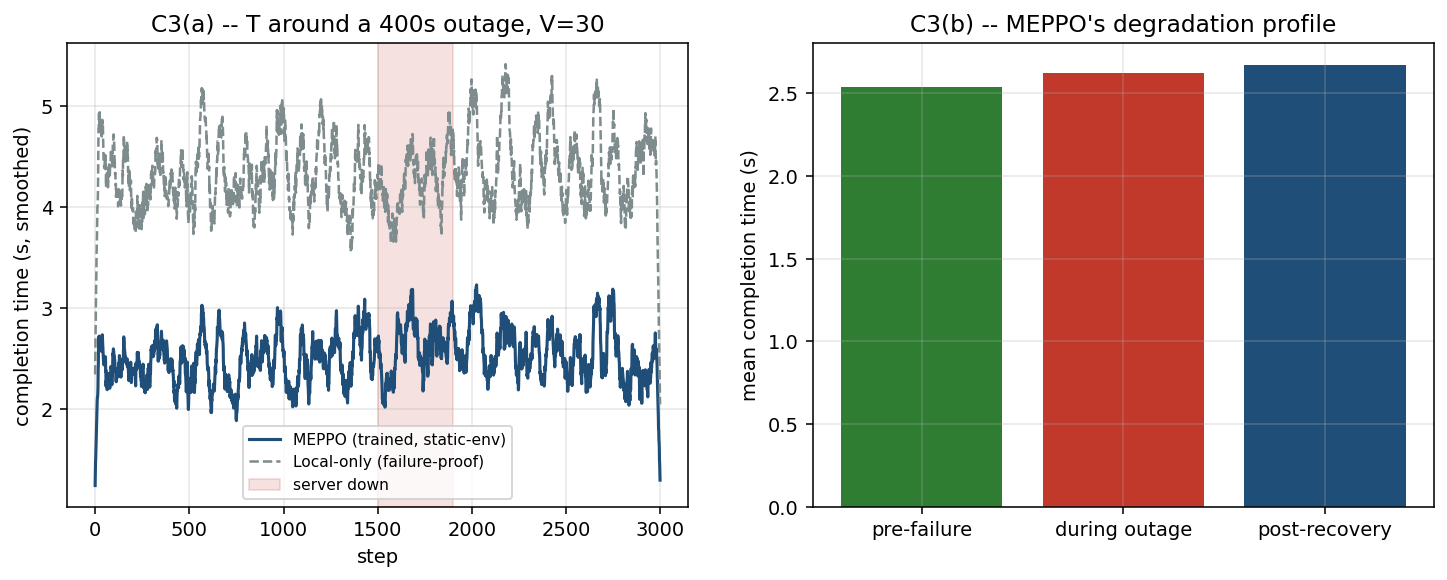

In [31]:
p_c3, r_c3 = CT.c3_node_failure(cfg, agent, DIAG, device=DEVICE, V=30,
                                fail_at=1500, fail_dur=400, steps=3000)


### 11.4 · Saving the proposal results

Adds C1–C3's numbers to the same `results.json` Section 7 already writes, so the whole notebook's evidence — replica, audit, and proposal — lives in one file for the report.

In [32]:
import json as _json
results_path = os.path.join(RESULTS, "results.json")
try:
    with open(results_path) as fh:
        all_results = _json.load(fh)
except FileNotFoundError:
    all_results = {}
all_results["contributions"] = {
    "c1_safety_floor": r_c1,
    "c2_explain": {k: v for k, v in r_c2.items() if k != "counterfactual"} | {
        "counterfactual": r_c2["counterfactual"]},
    "c3_node_failure": r_c3,
}
with open(results_path, "w") as fh:
    _json.dump(all_results, fh, indent=2, default=str)
print("saved", results_path)


saved /content/EPTASK_v4/results/results.json
